# 04 — Adaptive Planning

In Notebook 03 "Uncertainty Modelling", a series of analyses were carried out to evaluate how infrastructure stages/projects and plans perform in a set of scenarios, mainly looking at the end point performance (i.e., year 40). This Notebook 04 "Adaptive Planning" expands these analyses by including the temporal dimension (e.g., timing) of investments and performance. Therefore the main question this notebook helps analyse is **how should infrastructure be deployed over time when a scenario unfolds differently than expected?** It shows how static, predetermined staged and adaptive plans are defined, triggered and evaluated over the full 40-year horizon for the SBB MehrSpur case study. Like Notebooks 02 and 03, it is a demonstrative tutorial that you should adapt to your own case study.

As mentioned in the exercise sheets (and in the previous notebooks) you will be presented with different types of calculations and tasks:
- **Tutorials/Supporting task (optional):** building understanding but are not meant as report deliverable.
- **Mandatory/Expected task:** producing a definition, assumption, or result needed later in the project.
- **Advanced task (optional):** extends the model beyond the supplied example.


## Roadmap and learning objectives

The notebook follows one continuous argument: **define plans and triggers → turn uncertain endpoints into trajectories → validate the plan logic → compare shared scenarios → assess implementation and target attainment → identify tipping points and opportunities → discover vulnerable scenarios → synthesise pathways**. The five parts follow this argument:

1. [Define the planning problem](#planning-problem)
2. [Test the adaptive rules](#adaptive-rules)
3. [Compare plans across scenarios](#compare-plans)
4. [Diagnose failure and intervention needs](#diagnose-failure)
5. [Evaluate and improve implementation](#improve-implementation)

Check the Project Sheet Weeks 7-8 for the corresponding deliverables.

By the end of this notebook, you will be able to:
1. represent uncertain parameters as trajectories over time, not just Year-1/Year-40 endpoints;
2. compare static, staged, and adaptive plans in the context of the SBB MehrSpur project;
3. define monitoring indicators, triggers, lead times, and activation years for major railway expansions;
4. analyse outcome evolution over the full 40-year horizon;
5. distinguish central performance from robustness against explicit requirements;
6. identify adaptation tipping points and opportunity points;
7. explore vulnerable scenarios using PRIM for critical performance targets (e.g., maintaining the configured strategic PT passenger-km share);
8. design your own adaptive plan.

## Estimated time for Notebook 04

> - **Execution time:** the notebook reuses the response table prepared in Notebook 03, so no road assignment or GP training is run. The ensemble in Part 3 and the fixed-configuration runs in Part 4 evaluate every sampled scenario for several plans or configurations and can take several minutes.
> - **Reading and understanding:** allow approximately **2–3 hours** to work through the notebook without adapting it to your own case study.
> - **Case-study adaptation:** significant additional time is required to define and justify plans, monitoring indicators, thresholds and lead times, and to document decisions.
>
> Plan your work accordingly. Execution time does not include time spent reading, interpreting results, troubleshooting, or modifying the notebook.

## Scope

This notebook is **trajectory-based**: it follows every sampled scenario year by year over the 40-year horizon, instead of the Year-1/Year-40 snapshots used in Notebooks 02 and 03. It builds directly on the same infrastructure packages, the same uncertainty definitions and the same transport surrogate prepared in Notebook 03.

This notebook reports the present value of infrastructure expenditure: investment, upfront option premiums and operating expenditure, using the configured discount rate (default 2%). Notebook 05 will perform the economic appraisal, including monetised benefits and residual value.


## Setup

`code/adaptive_planning.py` defines the six plans, independent package triggers, lead times and annual pathways. It loads the surrogate and response table prepared in Notebook 03 from this project’s `data/processed/transport_surrogate/` folder; no training is run here.

The EMA Workbench samples all uncertainties marked `use="scenarios"` in `parameters.py`. `SCENARIO_UNCERTAINTIES = ALL` selects that default set; a list selects a subset and `[]` uses nominal paths. Omitted uncertainties retain their nominal values or paths. Uncertainties not modelled for scenarios but as valuation sensitivities are evaluated separately at the end of Notebook 05.

Part 1 illustrates the available timing patterns. At the end of Part 2, select one shape per transient uncertainty for the remaining analyses; unlisted uncertainties use linear paths.

The analysis settings below select indicators, requirements and temporary trigger overrides for this notebook. Trigger rules initiate a decision when the selected monitoring indicator **exceeds** its threshold. For a project without a counting section, choose ordinary corridor monitoring indicators such as `bike_trips`, `walk_trips` or `pt_trips`. Permanent plan definitions belong in `adaptive_planning.py`.

Figures and tables save immediately to `figures/04_adaptive_planning/` and `results/04_adaptive_planning/`. Reruns replace matching files. Set `SAVE_OUTPUTS = False` to disable exports. Interactive controls are not exported; their completed figures and tables are.

For another project, place this notebook in that project’s `notebooks/` folder. It uses the local network, package definitions and trained transport artifacts. The planning exercises use two independent packages and their four operating states. Choose project-specific requirements and monitoring rules in Section 1.2; without a counting section, use ordinary indicators such as `bike_trips` or `pt_trips`. The CSV exports from Notebook 03 are optional.


In [1]:
# Install the shared project requirements into the active notebook kernel
from pathlib import Path
_PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
%pip install --quiet -r "$_PROJECT_ROOT/requirements.txt"



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "code"))
(PROJECT_ROOT / "figures").mkdir(exist_ok=True)
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

import parameters as p
import simulation_engine as m
import adaptive_planning as ap
import stages as stages_module
from parameters import N_YEARS, STRUCTURAL_UNCERTAINTIES, NOMINAL_PARAMS
from additional import uncertainty as uc
from additional.uncertainty import ALL

# All registered scenario uncertainties; use a list for a subset or [] for nominal paths.
SCENARIO_UNCERTAINTIES = ALL
SCENARIO_NAMES = uc.select_uncertainties(SCENARIO_UNCERTAINTIES, use="scenarios")
SAMPLED_NAMES = [name for name in SCENARIO_NAMES if not uc.is_deterministic(name)]
TRANSIENT_NAMES = [name for name in SCENARIO_NAMES if p.STRUCTURAL_UNCERTAINTIES[name]["transient"]]
TRANSPORT_NAMES = uc.select_uncertainties(ALL, category="transport_modelling")
BUDGET_LABEL = "Present value of infrastructure expenditure (CHF)"
SHAPE_COLUMNS = {name: f"{name}__shape" for name in TRANSIENT_NAMES}

import transport_model_interface
from surrogate_model.transport_surrogate import load_transport_surrogate



from ema_workbench import (
    Model, RealParameter, CategoricalParameter, ScalarOutcome, TimeSeriesOutcome,
    SequentialEvaluator, perform_experiments, Samplers, Scenario,
)

try:
    from ema_workbench import Policy            # EMA Workbench 2.x
except ImportError:
    from ema_workbench import Sample as Policy  # EMA Workbench 3.x

from ema_workbench.analysis import prim

import time as _time; _NB_START = _time.perf_counter()

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 20)

# Per-cell runtime display (live): shows a running stopwatch while each
# subsequent cell executes, using tqdm so long MSA/Sobol cells give visible
# feedback instead of going silent. Purely a teaching/debugging aid.
import threading as _cellclock_threading
from tqdm.auto import tqdm as _cellclock_tqdm

# Re-running Setup replaces its previous timer hooks and closes the active timer.
_cell_events = get_ipython().events
_previous_clock = globals().get("_CELL_CLOCK", {})
if _previous_clock.get("stop_event") is not None:
    _previous_clock["stop_event"].set()
if _previous_clock.get("thread") is not None:
    _previous_clock["thread"].join(timeout=2.0)
if _previous_clock.get("bar") is not None:
    _previous_clock["bar"].close()
for _event, _hook_name in (("pre_run_cell", "_cell_runtime_start"),
                          ("post_run_cell", "_cell_runtime_end")):
    for _hook in list(_cell_events.callbacks.get(_event, [])):
        if getattr(_hook, "__name__", "") == _hook_name:
            _cell_events.unregister(_event, _hook)

_CELL_CLOCK = {}

def _cell_runtime_start(_info):
    _cell_runtime_end(None)
    bar = _cellclock_tqdm(total=None, desc="cell running", bar_format="{desc}: {elapsed}")
    stop_event = _cellclock_threading.Event()

    def _tick():
        while not stop_event.wait(1.0):
            bar.update(0)

    thread = _cellclock_threading.Thread(target=_tick, daemon=True)
    thread.start()
    _CELL_CLOCK.update(bar=bar, stop_event=stop_event, thread=thread)

def _cell_runtime_end(_result):
    stop_event = _CELL_CLOCK.get("stop_event")
    if stop_event is not None:
        stop_event.set()
    thread = _CELL_CLOCK.get("thread")
    if thread is not None:
        thread.join(timeout=2.0)
    bar = _CELL_CLOCK.get("bar")
    if bar is not None:
        bar.close()
    _CELL_CLOCK.clear()

get_ipython().events.register("pre_run_cell", _cell_runtime_start)
get_ipython().events.register("post_run_cell", _cell_runtime_end)

CASE_STAGE_SPECS = stages_module.get_stages(p.NOMINAL_PARAMS)
CASE_STAGE_IDS = list(stages_module.STATE_IDS)
STATIONS_STATE = stages_module.state_for_components(True, False)
TUNNEL_STATE = stages_module.state_for_components(False, True)
COMBINED_STATE = stages_module.state_for_components(True, True)
CASE_STAGE_COLORS = dict(stages_module.STATE_COLORS)
CASE_STAGE_LABELS = {stage: CASE_STAGE_SPECS[stage].get("name", f"Stage {stage}") for stage in CASE_STAGE_IDS}

print("Ready.")

# Reuse the shared response prepared in Notebook 03, Part 3.
# After a physical model change, prepare it there and inspect Notebook 03
# diagnostics before running these pathways. See code/surrogate_model/README.md.
transport_emulator = load_transport_surrogate(PROJECT_ROOT)
SURROGATE_MANIFEST = transport_emulator.manifest
# The loader has already verified the fitted artifact against this hash.
SURROGATE_ARTIFACT_SHA256 = SURROGATE_MANIFEST["artifact_sha256"]
# Stage IDs and nominal physical GP inputs are discovered from the shared
# declarations; ordinary case-study adaptation requires no edits here.
nominal_transport_inputs = uc.nominal_transport_surrogate_inputs()
STAGE_METRICS = {
    stage: transport_emulator.predict(
        stage=stage, **nominal_transport_inputs,
    )
    for stage in map(int, transport_emulator.manifest["stages"])
}

def example_trajectory(name, quantile=None, shape="linear"):
    """Optional teaching draws fall back to the configured deterministic path."""
    return uc.get_trajectory(name, quantile if name in p.STRUCTURAL_UNCERTAINTIES else None, shape)

def notebook_plans(params):
    """Use the notebook's plan names with the shared package definitions."""
    plans = ap.get_plans(normalize_notebook_params(params))
    plans = {("adaptive" if key == "flexible" else key): value for key, value in plans.items()}
    for spec in plans.values():
        for field in ("name", "description"):
            spec[field] = spec.get(field, "").replace("Flexible", "Adaptive").replace("flexible", "adaptive")
    return plans

def normalize_notebook_params(params):
    """Translate the notebook's monitoring terminology to the shared trigger API."""
    result = dict(params)
    for package in (1, 2):
        name = f"TRIGGER{package}_MONITORING_INDICATOR"
        if name in result:
            result[f"TRIGGER{package}_SIGNPOST"] = result.pop(name)
    return result

def notebook_triggers(params):
    """Expose shared trigger rules with the notebook's monitoring terminology."""
    rules = ap.get_triggers(normalize_notebook_params(params))
    return {name: {("monitoring_indicator" if key == "signpost" else key): value
                   for key, value in rule.items()} for name, rule in rules.items()}

def with_comparison_cost(frame):
    """Present value at time zero; annual expenditure occurs at year end."""
    result = frame.copy()
    rates = result.get("discount_rate", pd.Series(NOTEBOOK_PARAMS["DISCOUNT_RATE"], index=result.index))
    rates = pd.to_numeric(rates, errors="raise")
    if not np.isfinite(rates).all() or (rates <= -1).any() or not np.allclose(rates, rates.iloc[0]):
        raise ValueError("Use one finite discount rate greater than -1 per scenario.")
    factor = (1.0 + rates) ** -result["year"]
    result["discount_rate"] = rates
    result["investment_pv"] = result["inv_cost"] * factor
    result["operation_pv"] = result["op_cost"] * factor
    result["comparison_cost"] = result["investment_pv"] + result["operation_pv"] + result["upfront_cost"]
    return result


def run_plan_from_trajectories_gp(plan, stage_metrics, g_traj=None, **kwargs):
    kwargs.setdefault("transport_emulator", transport_emulator)
    kwargs["params"] = normalize_notebook_params(kwargs.get("params", NOTEBOOK_PARAMS))
    kwargs["return_details"] = True
    kwargs["include_welfare"] = False
    definition = notebook_plans(kwargs["params"])[plan] if isinstance(plan, str) else plan
    frame, metadata = ap.run_plan_from_trajectories(definition, stage_metrics, g_traj, **kwargs)
    return add_indicators(with_comparison_cost(frame)), metadata

def run_plan_gp(plan, stage_metrics, **kwargs):
    kwargs.setdefault("transport_emulator", transport_emulator)
    kwargs["params"] = normalize_notebook_params(kwargs.get("params", NOTEBOOK_PARAMS))
    kwargs["return_details"] = True
    kwargs["include_welfare"] = False
    definition = notebook_plans(kwargs["params"])[plan] if isinstance(plan, str) else plan
    kwargs.setdefault("shapes", globals().get("SELECTED_SHAPES", {}))
    frame, metadata = ap.run_plan(definition, stage_metrics, **kwargs)
    return add_indicators(with_comparison_cost(frame)), metadata

print("Loaded the shared transport response prepared in Notebook 03.")


# When NB03 has been executed, also verify its exported teaching schema. The
# loader already validates the backend fingerprint; this second check makes
# the NB03 -> NB04 hand-off visible to students.
import json
shared_schema_path = RESULTS_DIR / "03_uncertainty_schema.json"
if shared_schema_path.exists():
    shared_schema = json.loads(shared_schema_path.read_text(encoding="utf-8"))
    if (shared_schema.get("surrogate_fingerprint") != SURROGATE_MANIFEST["model_fingerprint"]
            or shared_schema.get("surrogate_artifact_sha256") != SURROGATE_ARTIFACT_SHA256
            or shared_schema.get("response_table_fingerprint") != SURROGATE_MANIFEST["response_table"]["fingerprint"]):
        print("Saved NB03 export has a different model identity. This notebook computes fresh results; do not reuse that export. Rerun NB03 to update it.")
    else:
        print("NB03 export model, fitted-artifact hash and response-table identity verified.")


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ema_workbench/em_framework/__init__.py:101: UserWarning: ipyparallel not installed - IpyparalleEvaluator not available
  warnings.warn("ipyparallel not installed - IpyparalleEvaluator not available")


Ready.
Loaded the shared transport response prepared in Notebook 03.
NB03 export model, fitted-artifact hash and response-table identity verified.


/Users/liviagysel/Documents/ETHZ/REIS Master/Infrastructure Planning/IP-HS26-MehrSpur-CaseStudy/code/surrogate_model/transport_surrogate.py:522: UserWarning: Surrogate validation warning: OD-delay accuracy did not meet the configured targets. Continuing; review validation.json and manifest.json in data/processed/transport_surrogate.
  warn_surrogate_validation(manifest)


# Part 1 — Define the planning problem
<a id="planning-problem"></a>

## 1.1 Plans, monitoring and performance (tutorial/supporting task)

### Three types of plans

- **Static plan** — a single decision, made at the start, that never changes. The static alternatives are `baseline` (Stage 0 throughout), `static1` (Stage 1 from Year 1), and `static2` (both packages from Year 1).
- **Predetermined staged plan** — a committed *multi-phase* plan, scheduled entirely in advance. Every phase's activation year is fixed at the outset, regardless of how the scenario actually unfolds. `staged1` and `staged2` use the opening years displayed in the plan table below.
- **Adaptive plan** — a plan that keeps decisions open and lets implementation depend on how the scenario actually unfolds, monitored via **triggers**. `adaptive` is the adaptive plan here (monitoring Trigger 1 for Stage 1 and Trigger 2 for Stage 2).


### Some definitions

| Term | Meaning |
|---|---|
| **Monitoring indicator** | The observable indicator being tracked over time to signal the need for adaptation (e.g., `section_combined_daily` for counting-section passengers/day). |
| **Trigger threshold** | The critical value the monitoring indicator must cross to initiate an action (the configured monitoring indicator threshold shown in Section 1.2). |
| **Threshold-crossing year** | The first year the monitoring indicator crosses the threshold — *before* any persistence requirement is applied. |
| **Decision year** | The year a formal investment/construction decision is made, using completed observations through the previous year to test persistence (see Part 2). |
| **Implementation lead time** | How many years it takes to plan, procure, and construct the infrastructure once decided (e.g., environmental approval, tunneling, signaling upgrades). |
| **Activation year** | `decision year + lead time` — the year the new infrastructure or operational stage actually opens for service. |
| **Adaptation tipping point** | the first year the *current* infrastructure stage can no longer meet the performance target (e.g., section load reaches or exceeds 110% of capacity, or strategic PT share is at or below 35% from Year 20 onward; defined precisely in Part 4). |
| **Operational opportunity point** | the first year adding a package restores both requirements when the source state fails at least one (Section 4.4). It does not establish an economic benefit–cost verdict. |


### Four related but different events

These are easy to blur together — keep them separate:

1. **A trigger being reached** — the monitoring indicator has crossed the threshold.
2. **An intervention being decided** — the persistence requirement is satisfied and a binding decision year is locked in.
3. **An intervention becoming operational** — the activation year has arrived and the new infrastructure/service is operational.
4. **The current stage becoming insufficient** — the *transport system itself* fails a critical performance requirement, independent of any decision or trigger (Part 4's **adaptation tipping point**).

A trigger firing and the current stage failing are **not the same event** — a well-designed trigger fires *ahead of time* (accounting for lead times) before the tipping point is reached (see Section 5.4). A poorly designed one fires too late.



## 1.2 Analysis settings (mandatory task)

Select indicators, requirements and monitoring indicators here. The default requirements are strategic PT passenger-km share **above 35% from Year 20 onward** (as a planning objective of increasing PT usage) and peak section load/capacity **below 110% in every year** (as a planning objective related to not provide overcrowded services). The load/capacity requirement setup is included for the use of a PT counting section and its capacity. Other projects should choose relevant objectives, for example cycling trip share.

`INDICATOR_CATALOG` lists available indicators, units and monitoring indicator support. Shares use fractions in settings and percentages in figures. `TRIGGER_OVERRIDES` applies to this notebook; `EXAMPLE_TRIGGER_OVERRIDES` at the start of Part 2 applies only to those experiments. Save permanent trigger changes in `code/adaptive_planning.py`. Rerun from this cell after changing ensemble settings.

Expenditure comparisons use the configured discount rate (default 2%). Investment is booked at opening, operation/maintenance in each operating year, and the adaptive option premium at time zero. The present value covers expenditure within the horizon. Residual value and welfare are assessed in Notebook 05.


In [3]:
# Analysis settings: edit these selections for your project.
SAVE_OUTPUTS = True
from additional import section_flows as sf
TRIGGER_OVERRIDES = {
     "TRIGGER1_MONITORING_INDICATOR": "bike_trips",  # Modeled persons in the peak hour.
     "TRIGGER1_THRESHOLD": 0.1,       # Choose a threshold for your corridor.
     "TRIGGER2_MONITORING_INDICATOR": "bike_trips",
     "TRIGGER2_THRESHOLD": 0.1,
     "TRIGGER1_PERSISTENCE": 1,
     "TRIGGER1_LEAD_TIME": 2,
}
NOTEBOOK_PARAMS = normalize_notebook_params({**p.NOMINAL_PARAMS, **TRIGGER_OVERRIDES})
# Shares use fractions. A deadline applies from start_year through the horizon.
# Replace these objectives for your project (e.g. bike_share_trips >= 0.10).
PERFORMANCE_REQUIREMENTS = [
    {"indicator": "bike_share_trips", "operator": ">", "threshold": 0.075, "start_year": 10},
]
# Comfort is meaningful only for an active PT counting section with a capacity.
section = sf.section_config(NOTEBOOK_PARAMS)
if section["active"] and section["mode"] == "PT" and section["crowding_enabled"]:
    PERFORMANCE_REQUIREMENTS.append(
        {"indicator": "section_load_ratio", "operator": "<", "threshold": 1.10})
from additional import notebook_exports as exports
from additional import section_flows as sf
from IPython.display import display
from functools import lru_cache
import operator

NOTEBOOK_PARAMS = normalize_notebook_params({**p.NOMINAL_PARAMS, **TRIGGER_OVERRIDES})
TRIGGER_1, TRIGGER_2 = (notebook_triggers(NOTEBOOK_PARAMS)[key] for key in ("trigger1", "trigger2"))
PLAN_SPECS = notebook_plans(NOTEBOOK_PARAMS)
PLAN_NAMES = list(PLAN_SPECS)
exports.configure(PROJECT_ROOT, "04_adaptive_planning", enabled=SAVE_OUTPUTS)

def show_table(name, table):
    exports.save_outputs(name, tables={"": table})
    display(table)

INDICATOR_CATALOG = {'pt_share': {'label': 'PT share (strategic PKM)',
              'unit': 'share (0–1)',
              'format': 'percent',
              'direction': 'higher',
              'definition': 'Common-distance-weighted PT share for reporting-area modeled trips at or above '
                            'MIN_STRATEGIC_PKM_DISTANCE.',
              'monitoring_indicator': True,
              'display_unit': '%',
              'scale': 100.0},
 'car_share': {'label': 'Car share (strategic PKM)',
               'unit': 'share (0–1)',
               'format': 'percent',
               'direction': 'lower',
               'definition': 'Common-distance-weighted car share for the same strategic trip population.',
               'monitoring_indicator': True,
               'display_unit': '%',
               'scale': 100.0},
 'bike_share': {'label': 'Cycling share (strategic PKM)',
                'unit': 'share (0–1)',
                'format': 'percent',
                'direction': 'higher',
                'definition': 'Common-distance-weighted cycling share for the same strategic trip '
                              'population.',
                'monitoring_indicator': True,
                'display_unit': '%',
                'scale': 100.0},
 'walk_share': {'label': 'Walking share (strategic PKM)',
                'unit': 'share (0–1)',
                'format': 'percent',
                'direction': 'higher',
                'definition': 'Common-distance-weighted walking share for the same strategic trip '
                              'population.',
                'monitoring_indicator': True,
                'display_unit': '%',
                'scale': 100.0},
 'pt_share_trips': {'label': 'PT trip share',
                    'unit': 'share (0–1)',
                    'format': 'percent',
                    'direction': 'higher',
                    'definition': 'Share of reporting-area modeled peak person-trips, including short trips.',
                    'monitoring_indicator': True,
                    'display_unit': '%',
                    'scale': 100.0},
 'car_share_trips': {'label': 'Car trip share',
                     'unit': 'share (0–1)',
                     'format': 'percent',
                     'direction': 'lower',
                     'definition': 'Share of reporting-area modeled peak person-trips, including short '
                                   'trips.',
                     'monitoring_indicator': True,
                     'display_unit': '%',
                     'scale': 100.0},
 'bike_share_trips': {'label': 'Cycling trip share',
                      'unit': 'share (0–1)',
                      'format': 'percent',
                      'direction': 'higher',
                      'definition': 'Share of reporting-area modeled peak person-trips, including short '
                                    'trips.',
                      'monitoring_indicator': True,
                      'display_unit': '%',
                      'scale': 100.0},
 'walk_share_trips': {'label': 'Walking trip share',
                      'unit': 'share (0–1)',
                      'format': 'percent',
                      'direction': 'higher',
                      'definition': 'Share of reporting-area modeled peak person-trips, including short '
                                    'trips.',
                      'monitoring_indicator': True,
                      'display_unit': '%',
                      'scale': 100.0},
 'pt_journey_time_min': {'label': 'Average PT journey time',
                         'unit': 'min/trip',
                         'direction': 'lower',
                         'definition': 'In-vehicle + waiting + access + egress + transfer-walking time per '
                                       'reporting-area modeled PT passenger. Excludes crowding and '
                                       'supplementary passengers; passenger composition can change across '
                                       'plans.',
                         'monitoring_indicator': False},
 'congestion_delay_hours': {'label': 'Road delay',
                            'unit': 'person-hours/year',
                            'direction': 'lower',
                            'definition': 'Modeled passenger-car delay, converted using the configured peak '
                                          'hours and equivalent days.',
                            'monitoring_indicator': True},
 'total_peak_trips': {'label': 'Total modeled peak demand',
                      'unit': 'person-trips/peak hour',
                      'direction': 'context',
                      'definition': 'All modes combined; infrastructure changes redistribute this OD demand '
                                    'across modes.',
                      'monitoring_indicator': False},
 'total_demand': {'label': 'Annual trip equivalents',
                  'unit': 'person-trips/year',
                  'direction': 'context',
                  'definition': 'Sum of mode-specific annual trip equivalents. Changes can reflect modal '
                                'conversion factors, not induced demand.',
                  'monitoring_indicator': True},
 'section_reference_minutes': {'label': 'Section reference journey',
                               'unit': 'min',
                               'direction': 'lower',
                               'requirement': 'section',
                               'definition': 'Fixed-reference journey time for the selected mode (PT '
                                             'in-vehicle time for this rail section); not a passenger-wide '
                                             'mean.',
                               'monitoring_indicator': True},
 'section_modeled_daily': {'label': 'Modeled section flow',
                           'unit': 'person-trips/day',
                           'direction': 'context',
                           'requirement': 'section',
                           'definition': "Modeled journeys covered by the section recipe, using its mode's "
                                         'peak-to-daily conversion.',
                           'monitoring_indicator': True},
 'section_external_daily': {'label': 'Supplementary section flow',
                            'unit': 'person-trips/day',
                            'direction': 'context',
                            'requirement': 'section',
                            'definition': 'Configured external cohort with its specified growth; zero when '
                                          'external flows are disabled.',
                            'monitoring_indicator': True},
 'section_combined_daily': {'label': 'Combined section flow',
                            'unit': 'person-trips/day',
                            'direction': 'context',
                            'requirement': 'section',
                            'definition': 'Modeled plus supplementary journeys covered by the counting '
                                          'section.',
                            'monitoring_indicator': True},
 'section_load_ratio': {'label': 'Peak section load/capacity',
                        'unit': 'ratio',
                        'direction': 'lower',
                        'requirement': 'crowding',
                        'definition': "Combined peak passengers divided by the stage's comfort threshold; "
                                      'not measured seating capacity.',
                        'monitoring_indicator': True},
 'section_crowding_penalty_min': {'label': 'Peak crowding penalty',
                                  'unit': 'equivalent min',
                                  'direction': 'lower',
                                  'requirement': 'crowding',
                                  'definition': '(Crowding multiplier - 1) times section reference minutes; '
                                                'discomfort, not extra physical journey time.',
                                  'monitoring_indicator': False},
 'avg_tt_min': {'label': 'Average car/PT in-vehicle time + road delay',
                'unit': 'min/trip',
                'direction': 'lower',
                'definition': 'Combined car/PT peak average, excluding PT waiting/walking.',
                'monitoring_indicator': True},
 'operating_co2_tonnes': {'label': 'Operating CO2 (car + rail)',
                          'unit': 'tonnes/year',
                          'direction': 'lower',
                          'definition': 'Passenger-car and supplied rail-service operating emissions; '
                                        'excludes construction emissions.',
                          'monitoring_indicator': False},
 'co2_tonnes': {'label': 'Operating + construction CO2',
                'unit': 'tonnes/year',
                'direction': 'lower',
                'definition': 'Operating emissions plus construction booked in the row; pre-horizon '
                              'construction is booked in the first row.',
                'monitoring_indicator': True},
 'total_travel_time_hours': {'label': 'Total modeled travel time',
                             'unit': 'person-hours/year',
                             'direction': 'context',
                             'definition': 'All modeled modes and PT journey components; excludes external '
                                           'passengers. Depends on demand and trip composition.',
                             'monitoring_indicator': True},
 'construction_co2_tonnes': {'label': 'Construction CO2',
                             'unit': 'tonnes',
                             'direction': 'lower',
                             'definition': 'Construction emissions booked in the row, including pre-horizon '
                                           'emissions in the first row.',
                             'monitoring_indicator': True},
 'car_trips': {'label': 'Car passengers',
               'unit': 'person-trips/peak hour',
               'direction': 'context',
               'definition': 'Modeled peak-hour person-trips; excludes supplementary passengers.',
               'monitoring_indicator': True},
 'pt_trips': {'label': 'PT passengers',
              'unit': 'person-trips/peak hour',
              'direction': 'context',
              'definition': 'Modeled peak-hour person-trips; excludes supplementary passengers.',
              'monitoring_indicator': True},
 'bike_trips': {'label': 'Cycling passengers',
                'unit': 'person-trips/peak hour',
                'direction': 'context',
                'definition': 'Modeled peak-hour person-trips; excludes supplementary passengers.',
                'monitoring_indicator': True},
 'walk_trips': {'label': 'Walking passengers',
                'unit': 'person-trips/peak hour',
                'direction': 'context',
                'definition': 'Modeled peak-hour person-trips; excludes supplementary passengers.',
                'monitoring_indicator': True},
 'annual_car_trips': {'label': 'Annual CAR passengers',
                      'unit': 'person-trips/year',
                      'direction': 'context',
                      'definition': 'Modeled peak trips converted using the mode-specific annual factor.',
                      'monitoring_indicator': True},
 'annual_pt_trips': {'label': 'Annual PT passengers',
                     'unit': 'person-trips/year',
                     'direction': 'context',
                     'definition': 'Modeled peak trips converted using the mode-specific annual factor.',
                     'monitoring_indicator': True}}

def indicator_available(key):
    requirement = INDICATOR_CATALOG[key].get("requirement")
    if requirement is None:
        return True
    section = sf.section_config(NOTEBOOK_PARAMS)
    return section["active"] and (requirement == "section" or
        (section["mode"] == "PT" and section["crowding_enabled"]))

def indicator_selection(names, required=False):
    unknown = set(names) - set(INDICATOR_CATALOG)
    if unknown:
        raise ValueError(f"Unknown indicators: {sorted(unknown)}. Choose from INDICATOR_CATALOG below.")
    selected = [key for key in dict.fromkeys(names) if indicator_available(key)]
    missing = [key for key in names if key not in selected]
    if missing:
        message = f"Unavailable indicators: {missing}. Select ordinary corridor indicators when SECTION is disabled."
        if required:
            raise ValueError(message)
        print(message + " Omitted from this display.")
    return selected

def indicator_scale(key):
    return INDICATOR_CATALOG[key].get("scale", 1.0)

def indicator_unit(key):
    spec = INDICATOR_CATALOG[key]
    return spec.get("display_unit", spec["unit"])

def indicator_label(key):
    return INDICATOR_CATALOG[key]["label"]

def requirement_results(frame):
    """Evaluate the selected requirements; unobserved required values are errors."""
    tests = {}
    operators = {"<=": operator.le, ">=": operator.ge, "<": operator.lt, ">": operator.gt}
    years = frame["year"]
    for index, rule in enumerate(PERFORMANCE_REQUIREMENTS):
        key = rule["indicator"]
        indicator_selection([key], required=True)
        if rule["operator"] not in operators:
            raise ValueError("A performance operator must be <=, >=, < or >.")
        threshold = float(rule["threshold"])
        if not np.isfinite(threshold):
            raise ValueError("A performance threshold must be finite.")
        start, end = rule.get("start_year", 1), rule.get("end_year", N_YEARS)
        if any(isinstance(value, bool) or not isinstance(value, (int, np.integer)) for value in (start, end)) or not 1 <= start <= end <= N_YEARS:
            raise ValueError(f"{key}: start_year/end_year must be model years from 1 to {N_YEARS}.")
        active = years.between(start, end)
        if key not in frame:
            raise ValueError(f"Missing required indicator {key}. Rerun the pathway calculation.")
        values = pd.to_numeric(frame[key], errors="coerce")
        if not np.isfinite(values[active]).all():
            raise ValueError(f"{key} is unavailable in a year where it is required; check passenger counts or choose another requirement.")
        tests[f"{index + 1}: {key} {rule['operator']} {threshold:g}"] = (
            ~active | operators[rule["operator"]](values, threshold))
    return pd.DataFrame(tests, index=frame.index)

def performance_mask(frame):
    return requirement_results(frame).all(axis=1)

@lru_cache(maxsize=8192)
def physical_endpoint(name, draw):
    path = uc.get_trajectory(name, float(draw), nominal=NOTEBOOK_PARAMS)
    bounds = uc.TRANSPORT_SURROGATE_INPUTS.get(name)
    if bounds:
        path = np.clip(path, bounds["minimum"], bounds["maximum"])
    return float(path[-1])

def physical_inputs(frame):
    """Convert internal sampling coordinates to applied Year-40 parameter values."""
    result = frame.copy()
    for name in SAMPLED_NAMES:
        if name in result:
            result[name] = result[name].map(lambda value: physical_endpoint(name, float(value)))
    # Missing event dates remain blank in exported tables, not artificial Year 0.
    event_dates = ["stage1_activation_year", "stage2_activation_year",
                   "stage1_scheduled_opening_year", "stage2_scheduled_opening_year",
                   "decision1_year", "decision2_year", "activation1", "activation2"]
    for key in event_dates:
        if key in result:
            result[key] = result[key].where(result[key] > 0)
    return result

def add_indicators(frame):
    result = frame.copy()
    result["operating_co2_tonnes"] = result["car_co2_tonnes"] + result["pt_co2_tonnes"]
    result["total_peak_trips"] = result[[mode + "_trips" for mode in ("car", "pt", "bike", "walk")]].sum(axis=1)
    if "mode_metrics" in result:
        def journey(metrics):
            trips = float(metrics.get("pt_trips", 0.0))
            keys = ("pt_tt_hours", "pt_wait_hours", "pt_access_hours", "pt_egress_hours", "pt_transfer_walk_hours")
            return 60 * sum(float(metrics[key]) for key in keys) / trips if trips > 0 else np.nan
        result["pt_journey_time_min"] = result["mode_metrics"].map(journey)
    result["section_crowding_penalty_min"] = (
        result["section_crowding_multiplier"] - 1.0) * result["section_reference_minutes"]
    for key, spec in INDICATOR_CATALOG.items():
        if spec.get("requirement") and not indicator_available(key):
            result[key] = np.nan
    return result

if not PERFORMANCE_REQUIREMENTS:
    raise ValueError("Select at least one performance requirement for this exercise.")
for rule in (TRIGGER_1, TRIGGER_2):
    key = rule["monitoring_indicator"]
    indicator_selection([key], required=True)
    if not INDICATOR_CATALOG[key].get("monitoring_indicator", False):
        raise ValueError(f"{key} is a display/requirement indicator. Choose a monitoring indicator marked True in INDICATOR_CATALOG.")
    rule["monitoring_indicator_label"] = indicator_label(key)
indicator_selection([rule["indicator"] for rule in PERFORMANCE_REQUIREMENTS], required=True)
show_table("04_indicator_catalog", pd.DataFrame.from_dict(INDICATOR_CATALOG, orient="index")
           .assign(available=lambda table: [indicator_available(key) for key in table.index]).fillna(""))
show_table("04_trigger_rules", pd.DataFrame([TRIGGER_1, TRIGGER_2]))
show_table("04_performance_requirements", pd.DataFrame(PERFORMANCE_REQUIREMENTS))


def requirement_outcomes(frame):
    """Use the same annual failures in robustness reporting and scenario discovery."""
    checks = requirement_results(frame)
    rows = []
    for (scenario, plan), group in frame.groupby(["scenario", "plan"], sort=False):
        for requirement in checks:
            failed = ~checks.loc[group.index, requirement]
            years = group.loc[failed, "year"]
            rows.append({"scenario": scenario, "plan": plan, "requirement": requirement,
                         "ever_failure": bool(failed.any()), "failure_years": int(failed.sum()),
                         "first_failure_year": float(years.min()) if len(years) else np.nan})
    return pd.DataFrame(rows)



cell running: 00:00

,label,unit,format,direction,definition,monitoring_indicator,display_unit,scale,requirement,available
pt_share,PT share (strategic PKM),share (0–1),percent,higher,Common-distance-weighted PT share for reportin...,True,%,100.0,,True
car_share,Car share (strategic PKM),share (0–1),percent,lower,Common-distance-weighted car share for the sam...,True,%,100.0,,True
bike_share,Cycling share (strategic PKM),share (0–1),percent,higher,Common-distance-weighted cycling share for the...,True,%,100.0,,True
walk_share,Walking share (strategic PKM),share (0–1),percent,higher,Common-distance-weighted walking share for the...,True,%,100.0,,True
pt_share_trips,PT trip share,share (0–1),percent,higher,Share of reporting-area modeled peak person-tr...,True,%,100.0,,True
car_share_trips,Car trip share,share (0–1),percent,lower,Share of reporting-area modeled peak person-tr...,True,%,100.0,,True
bike_share_trips,Cycling trip share,share (0–1),percent,higher,Share of reporting-area modeled peak person-tr...,True,%,100.0,,True
walk_share_trips,Walking trip share,share (0–1),percent,higher,Share of reporting-area modeled peak person-tr...,True,%,100.0,,True
pt_journey_time_min,Average PT journey time,min/trip,,lower,In-vehicle + waiting + access + egress + trans...,False,,,,True
congestion_delay_hours,Road delay,person-hours/year,,lower,"Modeled passenger-car delay, converted using t...",True,,,,True


,monitoring_indicator,threshold,persistence,lead_time,name,signpost_label,description,monitoring_indicator_label
0,bike_trips,0.1,1,2,Trigger 1,Peak-hour bike demand,When Peak-hour bike demand exceeds 0.1 trips/p...,Cycling passengers
1,bike_trips,0.1,1,3,Trigger 2,Peak-hour bike demand,When Peak-hour bike demand exceeds 0.1 trips/p...,Cycling passengers


,indicator,operator,threshold,start_year
0,bike_share_trips,>,0.075,10.0
1,section_load_ratio,<,1.100,NaN


## 1.3 The six plans (mandatory task)

One baseline plus five expansion plans (combining static, predetermined staged, and adaptive plans), all configured in `PLAN_DEFINITIONS` near the top of `code/adaptive_planning.py`. The model derives `PLANS` from these named package schedules:


In [4]:
plan_table = pd.DataFrame([
    {
        "plan": key, "name": spec["name"], "description": spec["description"],
        "initial state": CASE_STAGE_LABELS[spec["initial_stage"]],
        "Station package": (spec["to1"]["description"] if spec["to1"] and "description" in spec["to1"]
                            else spec["to1"]["type"] if spec["to1"] else "no later addition"),
        "Tunnel package": (spec["to2"]["description"] if spec["to2"] and "description" in spec["to2"]
                           else spec["to2"]["type"] if spec["to2"] else "no later addition"),
    }
    for key, spec in PLAN_SPECS.items()
]).set_index("plan")
show_table("04_plan_definitions", plan_table)


cell running: 00:00

,name,description,initial state,Station package,Tunnel package
plan,,,,,
baseline,Baseline — Baseline throughout the 40-year hor...,Baseline throughout the 40-year horizon,Stage 0 – Baseline Network,no later addition,no later addition
static1,Static 1 — Cycleway and underpasses from Year 1,Cycleway and underpasses from Year 1,STAGE 1 - Limmattal_bike_highway,no later addition,no later addition
static2,Static 2 — Cycleway + underpasses from Year 1,Cycleway + underpasses from Year 1,Both stages - Cycleway + Underpasses,no later addition,no later addition
staged1,"Staged 1 — Cycleway in Year 1, Underpasses in ...","Cycleway in Year 1, Underpasses in Year 10",Stage 0 – Baseline Network,fixed,fixed
staged2,"Staged 2 — Cycleway in Year 1, Underpasses in ...","Cycleway in Year 1, Underpasses in Year 20",Stage 0 – Baseline Network,fixed,fixed
adaptive,"Adaptive — Cycleway via Trigger 1, Underpasses...","Cycleway via Trigger 1, Underpasses via Trigger 2",Stage 0 – Baseline Network,When Peak-hour bike demand exceeds 0.1 trips/p...,When Peak-hour bike demand exceeds 0.1 trips/p...


## 1.4 Visual schedule — static, staged, and adaptive plans (tutorial/supporting task)

Static plans retain their initial packages. Predetermined plans use the configured opening years. The dashed adaptive lines illustrate possible independent opening schedules; they are not simulated trigger results.


cell running: 00:00

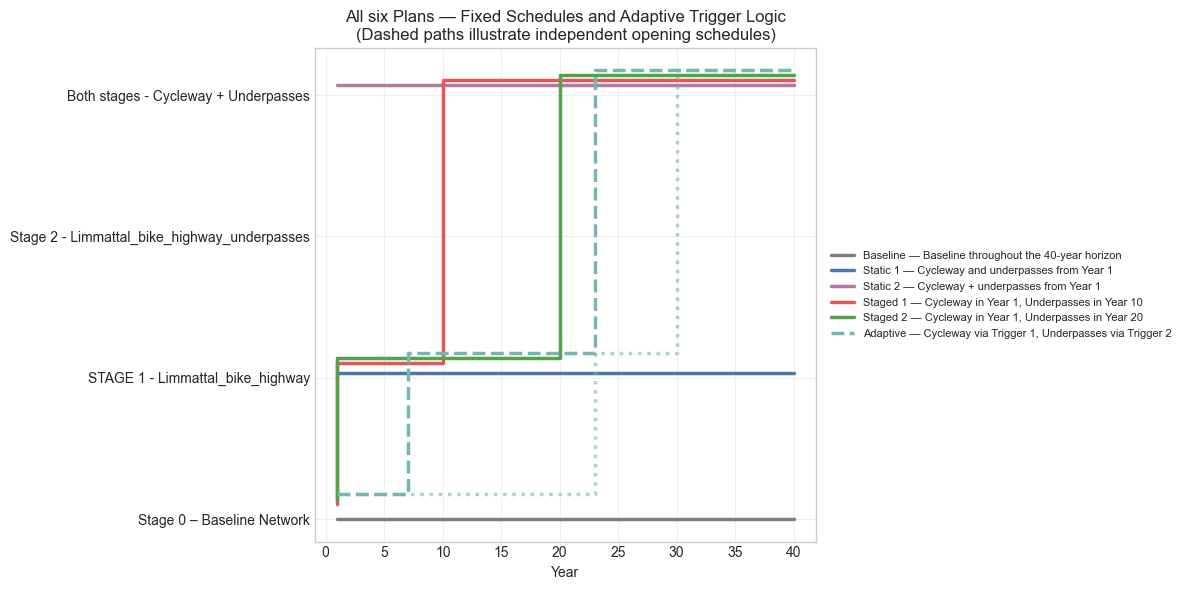

In [5]:
ALL_PLANS = PLAN_NAMES

rng = np.random.default_rng(42)
TRIGGER_YEAR_RANGES = {"to1": (6, 20), "to2": (12, 28)}
TRIGGER_PLACEHOLDERS = {}       # illustrative trigger year, randomised per (plan, transition)
TRIGGER_ALT_PLACEHOLDERS = {}   # a later, delayed alternative -- monitoring indicator takes longer, each package opens independently

for key, spec in PLAN_SPECS.items():
    for transition in ("to1", "to2"):
        rule = spec[transition]
        if rule and rule["type"] == "trigger":
            lo, hi = TRIGGER_YEAR_RANGES[transition]
            primary = int(rng.integers(lo, hi + 1))
            alt = int(rng.integers(primary + 3, min(hi + 8, N_YEARS - 2)))
            TRIGGER_PLACEHOLDERS[(key, transition)] = primary
            TRIGGER_ALT_PLACEHOLDERS[(key, transition)] = alt

# 6 distinct colors for the 6 plans
PLAN_COLORS = {
    "baseline": "#7f7f7f",  # Gray
    "static1":  "#4C78A8",  # Steel Blue
    "static2":  "#B279A2",  # Purple
    "staged1":  "#E45756",  # Red
    "staged2":  "#54A24B",  # Green
    "adaptive": "#72B7B2",  # Teal
}

fig, ax = plt.subplots(figsize=(12, 6))

for i, key in enumerate(ALL_PLANS):
    spec = PLAN_SPECS[key]
    adaptive = any(rule and rule["type"] == "trigger"
                   for rule in [spec["to1"], spec["to2"]])

    for placeholders, linestyle, alpha in (
        (TRIGGER_PLACEHOLDERS, "--" if adaptive else "-", 1.0),
        (TRIGGER_ALT_PLACEHOLDERS, ":", 0.6),
    ):
        if not adaptive and alpha < 1:
            continue
        stations_open, tunnel_open = stages_module.stage_components(spec["initial_stage"])
        events = []
        for transition in ("to1", "to2"):
            rule = spec[transition]
            if rule:
                year = rule["year"] if rule["type"] == "fixed" else placeholders[(key, transition)]
                events.append((year, transition))
        points = [(1, spec["initial_stage"])]
        for year, transition in sorted(events):
            stations_open |= transition == "to1"
            tunnel_open |= transition == "to2"
            points.append((year, stages_module.state_for_components(stations_open, tunnel_open)))
        ax.step([point[0] for point in points] + [N_YEARS],
                [point[1] + i * 0.035 for point in points] + [points[-1][1] + i * 0.035],
                where="post", color=PLAN_COLORS[key], linestyle=linestyle, alpha=alpha,
                linewidth=2.5, label=spec["name"] if alpha == 1 else None)

ax.set_yticks(CASE_STAGE_IDS)
ax.set_yticklabels([CASE_STAGE_LABELS[s] for s in CASE_STAGE_IDS])
ax.set_xlabel("Year")
ax.set_title("All six Plans — Fixed Schedules and Adaptive Trigger Logic\n"
             "(Dashed paths illustrate independent opening schedules)")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
exports.save_outputs(Path(PROJECT_ROOT / 'figures' / '04_all_plan_schedules.png').stem, figure=plt.gcf())
plt.show()


### Independent adaptive pathways (tutorial/supporting task)

```text
                   Stations only
                 /               \ 
Baseline                              Both packages
                 \               /
                    Tunnel only
```

Each arrow adds one package. Both can also open together. A staged plan chooses opening years in advance. The adaptive plan uses two configured monitoring indicator triggers and each package's own lead time. The baseline adds neither package, while static plans start with their selected packages already operating.


## 1.5 Controlled trajectory timing (tutorial/supporting task)

Adaptive planning uses **40-year trajectories**. Two scenarios can have the same endpoints but unfold differently, changing when decisions are triggered.

The MehrSpur example uses `PASSENGER_DEMAND_GROWTH`, `PT_ASC_SHIFT`, `EBIKE_SHARE` and `ROAD_FREIGHT_GROWTH`. A transient uncertainty starts at its general baseline and ends at one sampled final-year value. The default shape is `linear`.

The same Year-40 conditions can be reached early, gradually or later in the horizon. This controlled comparison varies one transport parameter's trajectory while holding its initial value, endpoint and every other input fixed.

Choose `CONTROLLED_PARAMETER` and its `CONTROLLED_ENDPOINT` below. All selected paths share the same endpoints. Compare when observations trigger construction, when packages open and how long each objective is missed.


cell running: 00:00

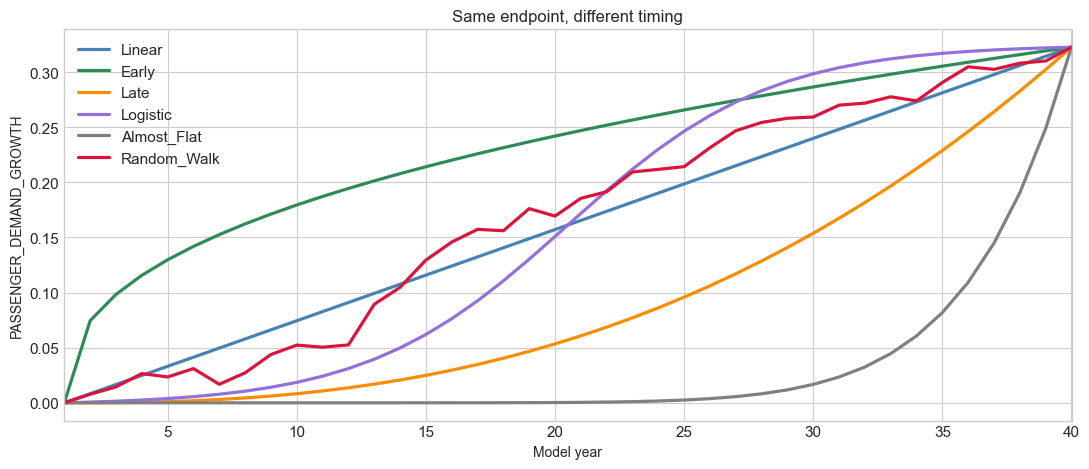

In [38]:
from matplotlib.ticker import PercentFormatter

SHAPE_COLORS = {
    "linear": "steelblue", "early": "seagreen", "late": "darkorange",
    "logistic": "mediumpurple", "random_walk": "crimson", "almost_flat": "gray",
}
years = np.arange(1, N_YEARS + 1)
CONTROLLED_PARAMETER = next((name for name in TRANSPORT_NAMES if name in TRANSIENT_NAMES), None)
CONTROLLED_ENDPOINT = (physical_endpoint(CONTROLLED_PARAMETER, .85)
                       if CONTROLLED_PARAMETER is not None else None)
CONTROLLED_SHAPES = ["linear", "early", "late", "logistic", "almost_flat", "random_walk"]

def add_requirement_guides(ax, key):
    """Show the threshold only during years when the requirement applies."""
    for rule in PERFORMANCE_REQUIREMENTS:
        if rule["indicator"] != key:
            continue
        start, end = rule.get("start_year", 1), rule.get("end_year", N_YEARS)
        limit = rule["threshold"] * indicator_scale(key)
        ax.hlines(limit, start, end, color="black", ls="-.", lw=1.6,
            label=f"Requirement {rule['operator']} {limit:g} ({start}–{end})")

def requirement_summary(frame):
    tests = requirement_results(frame)
    result = {"failure_years": int((~tests.all(axis=1)).sum())}
    for rule, column in zip(PERFORMANCE_REQUIREMENTS, tests.columns):
        bad = frame.loc[~tests[column], "year"]
        key = rule["indicator"]
        result[key + "_failure_years"] = len(bad)
        result[key + "_first_failure_year"] = bad.min() if len(bad) else np.nan
    return result

controlled_paths = {}
if CONTROLLED_PARAMETER is None:
    print("Select a transient transport uncertainty for the timing comparison.")
else:
    if CONTROLLED_PARAMETER not in TRANSIENT_NAMES or CONTROLLED_PARAMETER not in TRANSPORT_NAMES:
        raise ValueError("CONTROLLED_PARAMETER must be a selected transient transport uncertainty.")
    nominal_paths = uc.nominal_paths(nominal=NOTEBOOK_PARAMS)
    start = float(nominal_paths[CONTROLLED_PARAMETER][0])
    endpoint = float(CONTROLLED_ENDPOINT)
    bounds = uc.TRANSPORT_SURROGATE_INPUTS[CONTROLLED_PARAMETER]
    if not bounds["minimum"] <= endpoint <= bounds["maximum"]:
        raise ValueError("Choose CONTROLLED_ENDPOINT inside the surrogate training bounds.")
    reference = {**NOTEBOOK_PARAMS, CONTROLLED_PARAMETER: start,
                 CONTROLLED_PARAMETER + "_Y40": endpoint}
    fig, ax = plt.subplots(figsize=(11, 4.8))
    for shape in CONTROLLED_SHAPES:
        paths = {key: value.copy() for key, value in nominal_paths.items()}
        sampled = uc.get_trajectory(CONTROLLED_PARAMETER, .85, shape, nominal=reference)
        # A fixed draw supplies the same reproducible random-walk bridge.
        fraction = ((sampled - sampled[0]) / (sampled[-1] - sampled[0])
                    if not np.isclose(sampled[-1], sampled[0]) else np.linspace(0, 1, N_YEARS))
        paths[CONTROLLED_PARAMETER] = start + fraction * (endpoint - start)
        controlled_paths[shape] = paths
        ax.plot(years, paths[CONTROLLED_PARAMETER], color=SHAPE_COLORS[shape], lw=2.3, label=shape.title())
    ax.set(xlabel="Model year", ylabel=CONTROLLED_PARAMETER, xlim=(1, N_YEARS),
           title="Same endpoint, different timing")
    ax.legend(fontsize=11)
    ax.tick_params(labelsize=11)
    fig.tight_layout()
    exports.save_outputs("04_trajectory_shapes", figure=fig,
        tables={"paths": pd.DataFrame({"year": years,
                **{shape: paths[CONTROLLED_PARAMETER] for shape, paths in controlled_paths.items()}})})
    plt.show(); plt.close(fig)


## 1.6 Detailed fan charts for two representative drivers (tutorial/supporting task)

The larger fan-chart diagnostic below focuses on passenger demand and PT preference so individual paths and Year-40 densities remain legible. Other selected uncertainties follow their configured distributions and timing patterns in Part 3.

The examples compare `linear`, `early`, `late`, `logistic`, `almost_flat` and `random_walk`. All shapes reach the sampled endpoint. Select the shapes for the ensemble in Section 2.5.


cell running: 00:00

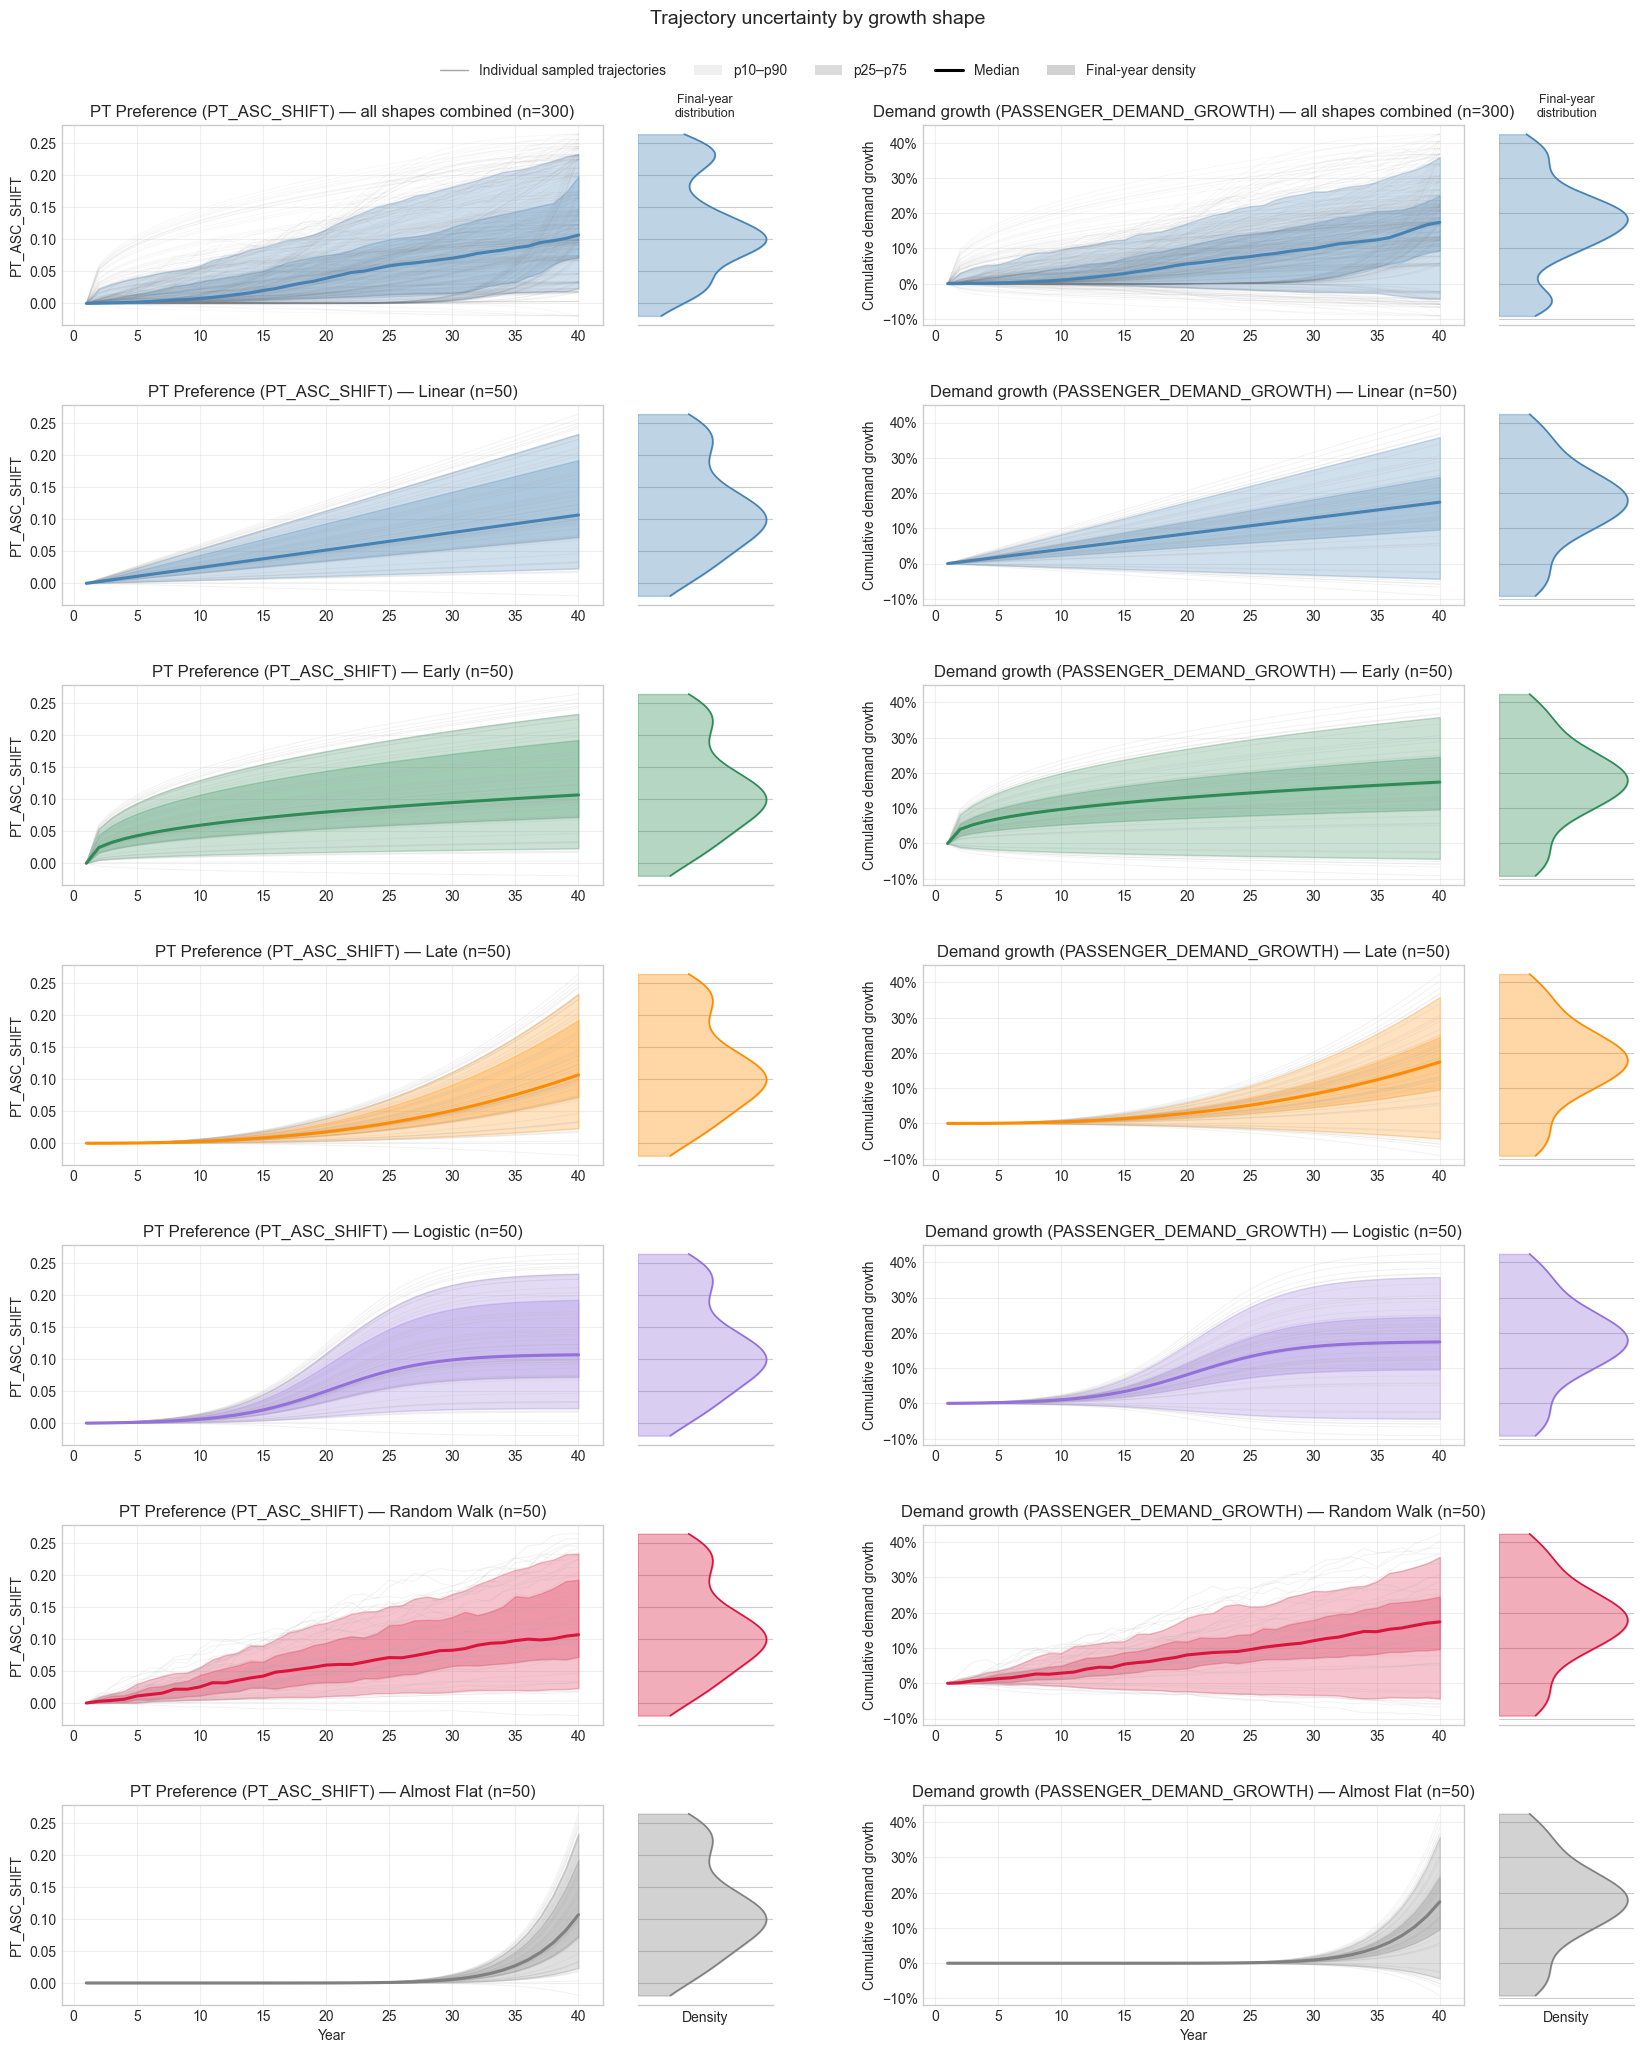

In [39]:
if all(name in p.STRUCTURAL_UNCERTAINTIES for name in ["PASSENGER_DEMAND_GROWTH", "PT_ASC_SHIFT"]):
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D
    from matplotlib.ticker import PercentFormatter
    from scipy.stats import gaussian_kde

    N_PER_SHAPE = 50
    rng = np.random.default_rng(4)

    # Same uncertainty draws for every shape, making the shape comparison fair
    PT_ASC_SHIFT_draws = rng.uniform(0, 1, N_PER_SHAPE)
    PASSENGER_DEMAND_GROWTH_draws = rng.uniform(0, 1, N_PER_SHAPE)

    beta_by_shape = {
        shape: np.array([uc.get_trajectory("PT_ASC_SHIFT", u, shape) for u in PT_ASC_SHIFT_draws])
        for shape in ap.SHAPES
    }
    demand_by_shape = {
        shape: np.array([uc.get_trajectory("PASSENGER_DEMAND_GROWTH", u, shape) for u in PASSENGER_DEMAND_GROWTH_draws])
        for shape in ap.SHAPES
    }

    beta_all = np.vstack(list(beta_by_shape.values()))
    demand_all = np.vstack(list(demand_by_shape.values()))

    def plot_fan(ax, fan, color, line_color="darkgrey", line_width=0.65, line_alpha=0.15):
        p10, p25, p50, p75, p90 = np.percentile(fan, [10, 25, 50, 75, 90], axis=0)

        ax.fill_between(years, p10, p90, color=color, alpha=0.25, zorder=1)
        ax.fill_between(years, p25, p75, color=color, alpha=0.25, zorder=2)

        for trajectory in fan:
            ax.plot(years, trajectory, color=line_color or color,
                    alpha=line_alpha, linewidth=line_width, zorder=3)

        ax.plot(years, p50, color=color, linewidth=2.2, zorder=4)
        ax.grid(alpha=0.3)

    def plot_density(ax, values, color):
        """Vertical KDE of `values` (e.g. a fan's final-year outcomes), sharing the
        y-axis with the companion fan panel so the two line up directly."""
        lo, hi = values.min(), values.max()
        if np.isclose(lo, hi):
            ax.axhline(lo, color=color)
            return
        y_grid = np.linspace(lo, hi, 200)
        density = gaussian_kde(values)(y_grid)

        ax.fill_betweenx(y_grid, 0, density, color=color, alpha=0.35, zorder=2)
        ax.plot(density, y_grid, color=color, linewidth=1.2, zorder=3)

        ax.set_xlim(left=0)
        ax.set_xticks([])
        ax.tick_params(axis="y", left=False, labelleft=False)
        for spine in ("top", "right", "left"):
            ax.spines[spine].set_visible(False)

    n_rows = len(ap.SHAPES) + 1
    fig = plt.figure(figsize=(17, 3 * n_rows))
    gs = fig.add_gridspec(n_rows, 5, width_ratios=[4, 1, 0.6, 4, 1],
                          wspace=0.12, hspace=0.4)

    axes = np.empty((n_rows, 2), dtype=object)       # fan panels: col 0 = beta, col 1 = demand
    dens_axes = np.empty((n_rows, 2), dtype=object)  # their final-year density panels

    for row in range(n_rows):
        ref_beta = axes[0, 0] if row else None
        ref_demand = axes[0, 1] if row else None

        axes[row, 0] = fig.add_subplot(gs[row, 0], sharex=ref_beta, sharey=ref_beta)
        dens_axes[row, 0] = fig.add_subplot(gs[row, 1], sharey=axes[row, 0])

        axes[row, 1] = fig.add_subplot(gs[row, 3], sharex=ref_demand, sharey=ref_demand)
        dens_axes[row, 1] = fig.add_subplot(gs[row, 4], sharey=axes[row, 1])

    # Top row: all shapes combined
    plot_fan(axes[0, 0], beta_all, "steelblue", line_color="grey", line_alpha=0.06)
    plot_density(dens_axes[0, 0], beta_all[:, -1], "steelblue")
    plot_fan(axes[0, 1], demand_all, "steelblue", line_color="grey", line_alpha=0.06)
    plot_density(dens_axes[0, 1], demand_all[:, -1], "steelblue")

    axes[0, 0].set_title(f"PT Preference (PT_ASC_SHIFT) — all shapes combined (n={len(beta_all)})")
    axes[0, 1].set_title(f"Demand growth (PASSENGER_DEMAND_GROWTH) — all shapes combined (n={len(demand_all)})")

    # One row per trajectory shape
    for row, shape in enumerate(ap.SHAPES, start=1):
        color = SHAPE_COLORS[shape]
        label = shape.replace("_", " ").title()

        plot_fan(axes[row, 0], beta_by_shape[shape], color)
        plot_density(dens_axes[row, 0], beta_by_shape[shape][:, -1], color)

        plot_fan(axes[row, 1], demand_by_shape[shape], color)
        plot_density(dens_axes[row, 1], demand_by_shape[shape][:, -1], color)

        axes[row, 0].set_title(f"PT Preference (PT_ASC_SHIFT) — {label} (n={N_PER_SHAPE})")
        axes[row, 1].set_title(f"Demand growth (PASSENGER_DEMAND_GROWTH) — {label} (n={N_PER_SHAPE})")

    for row in range(n_rows):
        axes[row, 0].set_ylabel("PT_ASC_SHIFT")
        axes[row, 1].set_ylabel("Cumulative demand growth")
        axes[row, 1].yaxis.set_major_formatter(PercentFormatter(1))

    axes[-1, 0].set_xlabel("Year")
    axes[-1, 1].set_xlabel("Year")
    dens_axes[-1, 0].set_xlabel("Density")
    dens_axes[-1, 1].set_xlabel("Density")

    dens_axes[0, 0].set_title("Final-year\ndistribution", fontsize=9)
    dens_axes[0, 1].set_title("Final-year\ndistribution", fontsize=9)

    legend_handles = [
        Line2D([0], [0], color="grey", linewidth=1, alpha=0.7,
               label="Individual sampled trajectories"),
        Patch(facecolor="grey", alpha=0.12, label="p10–p90"),
        Patch(facecolor="grey", alpha=0.28, label="p25–p75"),
        Line2D([0], [0], color="black", linewidth=2.2, label="Median"),
        Patch(facecolor="grey", alpha=0.35, label="Final-year density"),
    ]

    fig.suptitle("Trajectory uncertainty by growth shape", y=0.995, fontsize=14)
    fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 0.975),
               ncol=5, frameon=False)

    fig.subplots_adjust(top=0.94, bottom=0.045, left=0.055, right=0.98)
    exports.save_outputs(Path(PROJECT_ROOT / 'figures' / '04_trajectory_fans_by_shape.png').stem, figure=plt.gcf())
    plt.show(); plt.close(fig)
else:
    print('This two-driver example requires PASSENGER_DEMAND_GROWTH and PT_ASC_SHIFT in the uncertainty registry.')


## 1.7 Consequences of trajectory timing (tutorial/supporting task)

Only the selected trajectory differs between these runs. The table reports each requirement's first failure and failure duration, package openings and present-value expenditure. Blank dates mean that the event does not occur within the horizon. A later opening can save expenditure but leave an objective unprotected for longer.


cell running: 00:00

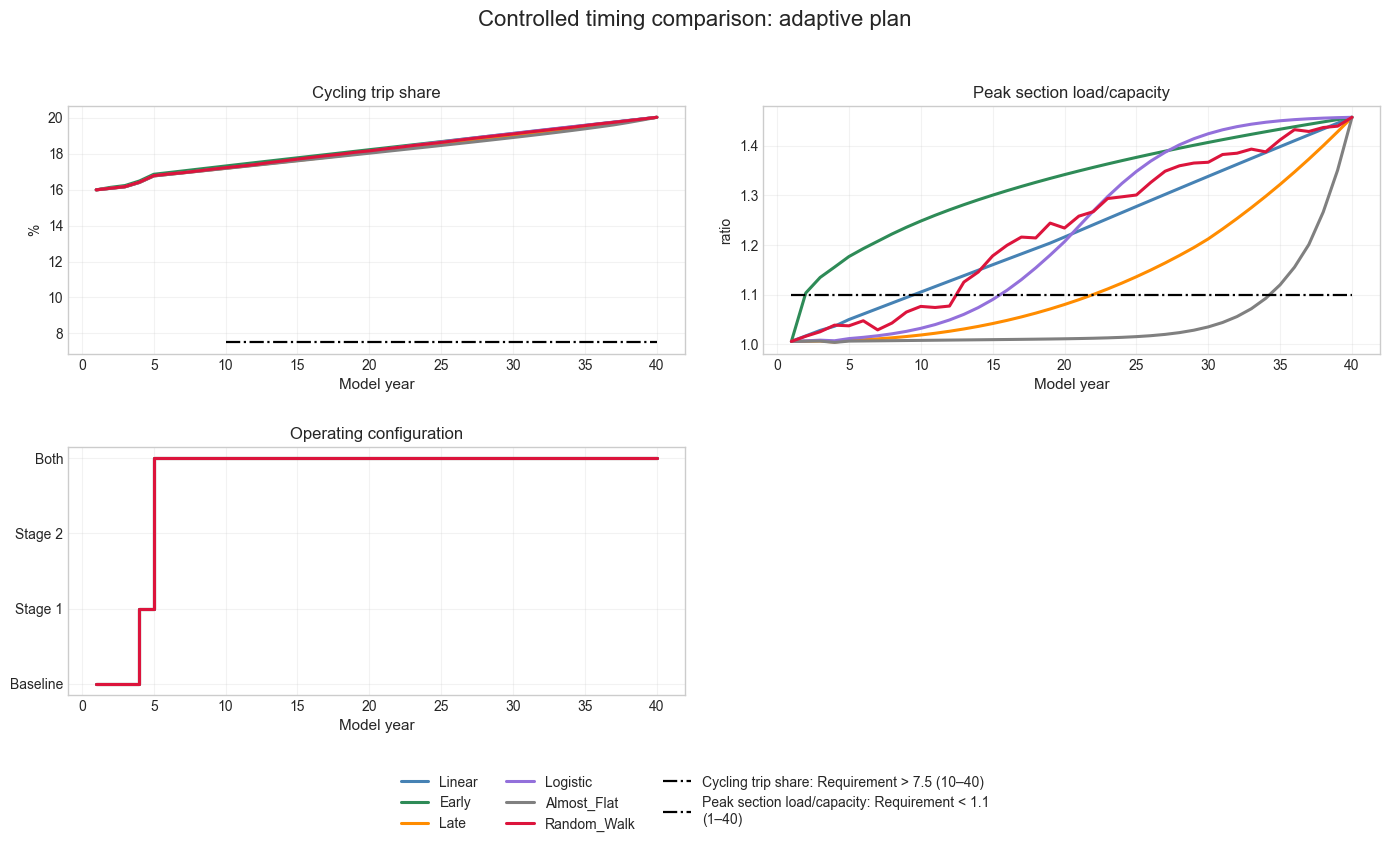

,parameter,endpoint,failure_years,bike_share_trips_failure_years,bike_share_trips_first_failure_year,section_load_ratio_failure_years,section_load_ratio_first_failure_year,package_1_decision_year,package_1_opening_year,package_2_decision_year,package_2_opening_year,discounted_expenditure_MCHF
shape,,,,,,,,,,,,
linear,PASSENGER_DEMAND_GROWTH,0.322518,31,0,NaN,31,10,2,4,2,5,144.248997
early,PASSENGER_DEMAND_GROWTH,0.322518,39,0,NaN,39,2,2,4,2,5,144.248997
late,PASSENGER_DEMAND_GROWTH,0.322518,19,0,NaN,19,22,2,4,2,5,144.248997
logistic,PASSENGER_DEMAND_GROWTH,0.322518,25,0,NaN,25,16,2,4,2,5,144.248997
almost_flat,PASSENGER_DEMAND_GROWTH,0.322518,6,0,NaN,6,35,2,4,2,5,144.248997
random_walk,PASSENGER_DEMAND_GROWTH,0.322518,28,0,NaN,28,13,2,4,2,5,144.248997


In [40]:
import textwrap

controlled_runs = {}
if controlled_paths:
    controlled_runs = {shape: run_plan_from_trajectories_gp("adaptive", STAGE_METRICS,
        extra_trajectories=paths, params=NOTEBOOK_PARAMS) for shape, paths in controlled_paths.items()}
    keys = list(dict.fromkeys(rule["indicator"] for rule in PERFORMANCE_REQUIREMENTS))
    count = len(keys) + 1
    fig, axes = plt.subplots((count + 1) // 2, 2, figsize=(14, 4.3 * ((count + 1) // 2)), squeeze=False)
    rows = []
    for shape, (frame, meta) in controlled_runs.items():
        for ax, key in zip(axes.flat, keys):
            ax.plot(frame["year"], frame[key] * indicator_scale(key), color=SHAPE_COLORS[shape],
                lw=2.2, label=shape.title())
        axes.flat[len(keys)].step(frame["year"], frame["stage"], where="post",
            color=SHAPE_COLORS[shape], lw=2.2, label=shape.title())
        rows.append({"shape": shape, "parameter": CONTROLLED_PARAMETER, "endpoint": CONTROLLED_ENDPOINT,
            **requirement_summary(frame),
            **{f"package_{i}_{event}_year": meta.get(f"{event}{i}_year")
               for i in (1, 2) for event in ("decision", "opening")},
            "discounted_expenditure_MCHF": frame["comparison_cost"].sum() / 1e6})
    for ax, key in zip(axes.flat, keys):
        add_requirement_guides(ax, key)
        ax.set(title=indicator_label(key), ylabel=indicator_unit(key))
    axes.flat[len(keys)].set(title="Operating configuration")
    axes.flat[len(keys)].set_yticks(CASE_STAGE_IDS,
        ["Baseline", "Stage 1", "Stage 2", "Both"] if len(CASE_STAGE_IDS) == 4 else CASE_STAGE_IDS)
    for ax in list(axes.flat)[:count]:
        ax.set_xlabel("Model year", fontsize=11)
        ax.tick_params(labelsize=10)
        ax.grid(alpha=.25)
    for ax in list(axes.flat)[count:]: ax.set_axis_off()
    fig.suptitle("Controlled timing comparison: adaptive plan", fontsize=16)
    legend_items = {}
    for index, ax in enumerate(list(axes.flat)[:count]):
        handles, labels = ax.get_legend_handles_labels()
        for handle, label in zip(handles, labels):
            if label.startswith("Requirement") and index < len(keys):
                label = textwrap.fill(f"{indicator_label(keys[index])}: {label}", 48)
            legend_items.setdefault(label, handle)
    legend = fig.legend(legend_items.values(), legend_items.keys(), loc="lower center",
        bbox_to_anchor=(.5, .01), ncol=3, fontsize=10, frameon=False)
    fig.canvas.draw()
    legend_top = legend.get_window_extent().transformed(fig.transFigure.inverted()).y1
    fig.tight_layout(rect=(0, legend_top + .025, 1, .95), w_pad=2.5, h_pad=2.5)
    exports.save_outputs("04_controlled_timing", figure=fig,
        tables={"trajectories": pd.concat([frame.select_dtypes(exclude="object").assign(shape=shape)
                                         for shape, (frame, _) in controlled_runs.items()], ignore_index=True)})
    plt.show(); plt.close(fig)
    show_table("04_controlled_timing_summary", pd.DataFrame(rows).set_index("shape"))


# Part 2 — Test the adaptive rules
<a id="adaptive-rules"></a>

Temporary trigger changes below apply to Part 2 only. Permanent rules belong in `adaptive_planning.py`; use `TRIGGER_OVERRIDES` in Section 1.2 for notebook-wide experiments.


In [9]:
# Temporary rules for the Part 2 examples and timing comparison.
EXAMPLE_TRIGGER_OVERRIDES = {
    # "TRIGGER1_MONITORING_INDICATOR": "bike_trips",
    # "TRIGGER1_THRESHOLD": 10_000,
    # "TRIGGER2_MONITORING_INDICATOR": "pt_trips",
    # "TRIGGER2_THRESHOLD": 30_000,
}
EXAMPLE_INDICATORS = ["pt_share", "congestion_delay_hours", "operating_co2_tonnes"]


cell running: 00:00

## 2.0 Select monitoring indicators (mandatory task)

A monitoring indicator should help anticipate a performance problem and the circumstances in which an intervention helps. Compare candidate indicators before choosing a threshold. The screening below observes each indicator under the baseline at `MONITORING_YEAR`, then compares it with performance at `MONITORING_ASSESSMENT_YEAR` under the baseline, Stage 1 and Stage 2 separately. All comparisons use the same sampled scenarios. Change the candidate list and outcome list for a cycling or mobility-hub project; section indicators are omitted when no counting section is configured.

The colour panels report the **R² of a simple linear regression**. The final scatterplots use `MONITORING_SCATTER_INDICATOR` for every outcome: PT share and comfort in this example. They show baseline and package performance in physical units, with fitted lines and the applicable requirements. The table also reports the slope and Spearman rank correlation: a negative slope can be useful when a larger monitoring value predicts a reduction in an undesirable outcome. Compare the size of the changes as well as R²; a well-predicted but tiny change need not justify investment.

For MehrSpur, section flow is directly related to load/capacity, so a high R² is expected. This does not make it equally informative about the PT-share objective. Change `MONITORING_CANDIDATES` to test other indicators in the regressions; `MONITORING_SCATTER_INDICATOR` independently selects the one to inspect in the final plots. Without a counting section, its default is the first package’s configured monitoring indicator.

This is a screening exercise, not a causal test or an automatic trigger calibration. It uses linear paths and hypothetical operating snapshots; construction timing and persistence are tested in the following exercises. A high association with the baseline outcome does not guarantee a strong association with the improvement from either package. Choose monitoring indicators that can be observed in practice, allow time for construction, and test their thresholds with the examples below. Permanent trigger changes belong in `adaptive_planning.py`.


cell running: 00:00

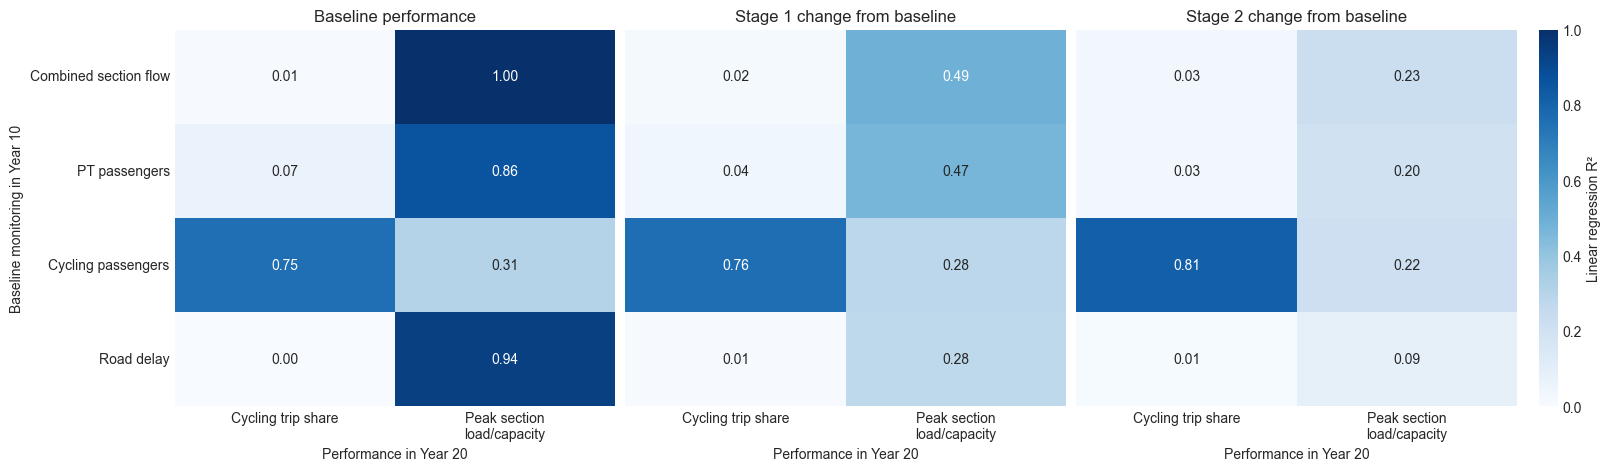

,comparison,monitoring_indicator,outcome,monitoring_unit,outcome_unit,n,r_squared,slope,spearman_r,outcome_range
0,baseline,section_combined_daily,bike_share_trips,person-trips/day,%,40,0.0068,3.017e-05,0.0739,7.3609
1,baseline,section_combined_daily,section_load_ratio,person-trips/day,ratio,40,0.9995,1.772e-05,0.9981,0.3450
2,baseline,pt_trips,bike_share_trips,person-trips/peak hour,%,40,0.0652,-1.705e-04,-0.2272,7.3609
3,baseline,pt_trips,section_load_ratio,person-trips/peak hour,ratio,40,0.8640,3.000e-05,0.9454,0.3450
4,baseline,bike_trips,bike_share_trips,person-trips/peak hour,%,40,0.7543,4.531e-04,0.8647,7.3609
5,baseline,bike_trips,section_load_ratio,person-trips/peak hour,ratio,40,0.3063,1.395e-05,0.4797,0.3450
6,baseline,congestion_delay_hours,bike_share_trips,person-hours/year,%,40,0.0001,5.227e-08,-0.0116,7.3609
7,baseline,congestion_delay_hours,section_load_ratio,person-hours/year,ratio,40,0.9388,2.009e-07,0.9660,0.3450
8,stage1_change,section_combined_daily,bike_share_trips,person-trips/day,percentage points,40,0.0184,2.290e-07,0.1473,0.0321
9,stage1_change,section_combined_daily,section_load_ratio,person-trips/day,ratio,40,0.4900,1.036e-07,0.7420,0.0030


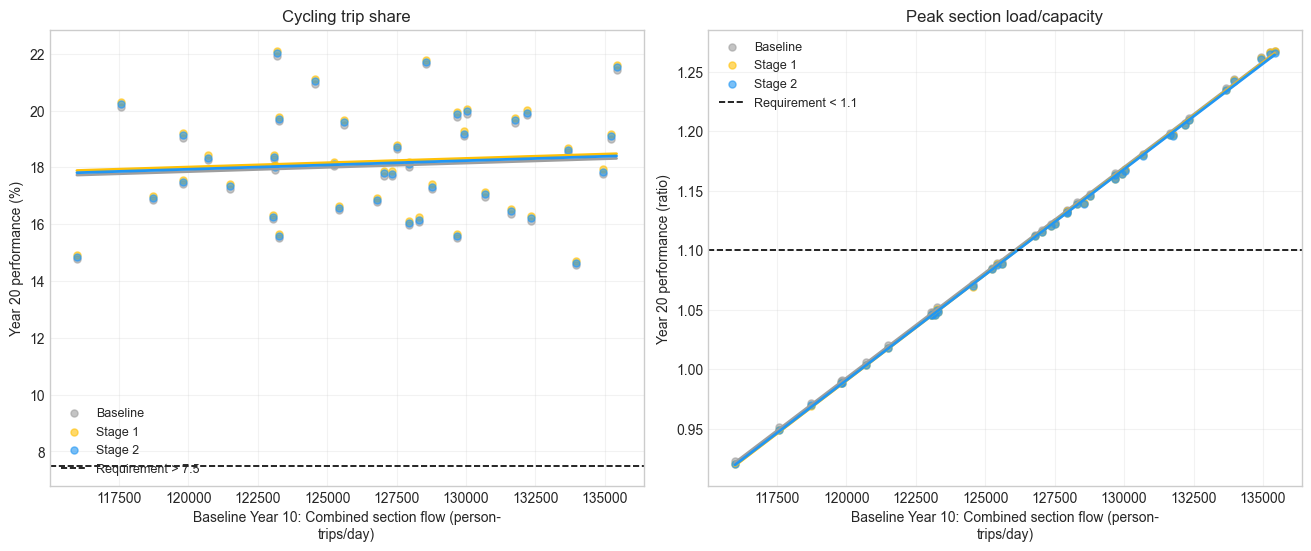

In [10]:
# Screen candidate indicators before testing trigger thresholds.
MONITORING_CANDIDATES = ["section_combined_daily", "pt_trips", "bike_trips", "congestion_delay_hours"]
MONITORING_OUTCOMES = [rule["indicator"] for rule in PERFORMANCE_REQUIREMENTS]
MONITORING_YEAR = 10
MONITORING_ASSESSMENT_YEAR = 20
N_MONITORING_SCENARIOS = 40
MONITORING_SEED = 73
# One indicator for the final scatterplots, separate from the candidate list.
MONITORING_SCATTER_INDICATOR = (
    "section_combined_daily" if indicator_available("section_combined_daily")
    else TRIGGER_1["monitoring_indicator"]
)

from scipy.stats import qmc
from textwrap import fill

indicator_selection([MONITORING_SCATTER_INDICATOR], required=True)
monitoring_candidates = indicator_selection(
    list(dict.fromkeys([*MONITORING_CANDIDATES, MONITORING_SCATTER_INDICATOR])))
monitoring_outcomes = indicator_selection(MONITORING_OUTCOMES)
if not monitoring_candidates or not monitoring_outcomes:
    raise ValueError("Choose at least one available monitoring candidate and performance outcome above.")
if any(not INDICATOR_CATALOG[key].get("monitoring_indicator", False) for key in monitoring_candidates):
    raise ValueError("Choose candidates marked monitoring_indicator=True in INDICATOR_CATALOG.")
if not 1 <= MONITORING_YEAR <= MONITORING_ASSESSMENT_YEAR <= N_YEARS:
    raise ValueError("Monitoring and assessment years must be ordered within the model horizon.")
if N_MONITORING_SCENARIOS < 3:
    raise ValueError("Use at least three scenarios for this screening.")


def monitoring_snapshot(paths, year, stage):
    """One physical response-table evaluation; no pathway or native assignment."""
    t = int(year) - 1
    params = uc.year_parameters(paths, t, NOTEBOOK_PARAMS)
    state = transport_emulator.predict_transport_state(
        stage=stage, include_links=False, include_welfare=False,
        **uc.transport_surrogate_inputs_from_paths(paths, t))
    row = m.simulate_year(state["metrics"], stage, t, params["PASSENGER_DEMAND_GROWTH"],
        params=params, transport_state=state, return_details=True, include_welfare=False,
        inv_cost=0.0, op_cost=0.0, flex_cost=0.0)
    row["year"] = year
    for mode in ("car", "pt"):
        row[f"annual_{mode}_trips"] = row[f"{mode}_trips"] * m.annualizers(params)[mode]
    return add_indicators(pd.DataFrame([row])).iloc[0]


_monitoring_draws = (qmc.LatinHypercube(d=len(SAMPLED_NAMES), seed=MONITORING_SEED)
    .random(N_MONITORING_SCENARIOS) if SAMPLED_NAMES else np.empty((N_MONITORING_SCENARIOS, 0)))
monitoring_rows = []
for scenario, draw in enumerate(_monitoring_draws, 1):
    paths = uc.build_paths(dict(zip(SAMPLED_NAMES, draw)), nominal=NOTEBOOK_PARAMS)
    observed = monitoring_snapshot(paths, MONITORING_YEAR, 0)
    baseline = (observed if MONITORING_YEAR == MONITORING_ASSESSMENT_YEAR else
        monitoring_snapshot(paths, MONITORING_ASSESSMENT_YEAR, 0))
    row = {"scenario": scenario, **{
        f"monitor_{key}": observed[key] * indicator_scale(key) for key in monitoring_candidates}}
    row.update({f"baseline_{key}": baseline[key] * indicator_scale(key) for key in monitoring_outcomes})
    for package, stage in ((1, STATIONS_STATE), (2, TUNNEL_STATE)):
        project = monitoring_snapshot(paths, MONITORING_ASSESSMENT_YEAR, stage)
        row.update({f"stage{package}_change_{key}": (project[key] - baseline[key]) * indicator_scale(key)
                    for key in monitoring_outcomes})
    monitoring_rows.append(row)
monitoring_samples = pd.DataFrame(monitoring_rows)


def monitoring_regression(x, y):
    finite = np.isfinite(x) & np.isfinite(y)
    x, y = np.asarray(x)[finite], np.asarray(y)[finite]
    result = {"n": len(x), "r_squared": np.nan, "slope": np.nan,
              "intercept": np.nan, "spearman_r": np.nan,
              "outcome_range": float(np.ptp(y)) if len(y) else np.nan}
    if len(x) < 3 or any(np.ptp(values) <= 1e-8 * max(1.0, np.max(np.abs(values))) for values in (x, y)):
        return result
    slope = float(np.dot(x - x.mean(), y - y.mean()) / np.dot(x - x.mean(), x - x.mean()))
    prediction = y.mean() + slope * (x - x.mean())
    return {**result, "slope": slope, "intercept": float(y.mean() - slope * x.mean()),
        "r_squared": float(np.clip(1 - np.sum((y - prediction)**2) / np.sum((y - y.mean())**2), 0, 1)),
        "spearman_r": float(pd.Series(x).corr(pd.Series(y), method="spearman"))}


def monitoring_outcome_unit(comparison, outcome):
    return ("percentage points" if comparison != "baseline" and
            INDICATOR_CATALOG[outcome].get("format") == "percent" else indicator_unit(outcome))


monitoring_regressions = pd.DataFrame([
    {"comparison": comparison, "monitoring_indicator": candidate, "outcome": outcome,
     "monitoring_unit": indicator_unit(candidate), "outcome_unit": monitoring_outcome_unit(comparison, outcome),
     **monitoring_regression(monitoring_samples[f"monitor_{candidate}"].to_numpy(),
                            monitoring_samples[f"{comparison}_{outcome}"].to_numpy())}
    for comparison in ("baseline", "stage1_change", "stage2_change")
    for candidate in monitoring_candidates for outcome in monitoring_outcomes])
fig, axes = plt.subplots(1, 3, figsize=(16, max(4.6, 1.0 * len(monitoring_candidates))),
                         sharey=True, layout="constrained")
for ax, comparison, title in zip(axes, ("baseline", "stage1_change", "stage2_change"),
        ("Baseline performance", "Stage 1 change from baseline", "Stage 2 change from baseline")):
    table = monitoring_regressions.loc[monitoring_regressions["comparison"].eq(comparison)].pivot(
        index="monitoring_indicator", columns="outcome", values="r_squared").reindex(
        index=monitoring_candidates, columns=monitoring_outcomes)
    sns.heatmap(table, ax=ax, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
        cbar=ax is axes[-1], cbar_kws={"label": "Linear regression R²"})
    for row, col in zip(*np.where(table.isna())):
        ax.text(col + .5, row + .5, "constant /\nunavailable", ha="center", va="center", fontsize=9)
    ax.set(title=title, xlabel=f"Performance in Year {MONITORING_ASSESSMENT_YEAR}",
           ylabel=f"Baseline monitoring in Year {MONITORING_YEAR}" if ax is axes[0] else "")
    ax.set_xticklabels([fill(indicator_label(key), 22) for key in monitoring_outcomes], rotation=0, fontsize=10)
    ax.set_yticklabels([fill(indicator_label(key), 23) for key in monitoring_candidates], rotation=0, fontsize=10)
exports.save_outputs("02_0_monitoring_screen", figure=fig, tables={
    "regressions": monitoring_regressions, "samples": monitoring_samples})
plt.show(); plt.close(fig)
# Retain small slopes visibly; the full numeric fits are exported above.
monitoring_report = monitoring_regressions.drop(columns="intercept").round(4)
monitoring_report["slope"] = monitoring_regressions["slope"].map(
    lambda value: f"{value:.3e}" if np.isfinite(value) else "unavailable")
show_table("02_0_monitoring_relationships", monitoring_report)

candidate = MONITORING_SCATTER_INDICATOR
fig, axes = plt.subplots(1, len(monitoring_outcomes),
    figsize=(6.5 * len(monitoring_outcomes), 5.4), squeeze=False, layout="constrained")
selected_monitor_rows = []
for ax, outcome in zip(axes.flat, monitoring_outcomes):
    x = monitoring_samples[f"monitor_{candidate}"].to_numpy()
    baseline_values = monitoring_samples[f"baseline_{outcome}"].to_numpy()
    for package, state, label in ((0, 0, "Baseline"), (1, STATIONS_STATE, "Stage 1"),
                                  (2, TUNNEL_STATE, "Stage 2")):
        y = baseline_values.copy()
        if package:
            y += monitoring_samples[f"stage{package}_change_{outcome}"].to_numpy()
        color = CASE_STAGE_COLORS[state]
        ax.scatter(x, y, alpha=.6, s=26, color=color, label=label)
        fit = monitoring_regression(x, y)
        if np.isfinite(fit["slope"]):
            fitted_x = np.linspace(np.nanmin(x), np.nanmax(x), 100)
            ax.plot(fitted_x, fit["intercept"] + fit["slope"] * fitted_x, color=color, lw=2)
        selected_monitor_rows.extend({"scenario": scenario, "monitoring_indicator": candidate,
            "monitoring_value": monitor, "configuration": label, "outcome": outcome,
            "outcome_value": value} for scenario, monitor, value in
            zip(monitoring_samples["scenario"], x, y))
    for rule in PERFORMANCE_REQUIREMENTS:
        if (rule["indicator"] == outcome and
                rule.get("start_year", 1) <= MONITORING_ASSESSMENT_YEAR <= rule.get("end_year", N_YEARS)):
            value = rule["threshold"] * indicator_scale(outcome)
            ax.axhline(value, color="black", ls="--", lw=1.2,
                label=f"Requirement {rule['operator']} {value:g}")
    ax.set(title=indicator_label(outcome),
        xlabel=fill(f"Baseline Year {MONITORING_YEAR}: {indicator_label(candidate)} ({indicator_unit(candidate)})", 48),
        ylabel=fill(f"Year {MONITORING_ASSESSMENT_YEAR} performance ({indicator_unit(outcome)})", 45))
    ax.legend(fontsize=9)
    ax.grid(alpha=.25)
exports.save_outputs("02_0_monitoring_selected_indicator", figure=fig,
    tables={"samples": pd.DataFrame(selected_monitor_rows)})
plt.show(); plt.close(fig)


## 2.1 Hand-picked trigger examples (mandatory task)

Inspect five reproducible scenarios before running the ensemble. Each row shows demand growth, the observed monitoring indicator(s), the operating configuration and one selected performance indicator. A trigger uses completed observations; construction then delays the opening. The two packages can be decided and built independently.

`EXAMPLE_TRIGGER_OVERRIDES` at the beginning of Part 2 changes the rules only for these examples. Thresholds use model units: shares are fractions, and trip counts refer to the units shown in the rule table. The current rules trigger when their monitoring indicator **exceeds** the threshold for the required number of consecutive observations. Use `EXAMPLE_INDICATORS` to choose the outcomes. Permanent trigger changes belong in `adaptive_planning.py`.

The objective-protection comparison also shows each configured requirement. Requirement lines apply only during their specified years.


cell running: 00:00

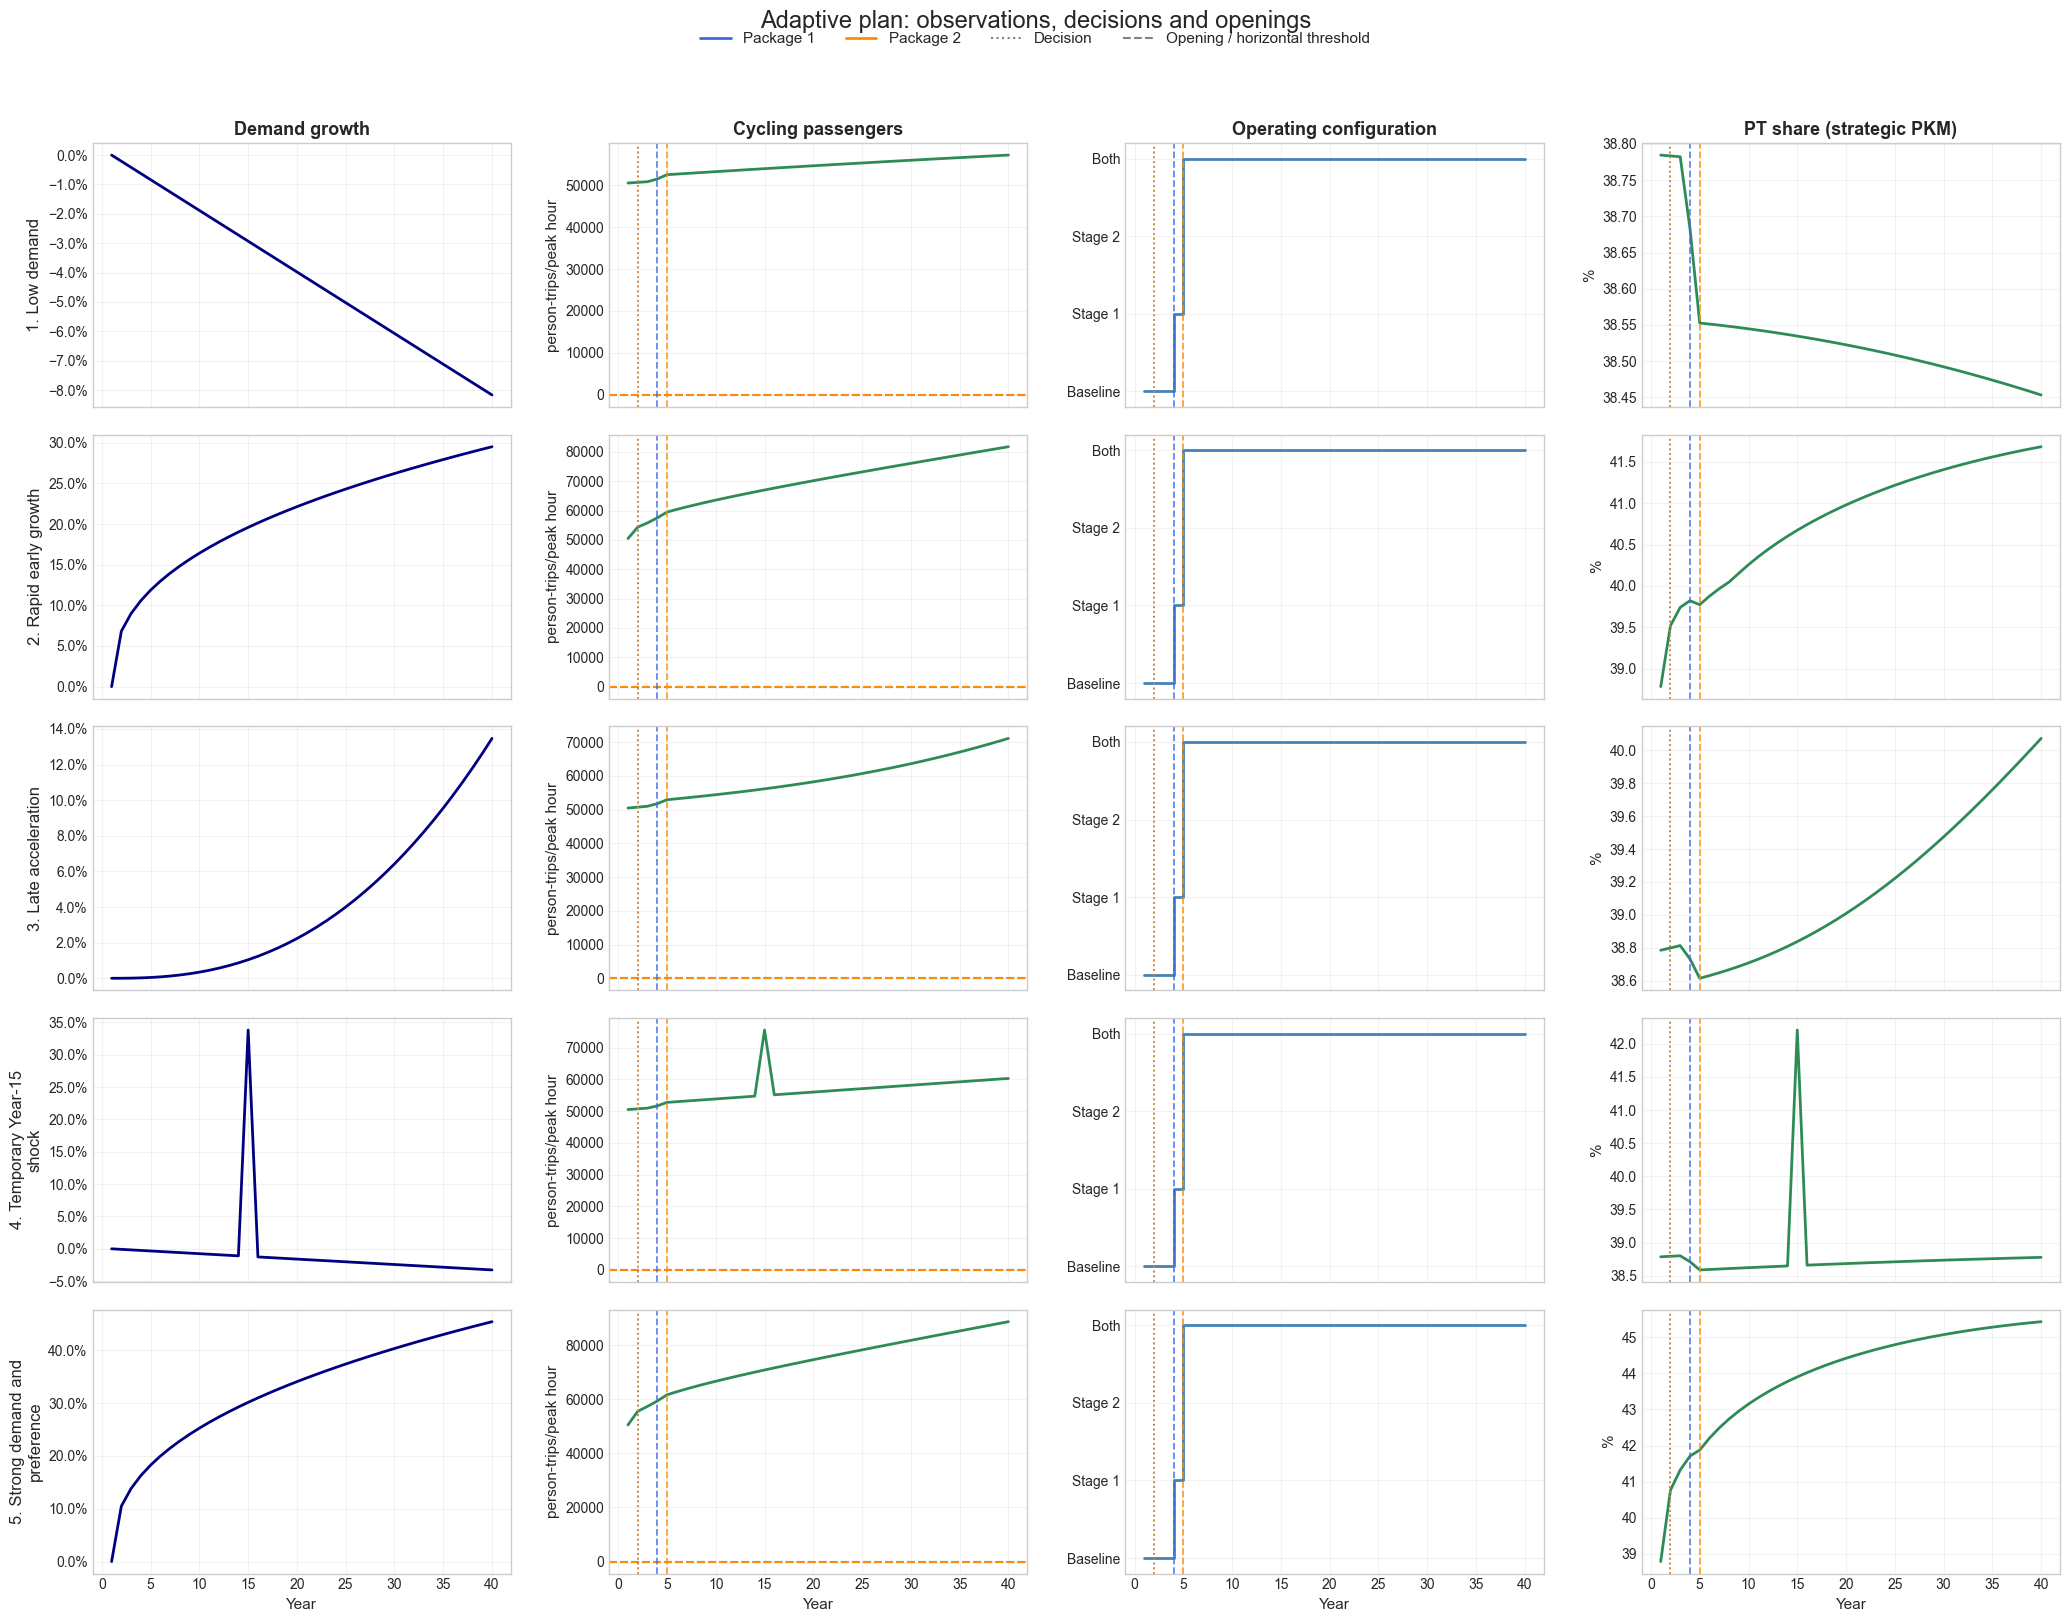

,monitoring_indicator,threshold_exceeded,threshold_unit,consecutive_observations,construction_years
package,,,,,
1,bike_trips,0.1,person-trips/peak hour,1,2
2,bike_trips,0.1,person-trips/peak hour,1,3


,failure_years,bike_share_trips_failure_years,bike_share_trips_first_failure_year,section_load_ratio_failure_years,section_load_ratio_first_failure_year,demand_growth_y40,pt_asc_shift_y40,package_1_decision_year,package_1_opening_year,package_2_decision_year,package_2_opening_year
scenario,,,,,,,,,,,
1. Low demand,0,0,NaN,0,NaN,-0.081678,0.100000,2,4,2,5
2. Rapid early growth,38,0,NaN,38,3.0,0.295061,0.100000,2,4,2,5
3. Late acceleration,10,0,NaN,10,31.0,0.134664,0.100000,2,4,2,5
4. Temporary Year-15 shock,1,0,NaN,1,15.0,-0.032668,0.100000,2,4,2,5
5. Strong demand and preference,39,0,NaN,39,2.0,0.454174,0.271716,2,4,2,5


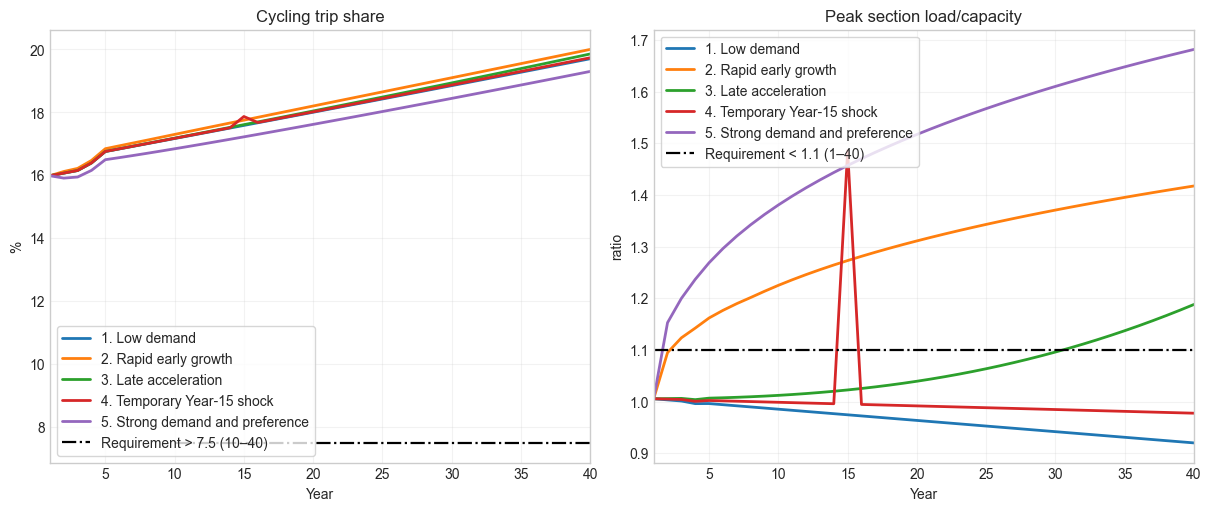

In [11]:
get_ipython().run_line_magic("matplotlib", "inline")
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import textwrap

def plan_display_name(key):
    return PLAN_SPECS[key]["name"].split(" — ", 1)[0]

TRIGGER_EXAMPLES = {
    "1. Low demand": dict(PT_ASC_SHIFT=0.5, PASSENGER_DEMAND_GROWTH=0.05,
        PT_ASC_SHIFT__shape="linear", PASSENGER_DEMAND_GROWTH__shape="linear"),
    "2. Rapid early growth": dict(PT_ASC_SHIFT=0.5, PASSENGER_DEMAND_GROWTH=0.8,
        PT_ASC_SHIFT__shape="linear", PASSENGER_DEMAND_GROWTH__shape="early"),
    "3. Late acceleration": dict(PT_ASC_SHIFT=0.5, PASSENGER_DEMAND_GROWTH=0.4,
        PT_ASC_SHIFT__shape="linear", PASSENGER_DEMAND_GROWTH__shape="late"),
    "4. Temporary Year-15 shock": dict(PT_ASC_SHIFT=0.5, PASSENGER_DEMAND_GROWTH=0.1,
        PT_ASC_SHIFT__shape="linear", PASSENGER_DEMAND_GROWTH__shape="linear", shock_year=15),
    "5. Strong demand and preference": dict(PT_ASC_SHIFT=0.99, PASSENGER_DEMAND_GROWTH=0.99,
        PT_ASC_SHIFT__shape="early", PASSENGER_DEMAND_GROWTH__shape="early"),
}
if not any(name in SAMPLED_NAMES for name in ("PASSENGER_DEMAND_GROWTH", "PT_ASC_SHIFT")):
    driver = next((name for name in TRANSIENT_NAMES if name in TRANSPORT_NAMES), None)
    TRIGGER_EXAMPLES = ({f"{i}. {label}": {driver: draw, driver + "__shape": shape}
        for i, (label, draw, shape) in enumerate([
            ("Low endpoint", .05, "linear"), ("Early change", .85, "early"),
            ("High endpoint", .95, "logistic")], 1)} if driver else {"Nominal scenario": {}})
_example_run_cache = {}
_example_path_cache = {}
PACKAGE_COLORS = {1: "royalblue", 2: "darkorange"}
STATE_SHORT_LABELS = {0: "Baseline", 1: "Stage 1", 2: "Stage 2", 3: "Both"}

def example_parameters(overrides=None):
    params = normalize_notebook_params({**NOTEBOOK_PARAMS, **EXAMPLE_TRIGGER_OVERRIDES, **(overrides or {})})
    for rule in notebook_triggers(params).values():
        key = rule["monitoring_indicator"]
        if key not in INDICATOR_CATALOG or not INDICATOR_CATALOG[key].get("monitoring_indicator", False):
            raise ValueError(f"{key!r} is not a supported monitoring indicator in the catalogue.")
        if not indicator_available(key):
            raise ValueError(f"{key!r} is unavailable for this project. Choose an available monitoring indicator.")
    return params

def example_trigger_rules(overrides=None):
    rules = notebook_triggers(example_parameters(overrides))
    return (rules["trigger1"], rules["trigger2"])

def trigger_cache_key(overrides=None):
    return tuple((i, field, rule[field]) for i, rule in enumerate(example_trigger_rules(overrides), 1)
                 for field in ("monitoring_indicator", "threshold", "persistence", "lead_time"))

def trigger_rule_table(overrides=None):
    return pd.DataFrame([
        {"package": i, "monitoring_indicator": rule["monitoring_indicator"], "threshold_exceeded": rule["threshold"],
         "threshold_unit": INDICATOR_CATALOG[rule["monitoring_indicator"]]["unit"],
         "consecutive_observations": rule["persistence"], "construction_years": rule["lead_time"]}
        for i, rule in enumerate(example_trigger_rules(overrides), 1)
    ]).set_index("package")

def example_paths(example):
    if example not in _example_path_cache:
        settings = TRIGGER_EXAMPLES[example]
        paths = uc.nominal_paths(nominal=NOTEBOOK_PARAMS)
        for name in SAMPLED_NAMES:
            if name not in settings:
                continue
            paths[name] = example_trajectory(name, settings.get(name), settings.get(name + "__shape", "linear"))
        if settings.get("shock_year") and "PASSENGER_DEMAND_GROWTH" in SAMPLED_NAMES:
            paths["PASSENGER_DEMAND_GROWTH"] = paths["PASSENGER_DEMAND_GROWTH"].copy()
            paths["PASSENGER_DEMAND_GROWTH"][settings["shock_year"] - 1] += 0.35
        _example_path_cache[example] = uc.clip_transport_paths(paths)
    return _example_path_cache[example]

def example_run(plan, example, overrides=None):
    key = (plan, example, trigger_cache_key(overrides))
    if key not in _example_run_cache:
        _example_run_cache[key] = run_plan_from_trajectories_gp(
            plan, STAGE_METRICS, extra_trajectories=example_paths(example), params=example_parameters(overrides))
    return _example_run_cache[key]

def add_event(ax, year, color, style, label=None):
    if year is not None and 1 <= year <= N_YEARS:
        ax.axvline(year, color=color, linestyle=style, linewidth=1.3, alpha=.8)
        if label:
            ax.text(year, .96, label, color=color, rotation=90, ha="right", va="top",
                    transform=ax.get_xaxis_transform(), fontsize=9)


def objective_indicators(extra=()):
    return indicator_selection(list(dict.fromkeys(
        [rule["indicator"] for rule in PERFORMANCE_REQUIREMENTS] + list(extra))), required=True)

def example_objective_table(frame):
    tests = requirement_results(frame)
    rows = []
    for rule, column in zip(PERFORMANCE_REQUIREMENTS, tests.columns):
        bad = frame.loc[~tests[column], "year"]
        rows.append({"requirement": column, "first_failure_year": bad.min() if len(bad) else np.nan,
            "failure_years": len(bad), "assessment_start": rule.get("start_year", 1),
            "assessment_end": rule.get("end_year", N_YEARS)})
    return pd.DataFrame(rows)

example_rules = example_trigger_rules()
example_key = indicator_selection(EXAMPLE_INDICATORS, required=True)[0]
example_monitors = list(dict.fromkeys(rule["monitoring_indicator"] for rule in example_rules))
panels = [("growth", "PASSENGER_DEMAND_GROWTH")]
panels += [("monitoring_indicator", key) for key in example_monitors]
panels += [("stage", "stage"), ("outcome", example_key)]
fig, axes = plt.subplots(len(TRIGGER_EXAMPLES), len(panels),
    figsize=(5.2 * len(panels), 3.3 * len(TRIGGER_EXAMPLES)), sharex=True, squeeze=False)
example_rows = []
example_frames = []
for row, (label, settings) in enumerate(TRIGGER_EXAMPLES.items()):
    frame, meta = example_run("adaptive", label)
    paths = example_paths(label)
    for ax, (kind, key) in zip(axes[row], panels):
        if kind == "growth":
            ax.plot(frame["year"], paths[key], color="navy", lw=2)
            ax.yaxis.set_major_formatter(PercentFormatter(1))
            ax.set_ylabel(textwrap.fill(label, 22), fontsize=12)
            title = "Demand growth"
        elif kind == "stage":
            ax.step(frame["year"], frame[key], where="post", color="steelblue", lw=2)
            ax.set_yticks(CASE_STAGE_IDS, [STATE_SHORT_LABELS.get(s, str(s)) for s in CASE_STAGE_IDS])
            ax.set_ylim(-.2, max(CASE_STAGE_IDS) + .2)
            title = "Operating configuration"
        else:
            ax.plot(frame["year"], frame[key] * indicator_scale(key), color="seagreen", lw=2)
            ax.set_ylabel(indicator_unit(key), fontsize=11)
            title = indicator_label(key)
            add_requirement_guides(ax, key)
            if kind == "monitoring_indicator":
                for package, rule in enumerate(example_rules, 1):
                    if rule["monitoring_indicator"] == key:
                        ax.axhline(rule["threshold"] * indicator_scale(key), ls="--",
                                   color=PACKAGE_COLORS[package], lw=1.5)
        if kind != "growth":
            for package in (1, 2):
                add_event(ax, meta.get(f"decision{package}_year"), PACKAGE_COLORS[package], ":")
                add_event(ax, meta.get(f"opening{package}_year"), PACKAGE_COLORS[package], "--")
        if row == 0: ax.set_title(textwrap.fill(title, 32), fontsize=13, fontweight="bold")
        if row == len(TRIGGER_EXAMPLES) - 1: ax.set_xlabel("Year", fontsize=11)
        ax.tick_params(labelsize=10)
        ax.grid(alpha=.25)
    example_rows.append({"scenario": label, **requirement_summary(frame),
        "demand_growth_y40": paths["PASSENGER_DEMAND_GROWTH"][-1],
        "pt_asc_shift_y40": paths["PT_ASC_SHIFT"][-1],
        **{f"package_{i}_{event}_year": meta.get(f"{event}{i}_year")
           for i in (1, 2) for event in ("decision", "opening")}})
    example_frames.append(frame.select_dtypes(exclude="object").assign(scenario=label))
handles = [Line2D([0], [0], color=PACKAGE_COLORS[i], lw=2, label=f"Package {i}") for i in (1, 2)]
handles += [Line2D([0], [0], color="grey", ls=style, label=label)
            for style, label in ((":", "Decision"), ("--", "Opening / horizontal threshold"))]
fig.suptitle("Adaptive plan: observations, decisions and openings", fontsize=17)
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(.5, .975), ncol=4, frameon=False, fontsize=11)
fig.tight_layout(rect=(0, 0, 1, .945), h_pad=2, w_pad=2.5)
exports.save_outputs("02_1_trigger_examples", figure=fig,
    tables={"trajectories": pd.concat(example_frames, ignore_index=True)})
plt.show(); plt.close(fig)
show_table("02_1_example_rules", trigger_rule_table())
show_table("02_1_example_dates", pd.DataFrame(example_rows).set_index("scenario"))


# Requirements absent from the original grid are compared across the same five scenarios.
additional_objectives = [key for key in objective_indicators()
                         if key not in [example_key, *example_monitors]]
if additional_objectives:
    fig, axes = plt.subplots(1, len(additional_objectives),
        figsize=(max(10, 6 * len(additional_objectives)), 5), squeeze=False, layout="constrained")
    for ax, key in zip(axes.flat, additional_objectives):
        for label in TRIGGER_EXAMPLES:
            frame, _ = example_run("adaptive", label)
            ax.plot(frame["year"], frame[key] * indicator_scale(key), lw=2, label=label)
        add_requirement_guides(ax, key)
        ax.set(title=indicator_label(key), xlabel="Year", ylabel=indicator_unit(key), xlim=(1, N_YEARS))
        ax.legend(fontsize=10, frameon=True, facecolor="white")
        ax.grid(alpha=.25)
    exports.save_outputs("02_1_objective_protection", figure=fig)
    plt.show(); plt.close(fig)


## 2.2 Check a plan under a selected scenario (mandatory task)

An example of a plan under a selected scenario is shown below. Compare its observed monitoring indicators, decision dates, opening dates and transport outcomes. Optional controls select another scenario and test each package's monitoring indicator, threshold, required observations and construction lag. Press **Update example** after editing; changes stay within this example and do not alter the ensemble or `adaptive_planning.py`.

The rule table records the settings used for the result. Thresholds are in model units (shares use 0–1). Both rules trigger on **exceedance**; selecting PT share therefore tests rising PT share.

All configured performance requirements are included automatically. Compare decision dates with opening dates and the years in which each objective fails.


In [12]:
get_ipython().run_line_magic("matplotlib", "inline")
import ipywidgets as widgets
from IPython.display import display, clear_output
import traceback

from io import BytesIO
from html import escape

def close_example_view(*names):
    """Dispose the previous view when this cell is rerun."""
    def close_tree(widget):
        for child in getattr(widget, "children", ()):
            close_tree(child)
        if isinstance(widget, widgets.Button):
            previous = getattr(widget, "_nb04_callback", None)
            if previous is not None:
                widget.on_click(previous, remove=True)
        widget.close()
    for name in names:
        widget = globals().get(name)
        if isinstance(widget, widgets.Widget):
            close_tree(widget)

def example_figure_widget(figure):
    """Render one image value; prevent automatic Matplotlib redisplay."""
    buffer = BytesIO()
    try:
        figure.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
    finally:
        plt.close(figure)
    return widgets.Image(value=buffer.getvalue(), format="png",
        layout=widgets.Layout(width="100%", max_width="1500px"))

def example_table_widget(name, table, title):
    exports.save_outputs(name, tables={"": table})
    return widgets.HTML(value=f"<h4>{escape(title)}</h4><div style='overflow-x:auto'>{table.to_html()}</div>")

def replace_example_result(output, children):
    previous = output.children
    output.children = tuple(children)
    for widget in previous:
        widget.close()

def run_button(button, output, action):
    """Replace one result area and register one callback per button."""
    previous = getattr(button, "_nb04_callback", None)
    if previous is not None:
        button.on_click(previous, remove=True)
    def clicked(_):
        if button.disabled:
            return
        button.disabled = True
        original = button.description
        button.description = "Working…"
        try:
            if isinstance(output, widgets.Output):
                with output:
                    clear_output(wait=True)
                    try:
                        action()
                    except Exception:
                        print("The update could not finish. Review the error below.")
                        traceback.print_exc()
            else:
                try:
                    with plt.ioff():
                        children = action()
                    replace_example_result(output, children)
                except Exception:
                    replace_example_result(output, [widgets.HTML(
                        "<b>The update could not finish.</b><pre>" + escape(traceback.format_exc()) + "</pre>")])
        finally:
            button.description = original
            button.disabled = False
    button._nb04_callback = clicked
    button.on_click(clicked)

def make_trigger_controls():
    available = [(f"{key} ({spec['unit']})", key) for key, spec in INDICATOR_CATALOG.items()
                 if spec.get("monitoring_indicator", False) and indicator_available(key)]
    controls, panels = {}, []
    for package, rule in enumerate(example_trigger_rules(), 1):
        controls[package] = {
            "monitoring_indicator": widgets.Dropdown(options=available, value=rule["monitoring_indicator"],
                description="Monitor:", layout=widgets.Layout(width="580px")),
            "threshold": widgets.FloatText(value=rule["threshold"], description="Exceeds:",
                style={"description_width": "initial"}),
            "persistence": widgets.BoundedIntText(value=rule["persistence"], min=1, max=200,
                description="Observations:", style={"description_width": "initial"}),
            "lead_time": widgets.BoundedIntText(value=rule["lead_time"], min=0, max=200,
                description="Lag (years):", style={"description_width": "initial"}),
        }
        row = controls[package]
        panels.append(widgets.VBox([widgets.HTML(f"<b>Package {package}</b>"), row["monitoring_indicator"],
            widgets.HBox([row["threshold"], row["persistence"], row["lead_time"]])]))
    def values():
        return {f"TRIGGER{package}_{field.upper()}": widget.value
                for package, fields in controls.items() for field, widget in fields.items()}
    panel = widgets.VBox([widgets.HTML("Temporary rules; set a suitable threshold when changing the monitor. Shares use 0–1."), *panels])
    return panel, values

def show_plan_example(plan, example, overrides=None):
    frame, meta = example_run(plan, example, overrides)
    rules = example_trigger_rules(overrides)
    indicators = objective_indicators(EXAMPLE_INDICATORS)
    monitors = list(dict.fromkeys(rule["monitoring_indicator"] for rule in rules))
    panels = [("monitoring_indicator", key) for key in monitors] + [("stage", "stage")]
    panels += [("indicator", key) for key in indicators if key not in monitors]
    fig, axes = plt.subplots((len(panels) + 1) // 2, 2,
        figsize=(15, 3.8 * ((len(panels) + 1) // 2)), squeeze=False)
    for ax, (kind, key) in zip(axes.flat, panels):
        if kind == "stage":
            ax.step(frame["year"], frame[key], where="post", color=PLAN_COLORS[plan], lw=2.3)
            ax.set_yticks(CASE_STAGE_IDS, [STATE_SHORT_LABELS.get(s, str(s)) for s in CASE_STAGE_IDS])
            ax.set_title("Operating configuration", fontsize=13)
        else:
            ax.plot(frame["year"], frame[key] * indicator_scale(key), color=PLAN_COLORS[plan], lw=2.3)
            ax.set_title(indicator_label(key), fontsize=13)
            ax.set_ylabel(indicator_unit(key), fontsize=11)
            add_requirement_guides(ax, key)
            if ax.get_legend_handles_labels()[0]: ax.legend(fontsize=10)
            if kind == "monitoring_indicator":
                for package, rule in enumerate(rules, 1):
                    if rule["monitoring_indicator"] == key:
                        ax.axhline(rule["threshold"] * indicator_scale(key), ls="--",
                            color=PACKAGE_COLORS[package], label=f"Package {package} threshold")
                ax.legend(fontsize=10, loc="best")
        for package in (1, 2):
            add_event(ax, meta.get(f"decision{package}_year"), PACKAGE_COLORS[package], ":")
            add_event(ax, meta.get(f"opening{package}_year"), PACKAGE_COLORS[package], "--")
        ax.set_xlabel("Year", fontsize=11)
        ax.tick_params(labelsize=10)
        ax.grid(alpha=.25)
    for ax in list(axes.flat)[len(panels):]: ax.set_axis_off()
    fig.suptitle(plan_display_name(plan) + " — " + example, fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, .95), w_pad=3, h_pad=2.5)
    exports.save_outputs("02_2_plan_example", figure=fig, tables={"trajectory": frame.select_dtypes(exclude="object")})
    result = [example_figure_widget(fig),
        example_table_widget("02_2_objective_protection", example_objective_table(frame), "Objective protection"),
        example_table_widget("02_2_example_rules", trigger_rule_table(overrides), "Monitoring rules")]
    dates = pd.DataFrame([
        {"package": package, "decision_year": meta.get(f"decision{package}_year"),
         "scheduled_opening_year": meta.get(f"activation{package}_year"),
         "opening_within_horizon": meta.get(f"opening{package}_year")}
        for package in (1, 2)])
    result.append(example_table_widget("02_2_decision_dates", dates, "Decision and opening dates"))
    note = "Dotted lines: decisions; dashed vertical lines: openings. A missing opening means no opening within the horizon."
    if plan != "adaptive":
        note += " This fixed plan retains its specified schedule; temporary trigger changes affect the adaptive plan."
    result.append(widgets.HTML(escape(note)))
    return result

DEFAULT_EXAMPLE = list(TRIGGER_EXAMPLES)[min(1, len(TRIGGER_EXAMPLES) - 1)]
close_example_view("example_controls", "example_output")
example_plan_select = widgets.Dropdown(options=[(plan_display_name(key), key) for key in PLAN_SPECS],
    value="adaptive", description="Plan:", layout=widgets.Layout(width="580px"))
example_scenario_select = widgets.Dropdown(options=list(TRIGGER_EXAMPLES), value=DEFAULT_EXAMPLE,
    description="Scenario:", layout=widgets.Layout(width="580px"))
example_trigger_panel, example_trigger_values = make_trigger_controls()
example_button = widgets.Button(description="Update example", button_style="primary")
example_output = widgets.VBox()
run_button(example_button, example_output, lambda: show_plan_example(
    example_plan_select.value, example_scenario_select.value, example_trigger_values()))
example_controls = widgets.Accordion(children=[widgets.VBox([
    example_plan_select, example_scenario_select, example_trigger_panel, example_button])])
example_controls.set_title(0, "Optional: test another scenario or trigger rule")
example_controls.selected_index = None
display(example_controls, example_output)
example_button._nb04_callback(None)


cell running: 00:00

Accordion(children=(VBox(children=(Dropdown(description='Plan:', index=5, layout=Layout(width='580px'), option…

VBox()

## 2.3 Compare all plans under one selected scenario (tutorial/supporting task)

Every plan faces the same set of scenarios. A comparison of plans under the same scenario is shown below. Optional controls change the final demand, PT preference, trajectory shapes and adaptive trigger rules.

All configured requirements are shown. Change `EXAMPLE_INDICATORS` if you want to show other outcomes. The operating-configuration panel separates the plans into rows. The table reports target attainment and present-value infrastructure expenditure separately: lower expenditure alone does not establish better performance.


In [13]:
_comparison_run_cache = {}

def compare_plans(demand_quantile=.5, pt_quantile=.5, demand_shape="linear", pt_shape="linear", overrides=None):
    key = (float(demand_quantile), float(pt_quantile), demand_shape, pt_shape, trigger_cache_key(overrides))
    if key not in _comparison_run_cache:
        paths = uc.nominal_paths(nominal=NOTEBOOK_PARAMS)
        paths["PASSENGER_DEMAND_GROWTH"] = example_trajectory("PASSENGER_DEMAND_GROWTH", demand_quantile, demand_shape)
        paths["PT_ASC_SHIFT"] = example_trajectory("PT_ASC_SHIFT", pt_quantile, pt_shape)
        paths = uc.clip_transport_paths(paths)
        _comparison_run_cache[key] = {name: run_plan_from_trajectories_gp(name, STAGE_METRICS,
            extra_trajectories=paths, params=example_parameters(overrides)) for name in PLAN_SPECS}
    runs = _comparison_run_cache[key]
    indicators = objective_indicators(EXAMPLE_INDICATORS)
    count = len(indicators) + 1
    fig, axes = plt.subplots((count + 1) // 2, 2,
        figsize=(16, 4.1 * ((count + 1) // 2)), squeeze=False)
    from matplotlib.colors import ListedColormap, BoundaryNorm
    state_colors = ["#dddddd", "#6baed6", "#fdae6b", "#74c476"]
    stage_matrix = np.array([frame["stage"].to_numpy() for frame, _ in runs.values()])
    axes.flat[0].imshow(stage_matrix, aspect="auto", interpolation="nearest",
        cmap=ListedColormap(state_colors), norm=BoundaryNorm(np.arange(-.5, 4.5), 4),
        extent=(.5, N_YEARS + .5, len(runs) - .5, -.5))
    axes.flat[0].set_yticks(range(len(runs)), [plan_display_name(name) for name in runs])
    axes.flat[0].tick_params(axis="y", labelsize=9)
    axes.flat[0].set_title("Operating configuration", fontsize=13)
    from matplotlib.patches import Patch
    axes.flat[0].legend(handles=[Patch(color=state_colors[s], label=STATE_SHORT_LABELS[s]) for s in CASE_STAGE_IDS],
        loc="upper center", bbox_to_anchor=(.5, -.16), ncol=4, fontsize=9, frameon=False)
    for name, (frame, _) in runs.items():
        for ax, indicator in zip(list(axes.flat)[1:], indicators):
            ax.plot(frame["year"], frame[indicator] * indicator_scale(indicator),
                color=PLAN_COLORS[name], lw=2, label=plan_display_name(name))
    for ax, indicator in zip(list(axes.flat)[1:], indicators):
        ax.set_title(indicator_label(indicator), fontsize=13)
        ax.set_ylabel(indicator_unit(indicator), fontsize=11)
        add_requirement_guides(ax, indicator)
        h, lab = ax.get_legend_handles_labels()
        if len(h) > len(runs): ax.legend(h[len(runs):], lab[len(runs):], fontsize=10)
        ax.grid(alpha=.25)
    for ax in list(axes.flat)[:count]: ax.set_xlabel("Year", fontsize=11)
    for ax in list(axes.flat)[count:]: ax.set_axis_off()
    if indicators:
        handles, labels = axes.flat[1].get_legend_handles_labels()
        handles, labels = handles[:len(runs)], labels[:len(runs)]
        fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=10)
    fig.suptitle("All plans under the same scenario", fontsize=15)
    fig.tight_layout(rect=(0, .12, 1, .95), h_pad=4, w_pad=3)
    exports.save_outputs("02_3_same_scenario_comparison", figure=fig,
        tables={"trajectories": pd.concat([frame.select_dtypes(exclude="object").assign(plan=name)
                                         for name, (frame, _) in runs.items()], ignore_index=True)})
    image = example_figure_widget(fig)
    rows = []
    for name, (frame, meta) in runs.items():
        row = {"plan": name, "acceptable_years_percent": performance_mask(frame).mean() * 100,
            "failure_years": int((~performance_mask(frame)).sum()),
            "discounted_expenditure_MCHF": frame["comparison_cost"].sum() / 1e6, **requirement_summary(frame)}
        row.update({"final_" + k: frame[k].iloc[-1] for k in indicators})
        row.update({f"package_{i}_opening_year": meta.get(f"opening{i}_year") for i in (1, 2)})
        rows.append(row)
    return [image,
        widgets.HTML(escape(BUDGET_LABEL + ". Final indicator columns use model units.")),
        example_table_widget("02_3_same_scenario_summary", pd.DataFrame(rows).set_index("plan"), "Plan comparison"),
        example_table_widget("02_3_example_rules", trigger_rule_table(overrides), "Monitoring rules")]

close_example_view("comparison_controls", "comparison_output")
def endpoint_options(name):
    choices = []
    for draw in np.linspace(.05, .95, 19):
        value = example_trajectory(name, float(draw))[-1]
        bounds = uc.TRANSPORT_SURROGATE_INPUTS.get(name)
        if bounds: value = np.clip(value, bounds["minimum"], bounds["maximum"])
        label = f"{value:.1%}" if name == "PASSENGER_DEMAND_GROWTH" else f"{value:.3f}"
        choices.append((label, float(draw)))
    return choices

comparison_demand = widgets.Dropdown(options=endpoint_options("PASSENGER_DEMAND_GROWTH"), index=9,
    description="Year-40 demand growth:", style={"description_width": "initial"})
comparison_pt = widgets.Dropdown(options=endpoint_options("PT_ASC_SHIFT"), index=9,
    description="Year-40 PT ASC shift:", style={"description_width": "initial"})
comparison_dshape = widgets.Dropdown(options=ap.SHAPES, value="linear", description="Demand shape:", style={"description_width": "initial"})
comparison_pshape = widgets.Dropdown(options=ap.SHAPES, value="linear", description="PT shape:")
comparison_trigger_panel, comparison_trigger_values = make_trigger_controls()
comparison_button = widgets.Button(description="Compare plans", button_style="primary")
comparison_output = widgets.VBox()
run_button(comparison_button, comparison_output, lambda: compare_plans(
    comparison_demand.value, comparison_pt.value, comparison_dshape.value, comparison_pshape.value, comparison_trigger_values()))
comparison_controls = widgets.Accordion(children=[widgets.VBox([
    widgets.HBox([comparison_demand, comparison_pt]), widgets.HBox([comparison_dshape, comparison_pshape]),
    comparison_trigger_panel, comparison_button])])
comparison_controls.set_title(0, "Optional: change this scenario or the adaptive trigger rules")
comparison_controls.selected_index = None
display(comparison_controls, comparison_output)
comparison_button._nb04_callback(None)


cell running: 00:00

Accordion(children=(VBox(children=(HBox(children=(Dropdown(description='Year-40 demand growth:', index=9, opti…

VBox()

## 2.4 Implementation by uncertainty trajectory shape (tutorial/supporting task)

Compare both packages under linear, early and logistic trajectories before selecting the final paths. Choose two transient transport drivers in `SHAPE_HEATMAP_INPUTS` below. Every combination uses the same sampled endpoints and the same other inputs, so the comparison isolates trajectory timing.

The left panels show mean opening years among scenarios that open; the right panels show the share without an opening by Year 40. A blank mean means no opening for that combination. Sample counts are exported. This experiment uses the temporary Part 2 trigger rules; it does not choose the shapes for Part 3 automatically.


cell running: 00:00

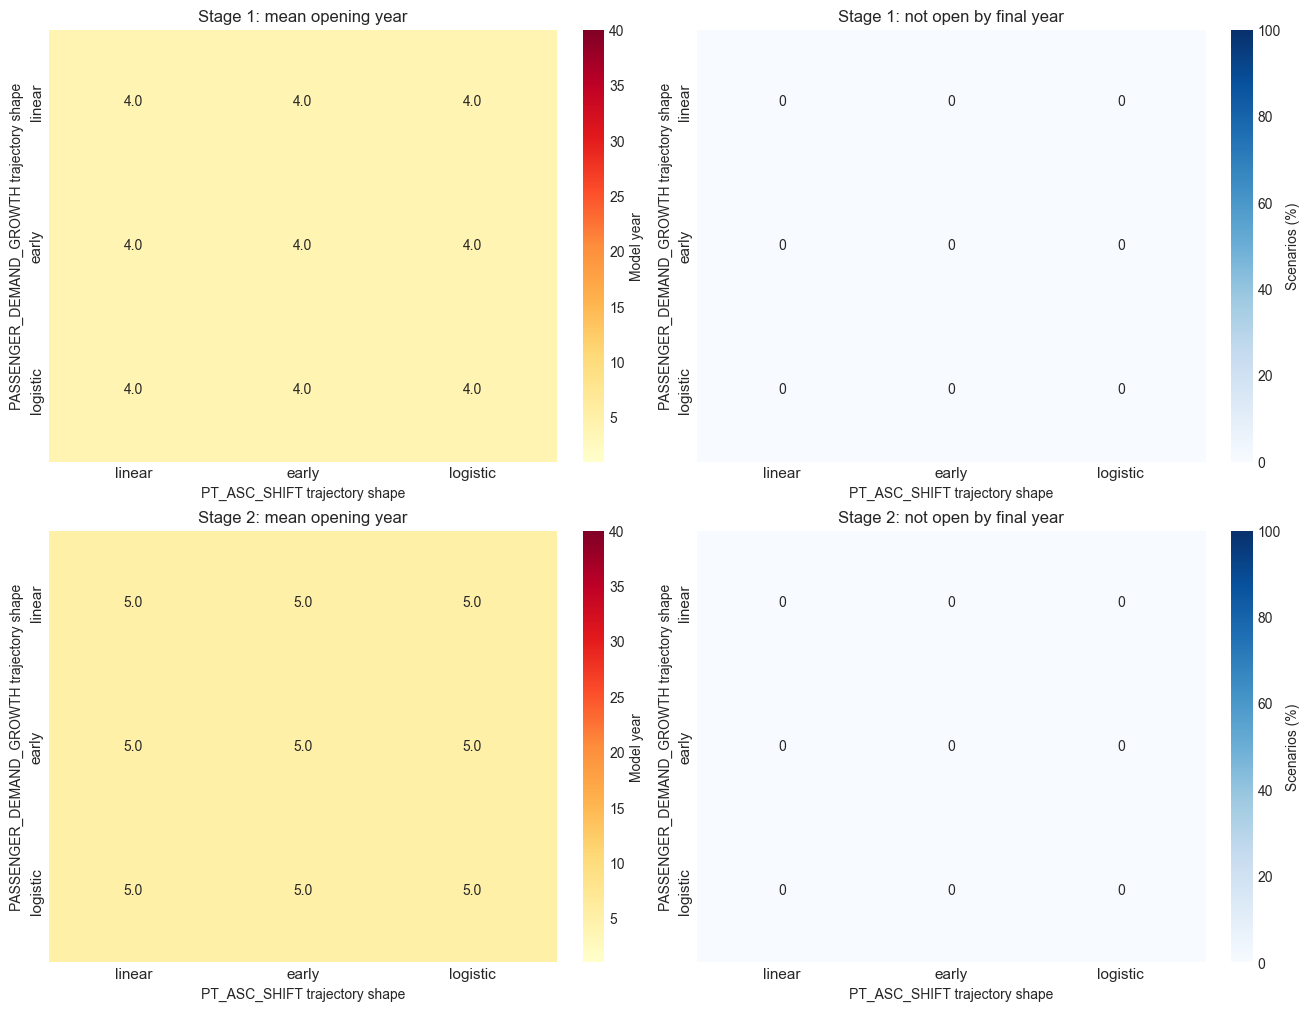

In [14]:
SHAPE_HEATMAP_INPUTS = [name for name in TRANSIENT_NAMES if name in TRANSPORT_NAMES][:2]
TIMING_SHAPES = ["linear", "early", "logistic"]
N_TIMING_SCENARIOS = 12
TIMING_SEED = 42

def draw_shape_heatmap(ax, table, *, title, color, fmt, label, vmin=None, vmax=None):
    if table.notna().any().any():
        sns.heatmap(table, annot=True, fmt=fmt, cmap=color, ax=ax, vmin=vmin, vmax=vmax,
                    cbar_kws={"label": label})
    else:
        ax.text(.5, .5, "No qualifying event in these scenarios", ha="center", va="center",
                transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=12)


if len(SHAPE_HEATMAP_INPUTS) != 2:
    print("Choose two transient transport uncertainties for this timing comparison.")
elif len(set(SHAPE_HEATMAP_INPUTS)) != 2 or any(name not in TRANSIENT_NAMES for name in SHAPE_HEATMAP_INPUTS):
    raise ValueError("SHAPE_HEATMAP_INPUTS needs two distinct selected transient uncertainty names.")
elif not TIMING_SHAPES or set(TIMING_SHAPES) - set(ap.SHAPES):
    raise ValueError(f"Choose TIMING_SHAPES from {ap.SHAPES}.")
else:
    from scipy.stats import qmc
    timing_draws = (qmc.LatinHypercube(d=len(SAMPLED_NAMES), seed=TIMING_SEED).random(N_TIMING_SCENARIOS)
                    if SAMPLED_NAMES else np.empty((N_TIMING_SCENARIOS, 0)))
    timing_rows = []
    for shape1 in TIMING_SHAPES:
        for shape2 in TIMING_SHAPES:
            shapes = dict(zip(SHAPE_HEATMAP_INPUTS, (shape1, shape2)))
            for scenario_id, values in enumerate(timing_draws):
                frame, meta = run_plan_gp("adaptive", STAGE_METRICS, params=example_parameters(),
                    shapes=shapes, **dict(zip(SAMPLED_NAMES, values)))
                timing_rows.append({"scenario": scenario_id, "shape1": shape1, "shape2": shape2,
                    **{f"opening{package}": meta.get(f"opening{package}_year") for package in (1, 2)}})
    timing_shape_results = pd.DataFrame(timing_rows)
    fig, axes = plt.subplots(2, 2, figsize=(13, 10), layout="constrained")
    shape_tables = {"runs": timing_shape_results,
        "sample_counts": pd.crosstab(timing_shape_results["shape1"], timing_shape_results["shape2"])}
    for row_index, package in enumerate((1, 2)):
        opening = pd.to_numeric(timing_shape_results[f"opening{package}"], errors="coerce")
        sample = timing_shape_results.assign(opening=opening.where(opening.between(1, N_YEARS)),
                                             not_open=~opening.between(1, N_YEARS))
        heat = sample.groupby(["shape1", "shape2"])["opening"].mean().unstack().reindex(
            index=TIMING_SHAPES, columns=TIMING_SHAPES)
        no_open = sample.groupby(["shape1", "shape2"])["not_open"].mean().unstack().reindex(
            index=TIMING_SHAPES, columns=TIMING_SHAPES) * 100
        draw_shape_heatmap(axes[row_index, 0], heat, title=f"Stage {package}: mean opening year",
                           color="YlOrRd", fmt=".1f", label="Model year", vmin=1, vmax=N_YEARS)
        draw_shape_heatmap(axes[row_index, 1], no_open, title=f"Stage {package}: not open by final year",
                           color="Blues", fmt=".0f", label="Scenarios (%)", vmin=0, vmax=100)
        shape_tables[f"stage{package}_mean_opening"] = heat
        shape_tables[f"stage{package}_not_open_percent"] = no_open
        for ax in axes[row_index]:
            ax.set_xlabel(SHAPE_HEATMAP_INPUTS[1] + " trajectory shape", fontsize=10)
            ax.set_ylabel(SHAPE_HEATMAP_INPUTS[0] + " trajectory shape", fontsize=10)
            ax.tick_params(labelsize=11)
    exports.save_outputs("02_4_implementation_shapes", figure=fig, tables=shape_tables)
    plt.show(); plt.close(fig)


## 2.5 Select the trajectories for the remaining analyses (mandatory task)

Set any `uncertainty: shape` pairs below. Unlisted transient uncertainties use `linear`; an empty dictionary makes every trajectory linear. Available shapes are `linear`, `early`, `late`, `logistic`, `almost_flat` and `random_walk`. `almost_flat` postpones most change until the end; `random_walk` adds reproducible fluctuations while retaining the sampled endpoint.

For MehrSpur, the example uses **logistic e-bike adoption**: slower initial uptake, faster change around the middle of the horizon, then slower uptake again. This is a teaching assumption, not a fitted adoption forecast. Passenger demand, PT preference, road freight and other transient uncertainties remain **linear**, avoiding an unsupported assumption about when their changes accelerate. The endpoint distributions remain those in `parameters.py`.

The figure shows representative physical parameter paths, with the known baseline and sampled endpoints. These fixed shape choices are used throughout Parts 3–5, including the planning game. Change this cell and rerun the following analyses to compare another set of assumptions. The temporary trigger overrides used in Part 2 do not carry forward; the ensemble uses the rules in Section 1.2.


cell running: 00:00

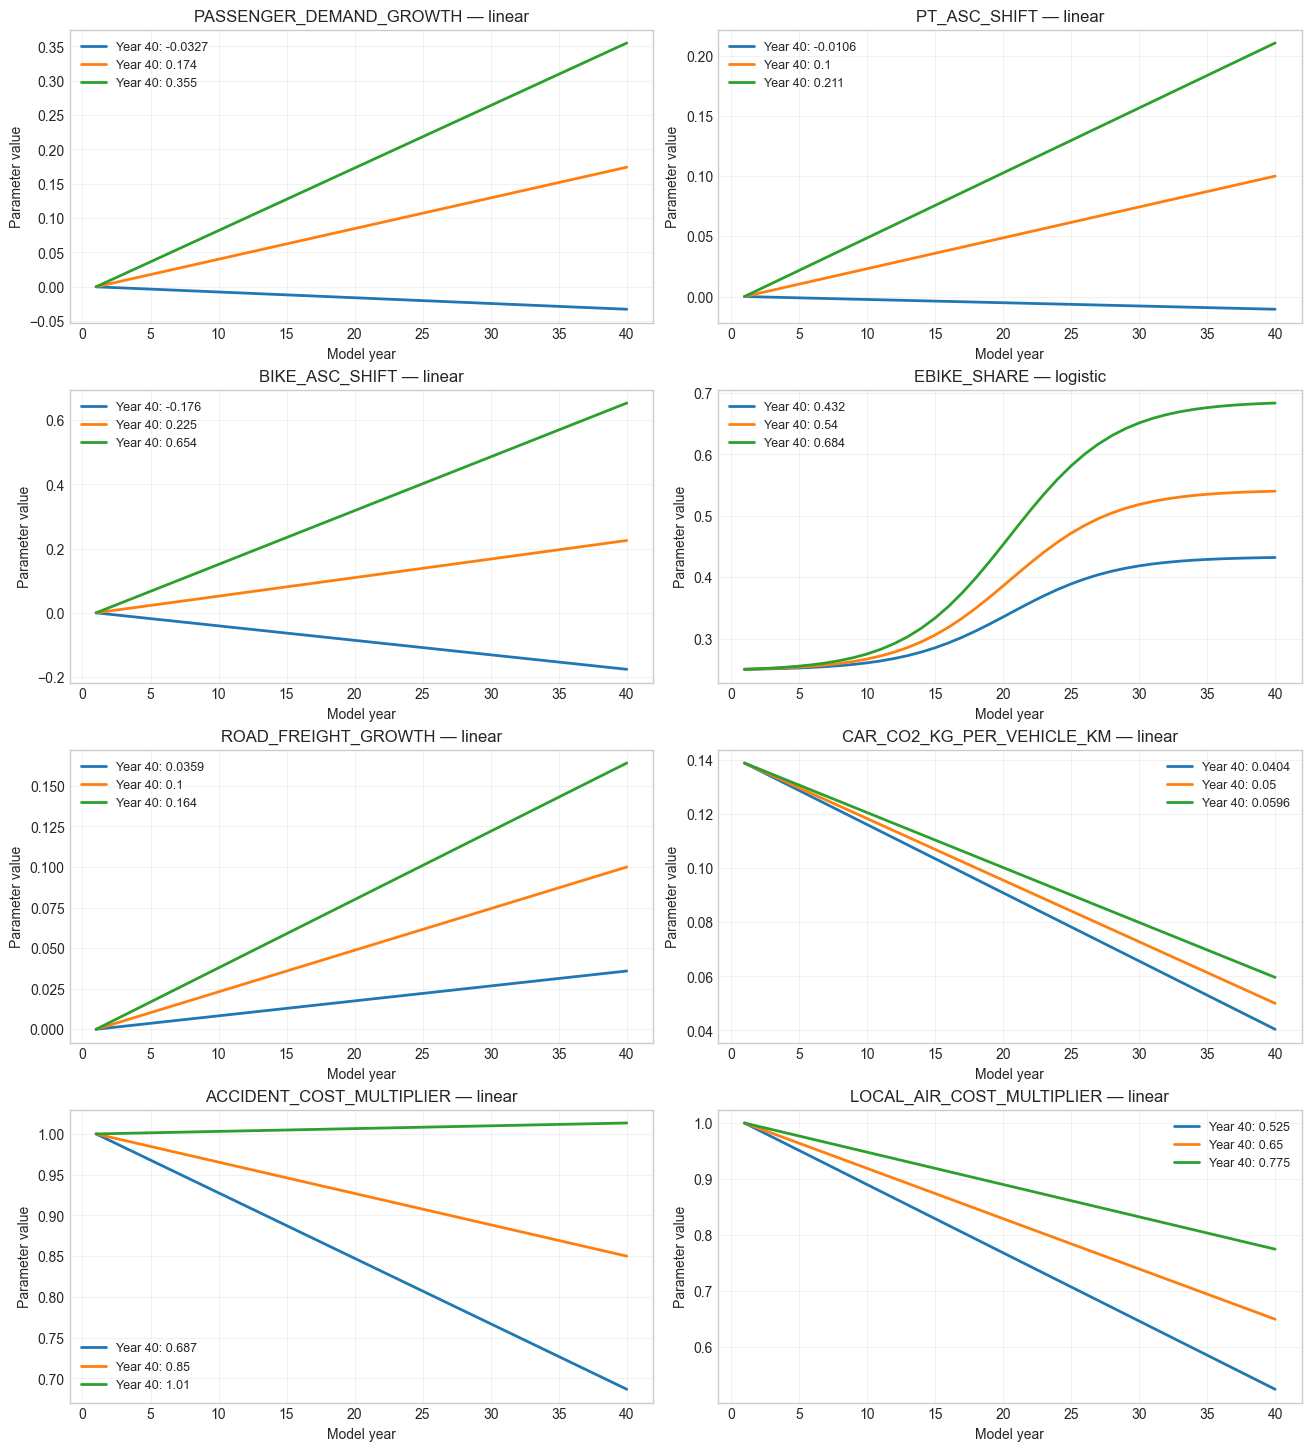

In [15]:
# Add or remove pairs. Every unlisted transient uncertainty is linear.
UNCERTAINTY_SHAPES = {"EBIKE_SHARE": "logistic"} if "EBIKE_SHARE" in TRANSIENT_NAMES else {}

if set(UNCERTAINTY_SHAPES) - set(TRANSIENT_NAMES):
    raise ValueError(f"Choose transient uncertainties from {TRANSIENT_NAMES}.")
if set(UNCERTAINTY_SHAPES.values()) - set(ap.SHAPES):
    raise ValueError(f"Choose trajectory shapes from {ap.SHAPES}.")
SELECTED_SHAPES = {name: UNCERTAINTY_SHAPES.get(name, "linear") for name in TRANSIENT_NAMES}
selected_shape_rows = []
if SELECTED_SHAPES:
    fig, axes = plt.subplots((len(SELECTED_SHAPES) + 1) // 2, 2,
        figsize=(13, 3.6 * ((len(SELECTED_SHAPES) + 1) // 2)), squeeze=False, layout="constrained")
    for ax, (name, shape) in zip(axes.flat, SELECTED_SHAPES.items()):
        draws = (.1, .5, .9) if name in SAMPLED_NAMES else (None,)
        for draw in draws:
            path = uc.clip_transport_paths({name: uc.get_trajectory(name, draw, shape, nominal=NOTEBOOK_PARAMS)})[name]
            label = f"Year {N_YEARS}: {path[-1]:.3g}"
            ax.plot(years, path, lw=2, label=label)
            selected_shape_rows.extend({"parameter": name, "shape": shape, "year": year, "value": value,
                                        "endpoint": path[-1]} for year, value in zip(years, path))
        ax.set(title=f"{name} — {shape.replace('_', ' ')}", xlabel="Model year", ylabel="Parameter value")
        ax.legend(fontsize=9)
        ax.grid(alpha=.25)
    for ax in list(axes.flat)[len(SELECTED_SHAPES):]:
        ax.set_axis_off()
    exports.save_outputs("02_5_selected_shapes", figure=fig,
        tables={"paths": pd.DataFrame(selected_shape_rows),
                "choices": pd.Series(SELECTED_SHAPES, name="shape").rename_axis("parameter").to_frame()})
    plt.show(); plt.close(fig)
else:
    print("No selected transient uncertainties; the model uses deterministic nominal paths.")


# Part 3 — Compare plans across scenarios
<a id="compare-plans"></a>

## 3.1 Run the shared-scenarios ensemble (mandatory task)

Now, plans are tested against the same set of scenarios. The default set comes from uncertainties marked `scenarios` in `parameters.py`; the uncertainty selection is in Setup and the final trajectory shapes are selected in Section 2.5.

The summary reports final PT share and, when a counting section is active, final load/capacity. `years_in_failure` counts a year once whenever **either active requirement fails**: PT share from Year 20 and load/capacity throughout.


In [16]:
N_SCENARIOS = 200
EXPERIMENT_SEED = 42

OUTCOME_INDICATORS = indicator_selection(list(INDICATOR_CATALOG))
TRAJ_COLS = list(dict.fromkeys(
    OUTCOME_INDICATORS + ["stage", "comparison_cost", "inv_cost", "upfront_cost", "op_cost", "investment_pv", "operation_pv", "discount_rate"]
))


def plan_ema_model(plan="baseline", **kwargs):
    """Evaluate one shared scenario using the registry's draws and nominal defaults."""
    draws = {name: kwargs[name] for name in SAMPLED_NAMES if name in kwargs}
    shapes = SELECTED_SHAPES.copy()
    df, meta = run_plan_gp(plan, STAGE_METRICS, shapes=shapes, **draws)
    acceptable = performance_mask(df)
    out = {col: df[col].values for col in TRAJ_COLS}
    out.update({
        "final_stage": int(df["stage"].iloc[-1]),
        "years_in_stage1": int((df["stage"] == 1).sum()),
        "years_in_stage2": int((df["stage"] == 2).sum()),
        "years_in_stage3": int((df["stage"] == 3).sum()),
        "final_pt_share": float(df["pt_share"].iloc[-1]),
        "final_car_share": float(df["car_share"].iloc[-1]),
        "final_avg_travel_time": float(df["avg_tt_min"].iloc[-1]),
        "cumulative_total_travel_time": float(df["total_travel_time_hours"].sum()),
        "max_travel_time": float(df["avg_tt_min"].max()),
        "min_pt_share": float(df["pt_share"].min()),
        "years_in_failure": int((~acceptable).sum()),
        "pct_acceptable_years": float(acceptable.mean() * 100),
        "total_cost": float(df["comparison_cost"].sum()),
        "total_construction_co2_tonnes": float(df["construction_co2_tonnes"].sum()),
        "stage1_activation_year": meta["opening1_year"] or 0,
        "stage2_activation_year": meta["opening2_year"] or 0,
        "stage1_scheduled_opening_year": meta["activation1_year"] or meta["opening1_year"] or 0,
        "stage2_scheduled_opening_year": meta["activation2_year"] or meta["opening2_year"] or 0,
        "decision1_year": meta["decision1_year"] or 0,
        "decision2_year": meta["decision2_year"] or 0,
    })
    out.update({"final_" + key: float(df[key].iloc[-1]) for key in OUTCOME_INDICATORS})
    return out

SCALAR_COLS = [
    "final_stage", "years_in_stage1", "years_in_stage2", "years_in_stage3", "final_pt_share", "final_car_share",
    "final_avg_travel_time", "cumulative_total_travel_time", "max_travel_time", "min_pt_share",
    "years_in_failure", "pct_acceptable_years", "total_cost", "total_construction_co2_tonnes",
    "stage1_activation_year", "stage2_activation_year", "stage1_scheduled_opening_year", "stage2_scheduled_opening_year", "decision1_year", "decision2_year",
]
SCALAR_COLS = list(dict.fromkeys(SCALAR_COLS + ["final_" + key for key in OUTCOME_INDICATORS]))
plan_model = Model("AdaptivePlans", function=plan_ema_model)
plan_model.uncertainties = [RealParameter(name, 0.0, 1.0) for name in SAMPLED_NAMES]
plan_model.levers = [CategoricalParameter("plan", PLAN_NAMES)]
plan_model.outcomes = [TimeSeriesOutcome(c) for c in TRAJ_COLS] + [ScalarOutcome(c) for c in SCALAR_COLS]
ema_plans = [Policy(name, plan=name) for name in PLAN_NAMES]

np.random.seed(EXPERIMENT_SEED)
with SequentialEvaluator(plan_model) as evaluator:
    ema_experiments, ema_outcomes = perform_experiments(
        plan_model, N_SCENARIOS if len(plan_model.uncertainties) else [Scenario(str(i)) for i in range(N_SCENARIOS)],
        policies=ema_plans, evaluator=evaluator,
        uncertainty_sampling=Samplers.LHS, log_progress=True,
    )

ema_experiments = ema_experiments.copy()
ema_experiments["scenario"] = ema_experiments["scenario"].astype(int)
shape_cols = list(SHAPE_COLUMNS.values())
for name, column in SHAPE_COLUMNS.items():
    ema_experiments[column] = SELECTED_SHAPES[name]
for col in ["plan"] + shape_cols:
    ema_experiments[col] = ema_experiments[col].astype(str)
unc_cols = SAMPLED_NAMES + shape_cols
n_exp = len(ema_experiments)
trajectories_df = pd.DataFrame({"year": np.tile(np.arange(1, N_YEARS + 1), n_exp)})
for col in TRAJ_COLS:
    trajectories_df[col] = ema_outcomes[col].ravel()
for col in ["scenario", "plan"] + unc_cols:
    trajectories_df[col] = np.repeat(ema_experiments[col].values, N_YEARS)
summary_df = ema_experiments[["scenario", "plan"] + unc_cols].copy()
for col in SCALAR_COLS:
    summary_df[col] = ema_outcomes[col]
scenarios = (ema_experiments[ema_experiments["plan"] == PLAN_NAMES[0]][
    ["scenario"] + unc_cols
].to_dict("records"))

# Paired differences compare each plan with the same scenario's baseline.
baseline_summary = summary_df.loc[summary_df["plan"] == "baseline"].set_index("scenario")
for key, target, scale in (
    ("final_pt_share", "delta_final_pt_share_pp", 100.0),
    ("final_pt_journey_time_min", "delta_final_pt_journey_time_min", 1.0),
):
    summary_df[target] = (summary_df[key] - summary_df["scenario"].map(baseline_summary[key])) * scale
for key, target in (
    ("congestion_delay_hours", "delta_cumulative_road_delay_hours"),
    ("operating_co2_tonnes", "delta_cumulative_operating_co2_tonnes"),
):
    totals = trajectories_df.groupby(["scenario", "plan"])[key].sum()
    baseline_total = totals.xs("baseline", level="plan")
    summary_df[target] = [totals.loc[(row.scenario, row.plan)] - baseline_total.loc[row.scenario]
                          for row in summary_df.itertuples()]
summary_df["meets_all_requirements"] = summary_df["years_in_failure"].eq(0)

print(f"{len(summary_df):,} pathways = {N_SCENARIOS} scenarios x {len(PLAN_NAMES)} plans; no new MSA runs.")
print(BUDGET_LABEL + "; summed over the modeled horizon.")
SUMMARY_INDICATORS = ["final_pt_share", "final_section_load_ratio", "pct_acceptable_years",
                      "years_in_failure", "total_cost", "total_construction_co2_tonnes"]
summary_columns = [key for key in SUMMARY_INDICATORS if key in summary_df and summary_df[key].notna().any()]
show_table("04_plan_summary", summary_df.groupby("plan")[summary_columns].mean().round(3).reindex(PLAN_NAMES))

# Sampling coordinates stay internal; exports report applied Year-40 inputs.
summary_export = physical_inputs(summary_df)
for key in ("stage1_activation_year", "stage2_activation_year", "stage1_scheduled_opening_year",
            "stage2_scheduled_opening_year", "decision1_year", "decision2_year"):
    summary_export[key] = summary_export[key].where(summary_export[key] > 0)
exports.save_outputs("04_pathways", tables={
    "summary": summary_export,
    "trajectories": physical_inputs(trajectories_df),
    "scenarios": physical_inputs(pd.DataFrame(scenarios)),
})


cell running: 00:00

/Users/liviagysel/Documents/ETHZ/REIS Master/Infrastructure Planning/IP-HS26-MehrSpur-CaseStudy/code/additional/uncertainty.py:229: UserWarning: ROAD_FREIGHT_GROWTH exceeds its surrogate training range; clipping the trajectory to [-0.05451161530839066, 0.25451161530839067]. Review uncertainty tails or rebuild with wider coverage.
  return clip_transport_paths({key: get_trajectory(key, draws.get(key), shapes.get(key, "linear"), nominal=nominal)
/Users/liviagysel/Documents/ETHZ/REIS Master/Infrastructure Planning/IP-HS26-MehrSpur-CaseStudy/code/additional/uncertainty.py:229: UserWarning: ROAD_FREIGHT_GROWTH exceeds its surrogate training range; clipping the trajectory to [-0.05451161530839066, 0.25451161530839067]. Review uncertainty tails or rebuild with wider coverage.
  return clip_transport_paths({key: get_trajectory(key, draws.get(key), shapes.get(key, "linear"), nominal=nominal)
/Users/liviagysel/Documents/ETHZ/REIS Master/Infrastructure Planning/IP-HS26-MehrSpur-CaseStudy/code/add

1,200 pathways = 200 scenarios x 6 plans; no new MSA runs.
Present value of infrastructure expenditure (CHF); summed over the modeled horizon.


,final_pt_share,final_section_load_ratio,pct_acceptable_years,years_in_failure,total_cost,total_construction_co2_tonnes
plan,,,,,,
baseline,0.403,1.234,54.250,18.300,0.000000e+00,0.0
static1,0.402,1.235,54.650,18.140,4.382369e+07,0.0
static2,0.400,1.234,54.162,18.335,4.792962e+07,0.0
staged1,0.400,1.234,54.225,18.310,4.706063e+07,0.0
staged2,0.400,1.234,54.425,18.230,4.626042e+07,0.0
adaptive,0.400,1.234,54.162,18.335,1.442467e+08,0.0


{'table:summary': PosixPath('/Users/liviagysel/Documents/ETHZ/REIS Master/Infrastructure Planning/IP-HS26-MehrSpur-CaseStudy/results/04_adaptive_planning/04_pathways_summary.csv'),
 'table:trajectories': PosixPath('/Users/liviagysel/Documents/ETHZ/REIS Master/Infrastructure Planning/IP-HS26-MehrSpur-CaseStudy/results/04_adaptive_planning/04_pathways_trajectories.csv'),
 'table:scenarios': PosixPath('/Users/liviagysel/Documents/ETHZ/REIS Master/Infrastructure Planning/IP-HS26-MehrSpur-CaseStudy/results/04_adaptive_planning/04_pathways_scenarios.csv')}

## 3.2 Fan charts by plan family (mandatory task)

The selected `FAN_INDICATORS` show medians, interquartile ranges and p10–p90 intervals. The defaults show PT share, road delay and section load/capacity. Section load/capacity is omitted when no active PT counting section is configured. Select additional outcomes at the top of the following block. Requirements are shown over the years in which they apply.


cell running: 00:00

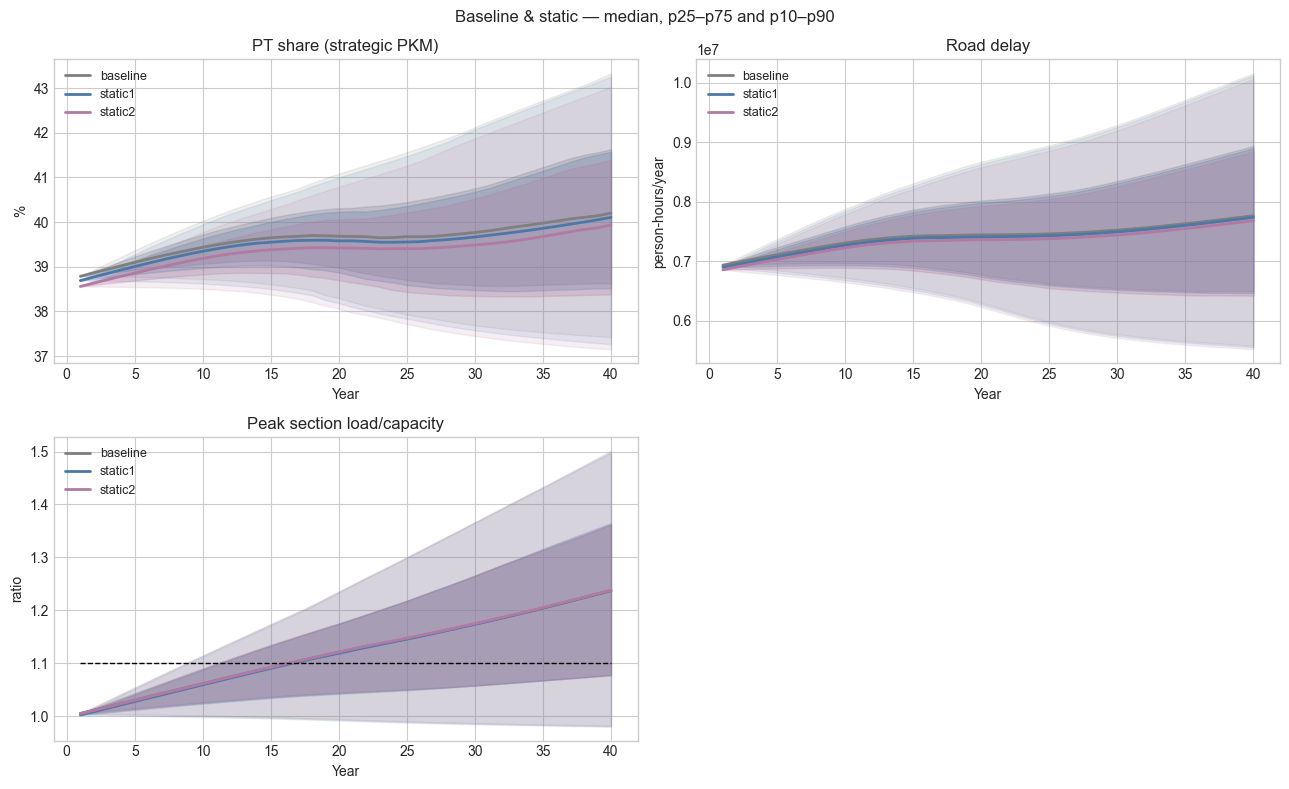

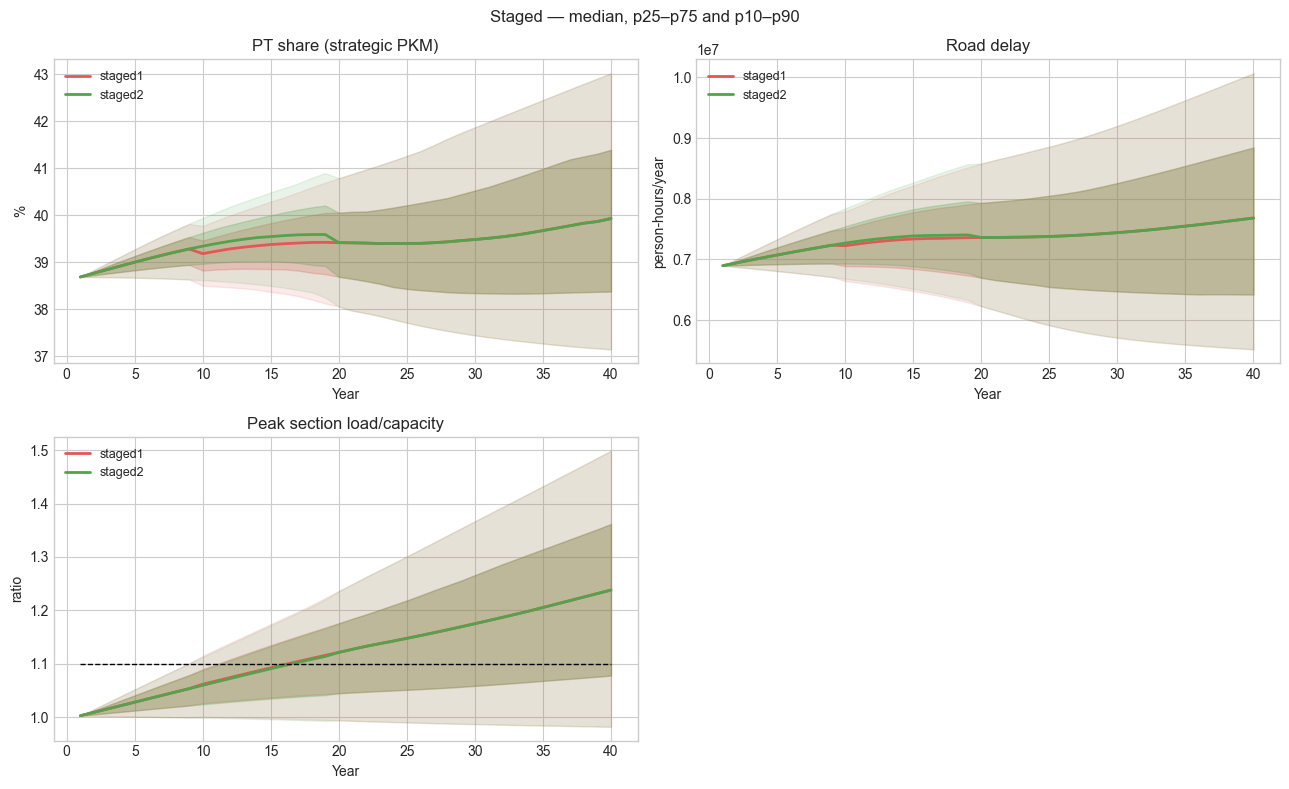

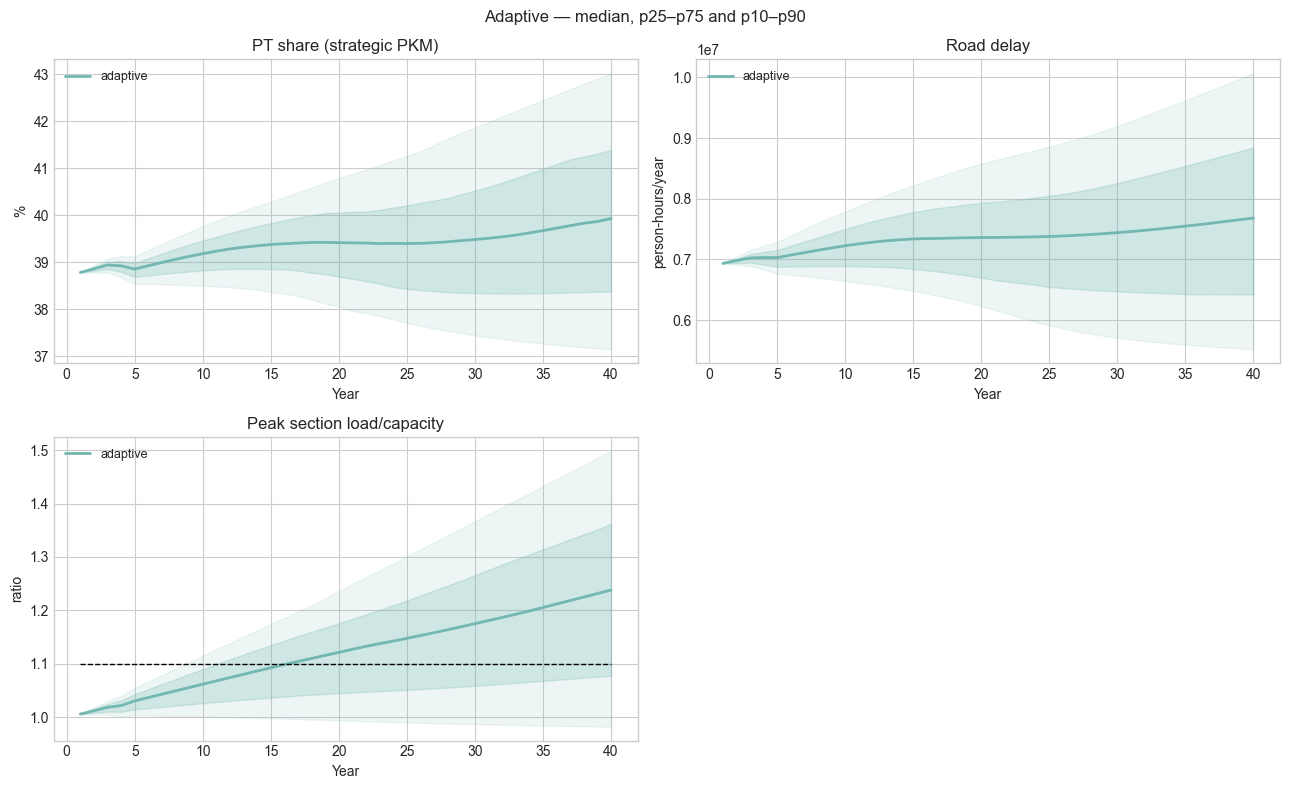

In [17]:
FAN_INDICATORS = ["pt_share", "congestion_delay_hours", "section_load_ratio"]

FAN_OBJECTIVES = [
    (key, indicator_label(key), lambda values, key=key: values * indicator_scale(key), indicator_unit(key), None)
    for key in indicator_selection(FAN_INDICATORS)
]
PLAN_GROUPS = {"Baseline & static": ["baseline", "static1", "static2"],
               "Staged": ["staged1", "staged2"], "Adaptive": ["adaptive"]}

def fan_chart_grid(plans, group_title):
    keys = indicator_selection(FAN_INDICATORS)
    if not keys:
        print("Select an available FAN_INDICATORS entry.")
        return
    fig, axes = plt.subplots((len(keys) + 1) // 2, 2, figsize=(13, 4 * ((len(keys) + 1) // 2)), squeeze=False)
    tables = []
    for ax, key in zip(axes.flat, keys):
        for plan_name in plans:
            sub = trajectories_df.loc[trajectories_df["plan"].eq(plan_name)]
            percentiles = sub.groupby("year")[key].quantile([.1, .25, .5, .75, .9]).unstack() * indicator_scale(key)
            ax.fill_between(percentiles.index, percentiles[.1], percentiles[.9], color=PLAN_COLORS[plan_name], alpha=.12)
            ax.fill_between(percentiles.index, percentiles[.25], percentiles[.75], color=PLAN_COLORS[plan_name], alpha=.25)
            ax.plot(percentiles.index, percentiles[.5], color=PLAN_COLORS[plan_name], label=plan_name, lw=2)
            tables.append(percentiles.rename(columns=lambda q: f"p{int(q * 100)}").reset_index().assign(plan=plan_name, indicator=key))
        for rule in PERFORMANCE_REQUIREMENTS:
            if rule["indicator"] == key:
                ax.hlines(rule["threshold"] * indicator_scale(key), rule.get("start_year", 1), rule.get("end_year", N_YEARS), color="black", ls="--", lw=1)
        ax.set(title=indicator_label(key), xlabel="Year", ylabel=indicator_unit(key))
        ax.legend(fontsize=9)
    for ax in axes.flat[len(keys):]: ax.set_axis_off()
    fig.suptitle(group_title + " — median, p25–p75 and p10–p90")
    fig.tight_layout()
    exports.save_outputs("04_fan_" + group_title, figure=fig, tables={"percentiles": pd.concat(tables, ignore_index=True)})
    plt.show()
    plt.close(fig)

for group_title, plans in PLAN_GROUPS.items():
    fan_chart_grid(plans, group_title)


## 3.3 Paired Year-40 changes relative to the baseline (tutorial/supporting task)

Each project outcome is compared with the baseline **in the same scenario**. The ECDF shows the distribution of those paired differences, not a difference between unrelated scenarios or between medians. Zero means no change. Shares are shown in percentage points and other indicators in their own units. Select the indicators through `YEAR40_INDICATORS` at the top of the following block. The default comparison is shown before the optional plan selector.

Plans operating the same configuration in Year 40 can overlap. Their earlier performance and opening dates are compared in the trajectory and timing analyses.


cell running: 00:00

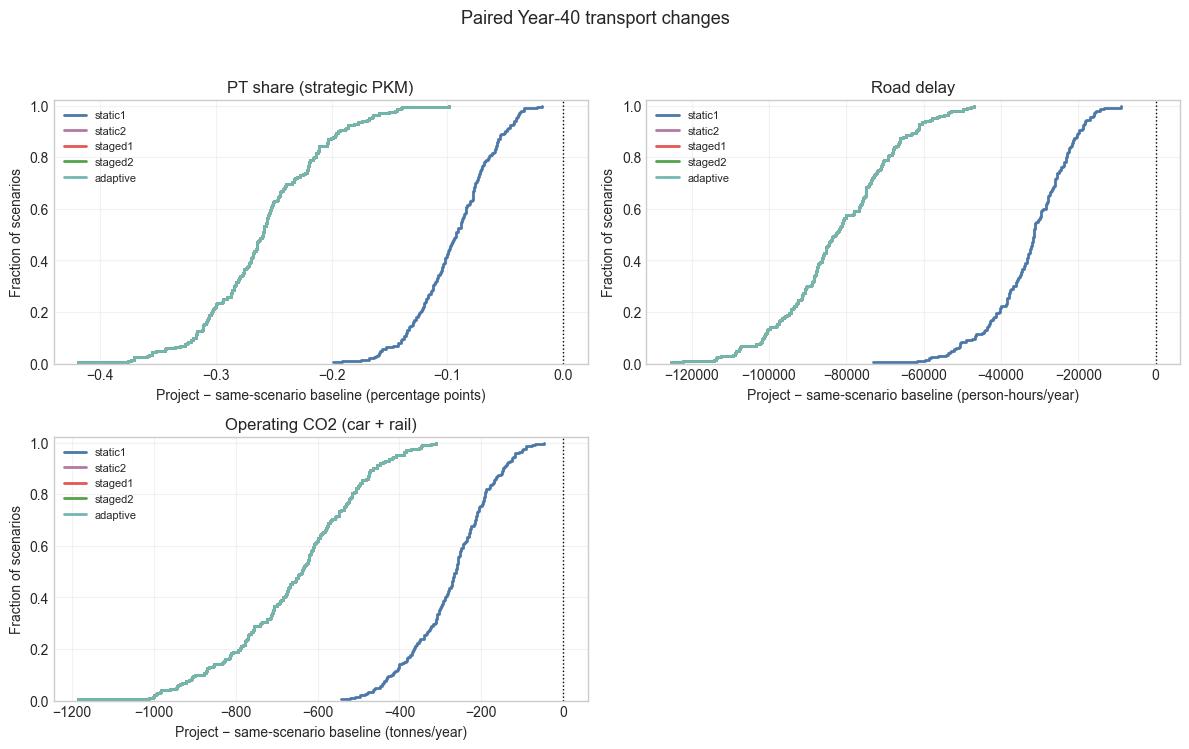

Accordion(children=(VBox(children=(SelectMultiple(description='Plans:', index=(0, 1, 2, 3, 4), options=('stati…

In [18]:
YEAR40_INDICATORS = ["pt_share", "congestion_delay_hours", "operating_co2_tonnes"]

year40_keys = indicator_selection(YEAR40_INDICATORS)
final_year = trajectories_df["year"].max()
year40 = trajectories_df.loc[trajectories_df["year"] == final_year,
                            ["scenario", "plan", *year40_keys]].copy()
if year40.duplicated(["scenario", "plan"]).any():
    raise ValueError("Each plan needs exactly one final-year row per scenario.")
reference40 = year40.loc[year40["plan"] == "baseline", ["scenario", *year40_keys]]
paired_year40 = year40.loc[year40["plan"] != "baseline"].merge(
    reference40, on="scenario", how="left", suffixes=("", "_baseline"), validate="many_to_one", indicator=True)
if paired_year40["_merge"].ne("both").any():
    raise ValueError("Missing same-scenario baseline rows; rerun the shared-scenarios ensemble.")
for indicator in year40_keys:
    paired_year40[indicator] = (paired_year40[indicator] - paired_year40[indicator + "_baseline"]) * indicator_scale(indicator)
paired_year40 = paired_year40[["scenario", "plan", *year40_keys]]
exports.save_outputs("03_3_paired_year40", tables={"changes": paired_year40})

def plot_paired_year40(selected_plans):
    if not year40_keys:
        print("Choose at least one available YEAR40_INDICATORS entry at the top of this block."); return
    if not selected_plans:
        print("Select at least one project plan."); return
    fig, axes = plt.subplots((len(year40_keys) + 1) // 2, 2,
                             figsize=(12, 3.8 * ((len(year40_keys) + 1) // 2)), squeeze=False)
    for ax, indicator in zip(axes.flat, year40_keys):
        for name in selected_plans:
            values = np.sort(paired_year40.loc[paired_year40["plan"] == name, indicator].dropna())
            if len(values):
                ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post",
                        color=PLAN_COLORS[name], lw=2, label=name)
        unit = ("percentage points" if INDICATOR_CATALOG[indicator].get("format") == "percent"
                else indicator_unit(indicator))
        ax.axvline(0, color="black", ls=":", lw=1)
        ax.set(title=indicator_label(indicator), xlabel=f"Project − same-scenario baseline ({unit})",
               ylabel="Fraction of scenarios", ylim=(0, 1.02))
        finite = paired_year40[indicator].replace([np.inf, -np.inf], np.nan).dropna()
        if len(finite):
            lo, hi = min(0., finite.min()), max(0., finite.max())
            pad = (hi - lo) * .05 if hi > lo else .01
            ax.set_xlim(lo - pad, hi + pad)
        ax.grid(alpha=.25); ax.legend(fontsize=8)
    for ax in list(axes.flat)[len(year40_keys):]: ax.set_axis_off()
    fig.suptitle(f"Paired Year-{final_year} transport changes", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, .95))
    exports.save_outputs("03_3_paired_year40", figure=fig)
    plt.show(); plt.close(fig)

year40_plans = [name for name in PLAN_SPECS if name != "baseline"]
plot_paired_year40(year40_plans)
year40_select = widgets.SelectMultiple(options=year40_plans, value=tuple(year40_plans), description="Plans:")
year40_button = widgets.Button(description="Update comparison", button_style="primary")
year40_output = widgets.Output()
run_button(year40_button, year40_output, lambda: plot_paired_year40(year40_select.value))
year40_controls = widgets.Accordion(children=[widgets.VBox([year40_select, year40_button, year40_output])])
year40_controls.set_title(0, "Optional: select plans")
year40_controls.selected_index = None
display(year40_controls)


## 3.4 Ensemble spread, central performance and target attainment (mandatory task)

The parallel-coordinate plots use `PARCOORD_COLS` at the top of the following block. Their shared axes show the full spread and the median of each indicator; a median profile need not represent any single scenario. Every axis places favourable values at the top: higher shares/attainment and lower time, delay, emissions or expenditure. Directions come from the indicator catalogue or `PARCOORD_DIRECTIONS` in this block. Axis ranges, top/bottom values and medians are also reported in physical units.

Default comparisons include years meeting all requirements, paired Year-40 PT share and complete PT journey time, cumulative paired road delay and operating CO2, and present-value infrastructure expenditure. Changes are **plan minus the same-scenario baseline**: positive PT-share changes and negative delay/time/emissions changes are favourable on their respective axes. Passenger composition can change the average PT journey time. These physical comparisons are not welfare estimates; total travel hours also depend on demand and trip composition.

The separate robustness figure reports the proportion of sampled scenarios meeting every active requirement throughout its applicable years, and the duration of failure. The PT-share requirement starts in Year 20; comfort applies throughout. Read expenditure alongside these outcomes rather than treating minimum spending as the best plan.


cell running: 00:00

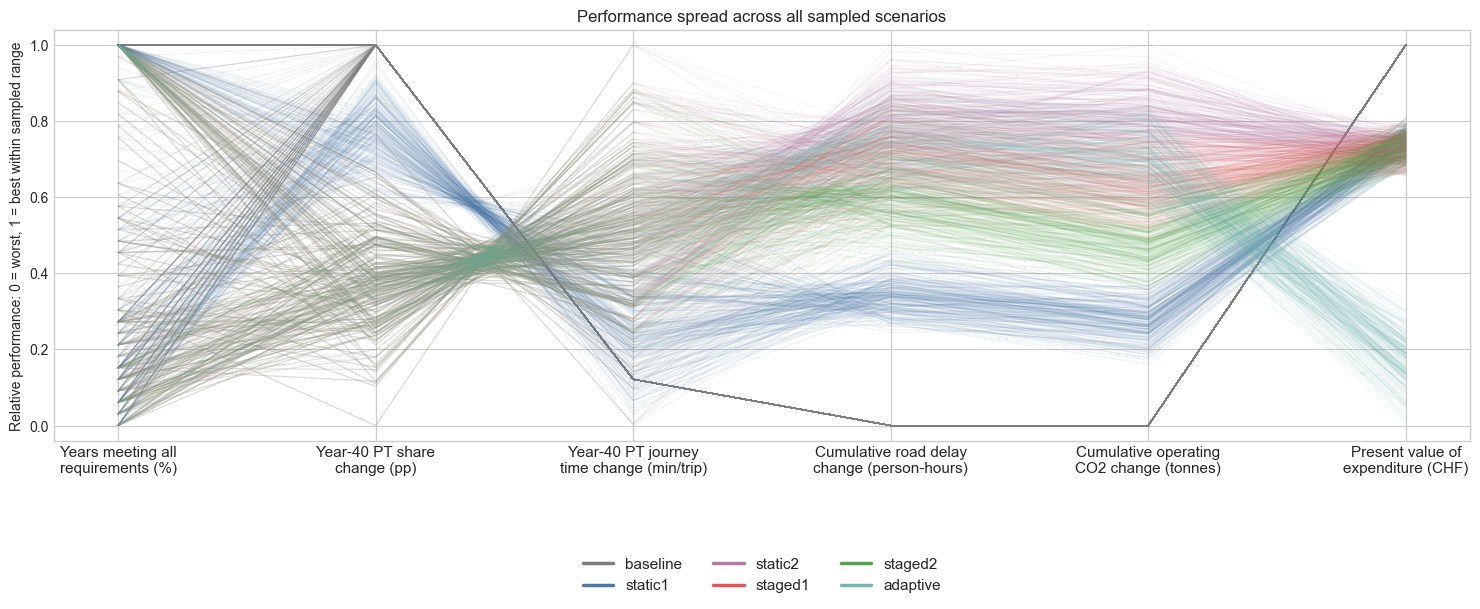

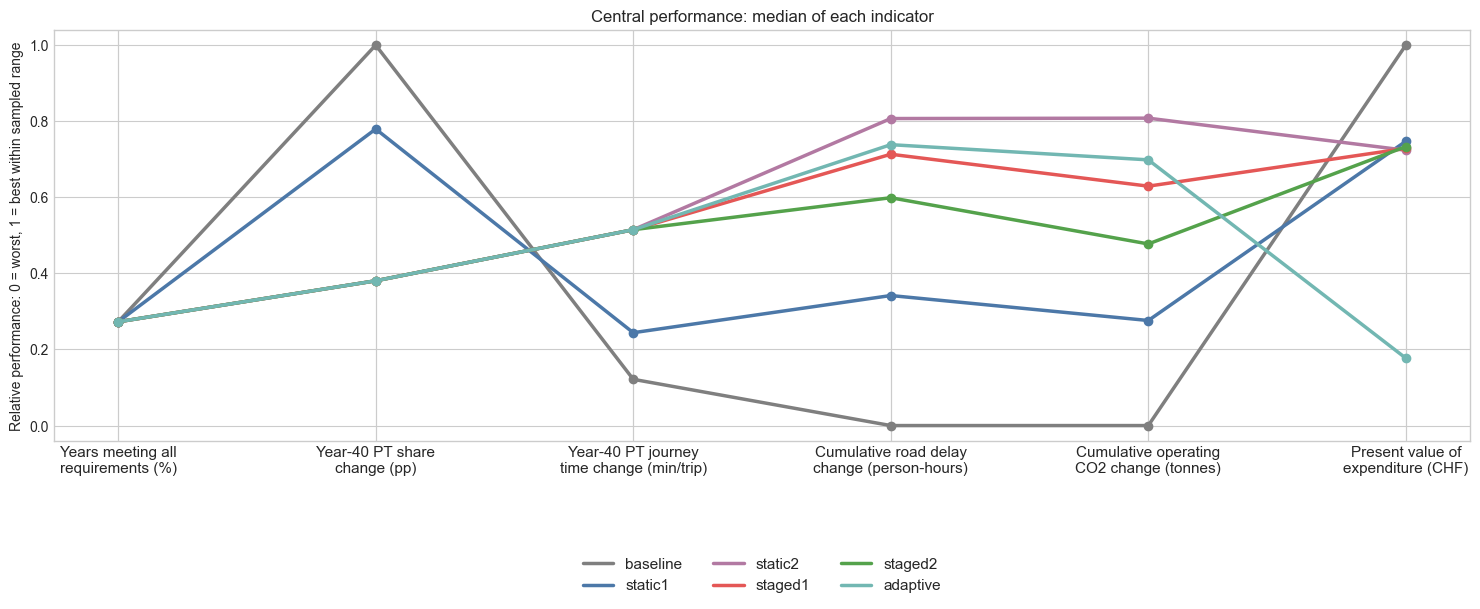

,minimum,maximum,favourable_direction,bottom_value,top_value
pct_acceptable_years,1.750000e+01,1.000000e+02,higher,1.750000e+01,1.000000e+02
delta_final_pt_share_pp,-4.187378e-01,0.000000e+00,higher,-4.187378e-01,0.000000e+00
delta_final_pt_journey_time_min,-3.713572e-02,5.139795e-03,lower,5.139795e-03,-3.713572e-02
delta_cumulative_road_delay_hours,-4.053423e+06,0.000000e+00,lower,0.000000e+00,-4.053423e+06
delta_cumulative_operating_co2_tonnes,-6.212363e+04,0.000000e+00,lower,0.000000e+00,-6.212363e+04
total_cost,0.000000e+00,1.734926e+08,lower,1.734926e+08,0.000000e+00


,pct_acceptable_years,delta_final_pt_share_pp,delta_final_pt_journey_time_min,delta_cumulative_road_delay_hours,delta_cumulative_operating_co2_tonnes,total_cost
plan,,,,,,
baseline,40.0,0.000,0.000,0.000,0.000,0.000000e+00
static1,40.0,-0.092,-0.005,-1385362.513,-17154.146,4.384412e+07
static2,40.0,-0.259,-0.017,-3270972.088,-50195.837,4.795197e+07
staged1,40.0,-0.259,-0.017,-2890692.809,-39091.006,4.709199e+07
staged2,40.0,-0.259,-0.017,-2427440.989,-29654.863,4.628378e+07
adaptive,40.0,-0.259,-0.017,-2992678.515,-43386.252,1.427703e+08


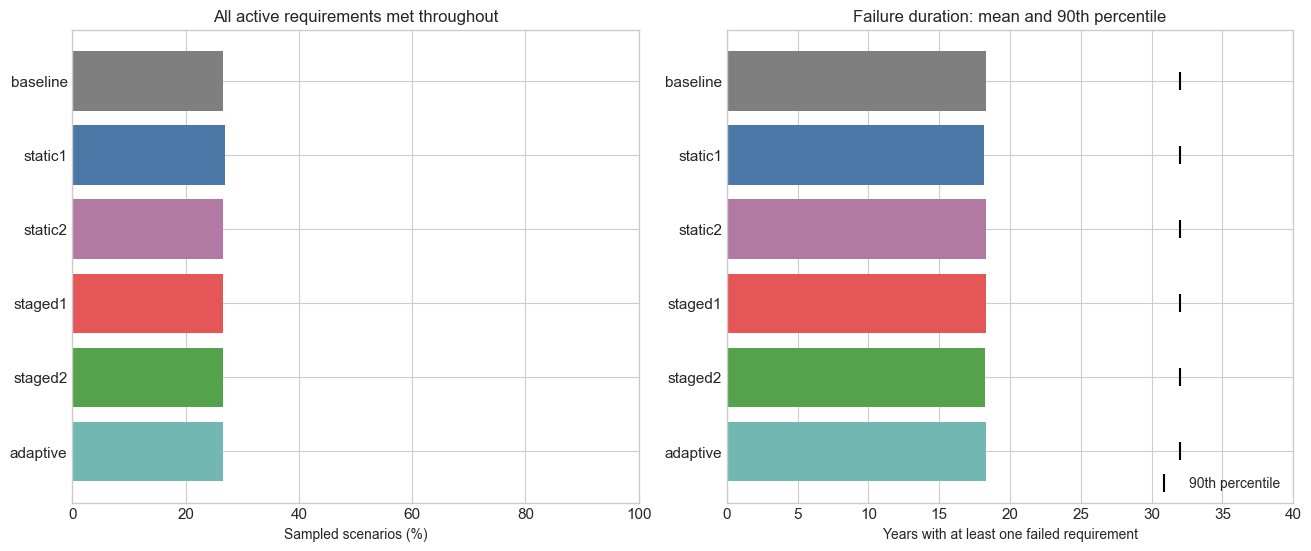

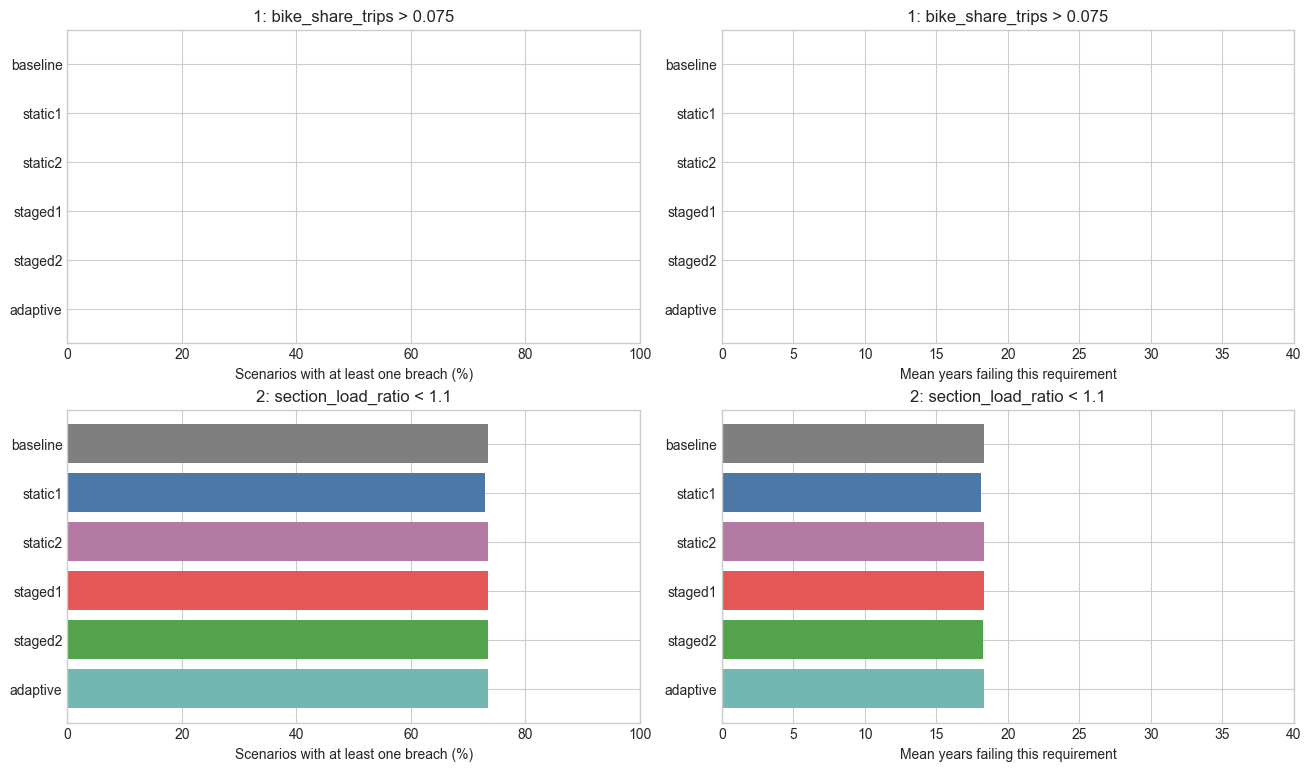

In [19]:
# Final outcomes use final_<catalogue key>, e.g. final_bike_share_trips.
PARCOORD_COLS = [
    "pct_acceptable_years", "delta_final_pt_share_pp", "delta_final_pt_journey_time_min",
    "delta_cumulative_road_delay_hours", "delta_cumulative_operating_co2_tonnes", "total_cost",
]

# Favourable direction for these summary outcomes; other indicators use the catalogue.
# Add an entry here when selecting an outcome without a higher/lower direction.
PARCOORD_DIRECTIONS = {
    "pct_acceptable_years": "higher",
    "delta_final_pt_share_pp": "higher",
    "delta_final_pt_journey_time_min": "lower",
    "delta_cumulative_road_delay_hours": "lower",
    "delta_cumulative_operating_co2_tonnes": "lower",
    "total_cost": "lower",
}

from textwrap import fill

special_labels = {
    "pct_acceptable_years": "Years meeting all requirements (%)",
    "delta_final_pt_share_pp": "Year-40 PT share change (pp)",
    "delta_final_pt_journey_time_min": "Year-40 PT journey time change (min/trip)",
    "delta_cumulative_road_delay_hours": "Cumulative road delay change (person-hours)",
    "delta_cumulative_operating_co2_tonnes": "Cumulative operating CO2 change (tonnes)",
    "total_cost": "Present value of expenditure (CHF)",
}
if not PARCOORD_COLS or set(PARCOORD_COLS) - set(summary_df):
    raise ValueError("Choose PARCOORD_COLS from summary_df; rerun Part 3 for new outcomes.")
if any("year" in key and ("activation" in key or "opening" in key or "decision" in key) for key in PARCOORD_COLS):
    raise ValueError("Use Part 5 for dates: non-implementation cannot share a numerical performance axis.")
plot_values = summary_df[PARCOORD_COLS].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
PLOT_PARCOORD_COLS = [key for key in PARCOORD_COLS if plot_values[key].notna().any()]
omitted_axes = set(PARCOORD_COLS) - set(PLOT_PARCOORD_COLS)
if omitted_axes:
    print(f"Unavailable indicators omitted from parallel coordinates: {sorted(omitted_axes)}")
if not PLOT_PARCOORD_COLS:
    raise ValueError("No selected performance indicator has finite values. Choose available outcomes.")
PARCOORD_LABELS = [fill(special_labels.get(key, INDICATOR_CATALOG.get(key.removeprefix("final_"), {"label": key})["label"]), 22) for key in PLOT_PARCOORD_COLS]
norm_bounds = {key: (plot_values[key].min(), plot_values[key].max()) for key in PLOT_PARCOORD_COLS}
axis_directions = {key: PARCOORD_DIRECTIONS.get(key,
    INDICATOR_CATALOG.get(key.removeprefix("final_"), {}).get("direction"))
    for key in PLOT_PARCOORD_COLS}
unspecified = [key for key, direction in axis_directions.items() if direction not in ("higher", "lower")]
if unspecified:
    raise ValueError(f"Set PARCOORD_DIRECTIONS to 'higher' or 'lower' for: {unspecified}")


def normalize(frame):
    result = pd.DataFrame(index=frame.index)
    for key, (lo, hi) in norm_bounds.items():
        values = pd.to_numeric(frame[key], errors="coerce").replace([np.inf, -np.inf], np.nan)
        result[key] = (values - lo) / (hi - lo) if hi > lo else pd.Series(.5, index=frame.index).where(values.notna())
        if axis_directions[key] == "lower":
            result[key] = 1 - result[key]
    return result

norm_all = normalize(summary_df)
positions = np.arange(len(PLOT_PARCOORD_COLS))
for median_only, name, title in (
    (False, "04_parcoords_runs", "Performance spread across all sampled scenarios"),
    (True, "04_parcoords_plan_summary", "Central performance: median of each indicator"),
):
    fig, ax = plt.subplots(figsize=(max(13, 2.5 * len(PLOT_PARCOORD_COLS)), 6.4))
    for plan in PLAN_NAMES:
        values = norm_all.loc[summary_df["plan"] == plan, PLOT_PARCOORD_COLS]
        if median_only:
            ax.plot(positions, values.median(), color=PLAN_COLORS[plan], lw=2.5, marker="o", label=plan)
        else:
            for row in values.to_numpy():
                ax.plot(positions, row, color=PLAN_COLORS[plan], alpha=.09, lw=.8)
    for position in positions:
        ax.axvline(position, color="lightgray", lw=.8, zorder=0)
    ax.set_xticks(positions, PARCOORD_LABELS, fontsize=11)
    ax.set(ylabel="Relative performance: 0 = worst, 1 = best within sampled range", ylim=(-.04, 1.04), title=title)
    handles = [plt.Line2D([0], [0], color=PLAN_COLORS[plan], lw=2.5) for plan in PLAN_NAMES]
    ax.legend(handles, PLAN_NAMES, loc="upper center", bbox_to_anchor=(.5, -.25), ncol=3, fontsize=11)
    fig.tight_layout()
    exports.save_outputs(name, figure=fig)
    plt.show()

axis_ranges = pd.DataFrame(norm_bounds, index=["minimum", "maximum"]).T
axis_ranges["favourable_direction"] = pd.Series(axis_directions)
axis_ranges["bottom_value"] = [hi if axis_directions[key] == "lower" else lo
                               for key, (lo, hi) in norm_bounds.items()]
axis_ranges["top_value"] = [lo if axis_directions[key] == "lower" else hi
                            for key, (lo, hi) in norm_bounds.items()]
show_table("04_performance_axis_ranges", axis_ranges)
show_table("04_median_performance", summary_df.groupby("plan")[PARCOORD_COLS].median().reindex(PLAN_NAMES).round(3))

# Robustness is the sampled frequency of meeting the requirements, not a median score.
robustness = summary_df.groupby("plan").agg(
    all_requirements_met_percent=("meets_all_requirements", lambda values: 100 * values.mean()),
    mean_failure_years=("years_in_failure", "mean"),
    median_failure_years=("years_in_failure", "median"),
    p90_failure_years=("years_in_failure", lambda values: values.quantile(.9)),
).reindex(PLAN_NAMES)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), layout="constrained")
colors = [PLAN_COLORS[plan] for plan in PLAN_NAMES]
axes[0].barh(PLAN_NAMES, robustness["all_requirements_met_percent"], color=colors)
axes[0].set(xlabel="Sampled scenarios (%)", xlim=(0, 100), title="All active requirements met throughout")
means = robustness["mean_failure_years"]
axes[1].barh(PLAN_NAMES, means, color=colors)
axes[1].scatter(robustness["p90_failure_years"], PLAN_NAMES, color="black", marker="|", s=170, label="90th percentile")
axes[1].set(xlabel="Years with at least one failed requirement", xlim=(0, N_YEARS), title="Failure duration: mean and 90th percentile")
axes[1].legend(loc="lower right")
for ax in axes:
    ax.invert_yaxis()
    ax.tick_params(labelsize=11)
exports.save_outputs("04_robustness_requirements", figure=fig, tables={"": robustness})
plt.show()


# Separate mechanisms use exactly the same annual checks as the combined score.
requirement_vulnerability_df = requirement_outcomes(trajectories_df)
requirement_vulnerability_summary = requirement_vulnerability_df.groupby(["plan", "requirement"]).agg(
    failure_percent=("ever_failure", lambda values: 100 * values.mean()),
    mean_failure_years=("failure_years", "mean")).reset_index()
requirements_order = requirement_vulnerability_df["requirement"].drop_duplicates().tolist()
fig, axes = plt.subplots(len(requirements_order), 2, figsize=(13, 3.8 * len(requirements_order)),
                         squeeze=False, layout="constrained")
for row, requirement in enumerate(requirements_order):
    values = requirement_vulnerability_summary.loc[
        requirement_vulnerability_summary["requirement"].eq(requirement)].set_index("plan").reindex(PLAN_NAMES)
    for ax, column, title, limit in (
        (axes[row, 0], "failure_percent", "Scenarios with at least one breach (%)", 100),
        (axes[row, 1], "mean_failure_years", "Mean years failing this requirement", N_YEARS),
    ):
        ax.barh(PLAN_NAMES, values[column], color=[PLAN_COLORS[plan] for plan in PLAN_NAMES])
        ax.set(xlabel=title, title=requirement, xlim=(0, limit))
        ax.invert_yaxis()
exports.save_outputs("04_requirement_robustness", figure=fig, tables={
    "summary": requirement_vulnerability_summary, "scenarios": requirement_vulnerability_df})
plt.show()


# Part 4 — Diagnose failure and intervention needs
<a id="diagnose-failure"></a>

## 4.1 First failure and duration for each fixed configuration (mandatory task)

A tipping point is the first year a fixed infrastructure state fails an active requirement (set in Section 1.2). The MehrSpur example requirements are **strategic PT passenger-km share >35% from Year 20 onward** and **peak section load/capacity <110% in every year**.

Weak PT preference can threaten the PT share objective while strong demand can threaten the comfort objective. Infrastructure can improve PT attractiveness while drawing more passengers onto the section. Capacity and demand therefore need to be considered together.

We compare all configurations in the same scenarios. First failure, the number of failing years and the share of scenarios meeting every requirement describe different aspects of performance. Failure in Year 1 is an initial shortfall. A share below 35% before Year 20 is not yet a failure but being at or below it from Year 20 onward is.


In [20]:
def stage_forever_gp(stage, scenario):
    """Reuse complete fixed-state pathways; evaluate only a missing configuration."""
    for plan_name in ("baseline", "static1", "static2"):
        candidate = trajectories_df.loc[
            (trajectories_df["scenario"] == scenario["scenario"])
            & (trajectories_df["plan"] == plan_name)
        ].sort_values("year").reset_index(drop=True)
        if (len(candidate) == N_YEARS
                and candidate["year"].tolist() == list(range(1, N_YEARS + 1))
                and candidate["stage"].eq(stage).all()):
            return candidate, True
    draws = {name: scenario[name] for name in SAMPLED_NAMES if name in scenario}
    shapes = {name: scenario.get(column, "linear") for name, column in SHAPE_COLUMNS.items()}
    frame, _ = run_plan_gp(ap.get_reference_plan(stage), STAGE_METRICS, shapes=shapes, **draws)
    return frame.sort_values("year").reset_index(drop=True), False

def describe_requirement(index, rule):
    key = rule["indicator"]
    value = rule["threshold"] * indicator_scale(key)
    start, end = rule.get("start_year", 1), rule.get("end_year", N_YEARS)
    return (f"{indicator_label(key)} {rule['operator']} {value:g} {indicator_unit(key)}"
            f" (Years {start}–{end})")


def failure_summary(frame):
    """Keep first failure, initial shortfall and failure duration distinct."""
    checks = requirement_results(frame)
    failed = ~checks.all(axis=1)
    failed_years = frame.loc[failed, "year"]
    return {
        "first_failure_year": float(failed_years.iloc[0]) if len(failed_years) else np.nan,
        "initial_shortfall": bool(failed.iloc[0]),
        "failure_years": int(failed.sum()),
    }, checks


stage_forever_results = {}
tipping_rows, requirement_rows = [], []
reference_reuse = 0
for scenario in scenarios:
    row = dict(scenario)
    for stage in CASE_STAGE_IDS:
        frame, reused = stage_forever_gp(stage, scenario)
        reference_reuse += int(reused)
        stage_forever_results[(scenario["scenario"], stage)] = frame
        status, checks = failure_summary(frame)
        row[f"tipping_stage{stage}"] = status["first_failure_year"]
        row[f"initial_shortfall_stage{stage}"] = status["initial_shortfall"]
        row[f"failure_years_stage{stage}"] = status["failure_years"]
        for index, rule in enumerate(PERFORMANCE_REQUIREMENTS):
            active = frame["year"].between(rule.get("start_year", 1), rule.get("end_year", N_YEARS))
            failed = ~checks.iloc[:, index]
            row[f"requirement_{index}_failed_stage{stage}"] = bool(failed.any())
            for year, is_active, is_failed in zip(frame["year"], active, failed):
                requirement_rows.append({"scenario": scenario["scenario"], "stage": stage,
                    "requirement": index, "year": int(year), "active": bool(is_active),
                    "failed": bool(is_failed)})
    tipping_rows.append(row)
tipping_df = pd.DataFrame(tipping_rows)
requirement_history = pd.DataFrame(requirement_rows)
STAGE_LABELS = dict(CASE_STAGE_LABELS)
REQUIREMENT_LABELS = {index: describe_requirement(index, rule)
                      for index, rule in enumerate(PERFORMANCE_REQUIREMENTS)}
tipping_summary = pd.DataFrame([
    {"configuration": STAGE_LABELS[stage],
     "initial_shortfall_percent": tipping_df[f"initial_shortfall_stage{stage}"].mean() * 100,
     "all_requirements_met_percent": tipping_df[f"tipping_stage{stage}"].isna().mean() * 100,
     "mean_failure_years": tipping_df[f"failure_years_stage{stage}"].mean(),
     "median_first_failure_year_among_failures": (tipping_df[f"tipping_stage{stage}"].median()
         if tipping_df[f"tipping_stage{stage}"].notna().any() else np.nan)}
    for stage in CASE_STAGE_IDS
]).set_index("configuration")
requirement_by_scenario = requirement_history.groupby(["stage", "requirement", "scenario"])["failed"].agg(
    ever_failed="any", failure_years="sum")
fixed_requirement_summary = requirement_by_scenario.groupby(["stage", "requirement"]).agg(
    failure_percent=("ever_failed", lambda values: 100 * values.mean()),
    mean_failure_years=("failure_years", "mean")).reset_index()
fixed_requirement_summary["configuration"] = fixed_requirement_summary["stage"].map(STAGE_LABELS)
fixed_requirement_summary["requirement"] = fixed_requirement_summary["requirement"].map(REQUIREMENT_LABELS)
show_table("04_1_tipping_summary", tipping_summary.round(2))
show_table("04_1_fixed_requirement_summary", fixed_requirement_summary.drop(columns="stage").round(2))
exports.save_outputs("04_1_tipping_scenarios", tables={"": physical_inputs(tipping_df)})
print(f"Reused {reference_reuse} fixed-state pathways; evaluated {len(scenarios) * len(CASE_STAGE_IDS) - reference_reuse} additional references from the shared response table.")


cell running: 00:00

/Users/liviagysel/Documents/ETHZ/REIS Master/Infrastructure Planning/IP-HS26-MehrSpur-CaseStudy/code/additional/uncertainty.py:229: UserWarning: ROAD_FREIGHT_GROWTH exceeds its surrogate training range; clipping the trajectory to [-0.05451161530839066, 0.25451161530839067]. Review uncertainty tails or rebuild with wider coverage.
  return clip_transport_paths({key: get_trajectory(key, draws.get(key), shapes.get(key, "linear"), nominal=nominal)


,initial_shortfall_percent,all_requirements_met_percent,mean_failure_years,median_first_failure_year_among_failures
configuration,,,,
Stage 0 – Baseline Network,0.0,26.5,18.30,13.0
STAGE 1 - Limmattal_bike_highway,0.0,27.0,18.14,13.0
Stage 2 - Limmattal_bike_highway_underpasses,0.0,27.0,18.16,13.0
Both stages - Cycleway + Underpasses,0.0,26.5,18.34,13.0


,requirement,failure_percent,mean_failure_years,configuration
0,Cycling trip share > 7.5 % (Years 10–40),0.0,0.00,Stage 0 – Baseline Network
1,Peak section load/capacity < 1.1 ratio (Years ...,73.5,18.30,Stage 0 – Baseline Network
2,Cycling trip share > 7.5 % (Years 10–40),0.0,0.00,STAGE 1 - Limmattal_bike_highway
3,Peak section load/capacity < 1.1 ratio (Years ...,73.0,18.14,STAGE 1 - Limmattal_bike_highway
4,Cycling trip share > 7.5 % (Years 10–40),0.0,0.00,Stage 2 - Limmattal_bike_highway_underpasses
5,Peak section load/capacity < 1.1 ratio (Years ...,73.0,18.16,Stage 2 - Limmattal_bike_highway_underpasses
6,Cycling trip share > 7.5 % (Years 10–40),0.0,0.00,Both stages - Cycleway + Underpasses
7,Peak section load/capacity < 1.1 ratio (Years ...,73.5,18.34,Both stages - Cycleway + Underpasses


Reused 600 fixed-state pathways; evaluated 200 additional references from the shared response table.


## 4.2 Failure timing and competing requirements (mandatory task)

The first panel shows the share of scenarios with **no failure yet**; recovery does not put a scenario back on this curve. The other panels show the share failing **each requirement in that year**, so recovery is visible. A dashed vertical line marks when a requirement starts.

The second figure compares failure types across the two selected physical Year-40 drivers in `FAILURE_PLOT_INPUTS` at the top of the following block. Its points use complete trajectories, not just their endpoints. Other uncertain inputs can produce different outcomes at similar positions; all runs use the selected trajectory shapes. Use this as a diagnostic of the sampled scenarios, not a causal effect estimate.


cell running: 00:00

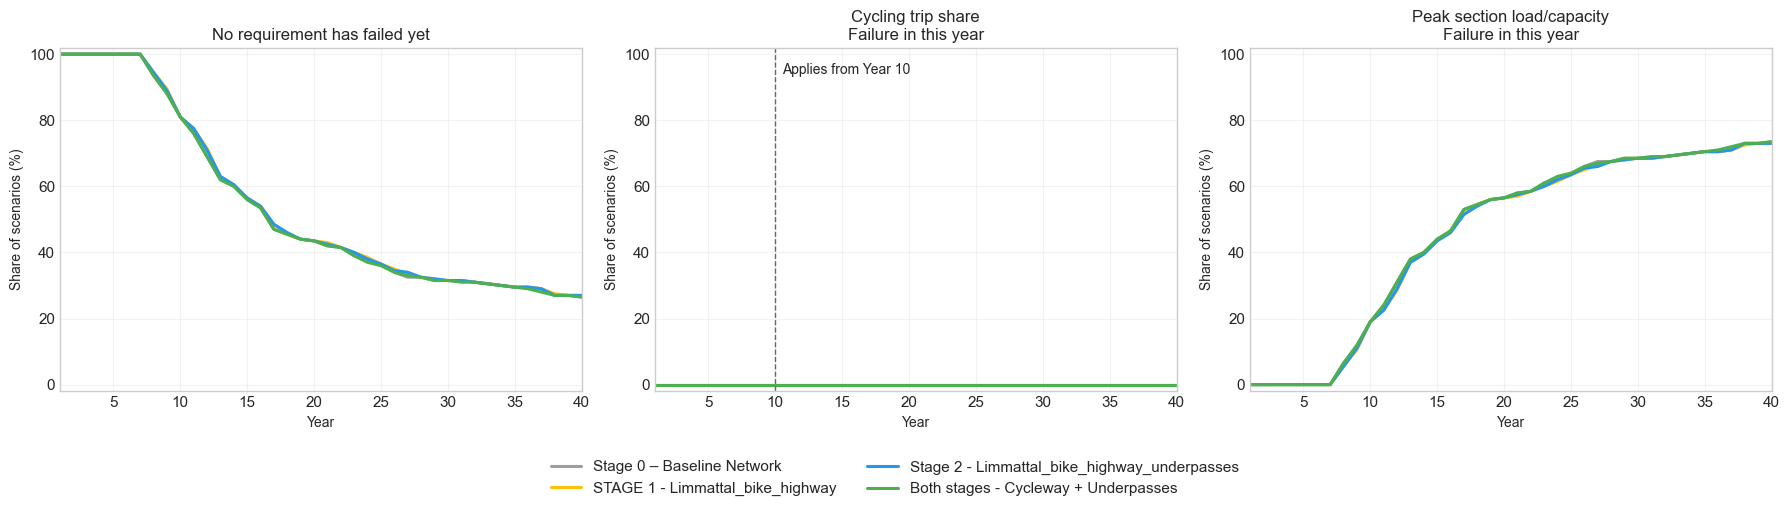

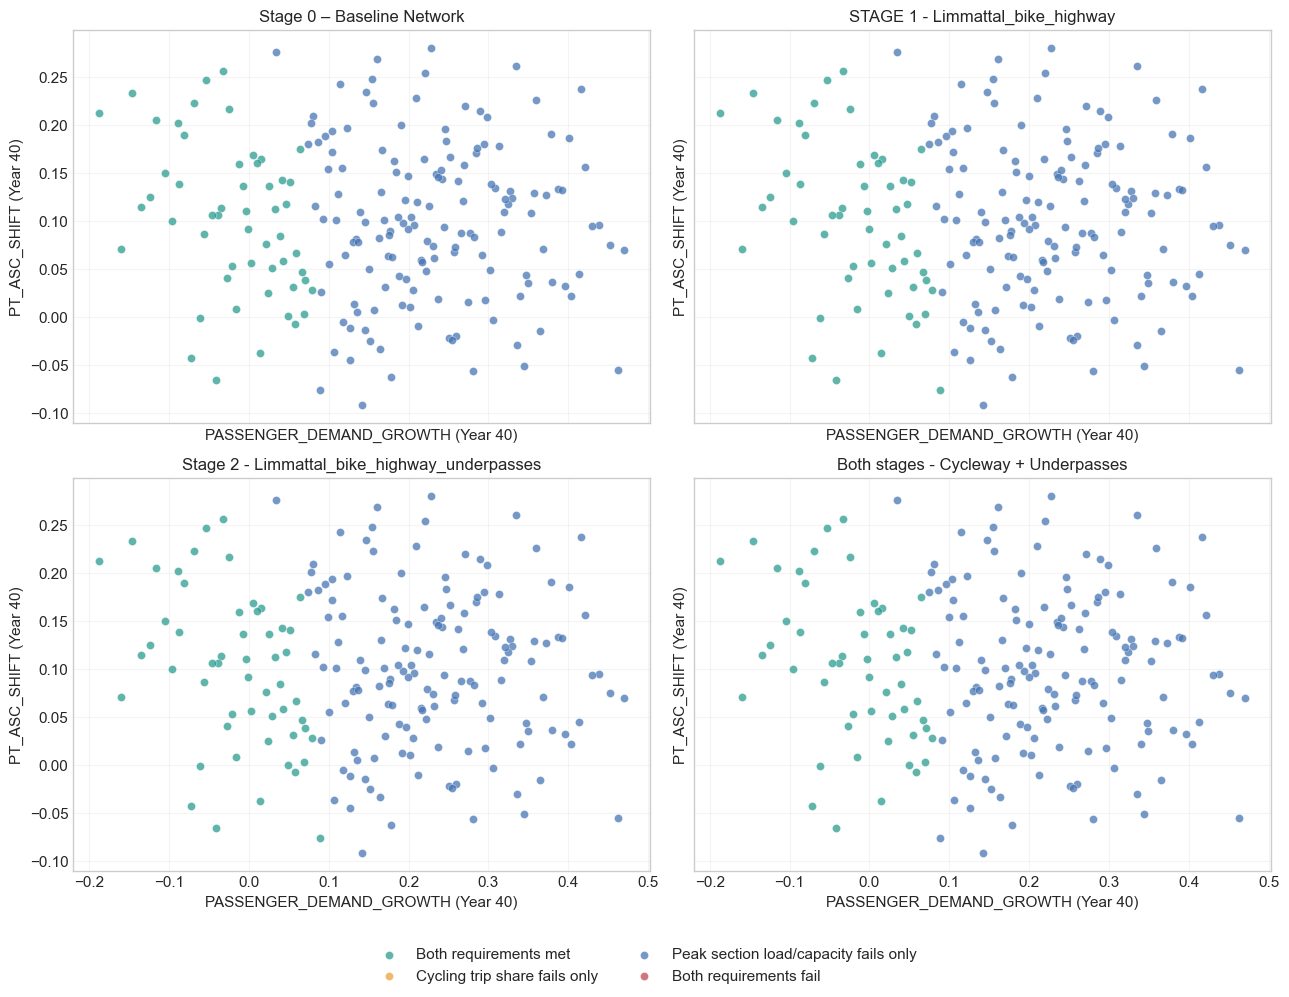

Requirement 1: Cycling trip share > 7.5 % (Years 10–40)
Requirement 2: Peak section load/capacity < 1.1 ratio (Years 1–40)


In [21]:
FAILURE_PLOT_INPUTS = [name for name in TRANSIENT_NAMES if name in TRANSPORT_NAMES][:2]

STAGE_TIP_COLORS = dict(CASE_STAGE_COLORS)
years = np.arange(1, N_YEARS + 1)
failure_by_year = requirement_history.groupby(["stage", "requirement", "year"])["failed"].mean().mul(100)
survival_table = pd.DataFrame({"year": years})
fig, axes = plt.subplots(1, 1 + len(PERFORMANCE_REQUIREMENTS),
                         figsize=(6 * (1 + len(PERFORMANCE_REQUIREMENTS)), 5), squeeze=False)
axes = axes[0]
for stage in CASE_STAGE_IDS:
    values = tipping_df[f"tipping_stage{stage}"]
    survival = [100 * (values.isna() | values.gt(year)).mean() for year in years]
    survival_table[STAGE_LABELS[stage]] = survival
    axes[0].plot(years, survival, color=STAGE_TIP_COLORS[stage], linewidth=2.2, label=STAGE_LABELS[stage])
    for index, rule in enumerate(PERFORMANCE_REQUIREMENTS):
        rates = failure_by_year.loc[(stage, index)].reindex(years)
        axes[index + 1].plot(years, rates, color=STAGE_TIP_COLORS[stage], linewidth=2.2)
axes[0].set(title="No requirement has failed yet", ylabel="Share of scenarios (%)")
for index, rule in enumerate(PERFORMANCE_REQUIREMENTS):
    ax = axes[index + 1]
    ax.set_title(indicator_label(rule["indicator"]) + "\nFailure in this year", fontsize=12)
    ax.set_ylabel("Share of scenarios (%)")
    start = rule.get("start_year", 1)
    if start > 1:
        ax.axvline(start, color="0.4", ls="--", lw=1)
        ax.text(start + .5, 94, f"Applies from Year {start}", fontsize=10)
for ax in axes:
    ax.set(xlabel="Year", ylim=(-2, 102), xlim=(1, N_YEARS))
    ax.tick_params(labelsize=11)
    ax.grid(alpha=.25)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(.5, -.03), ncol=2, fontsize=11)
fig.tight_layout(rect=(0, .10, 1, 1))
exports.save_outputs("04_2_requirement_failures", figure=fig, tables={
    "no_failure_yet_percent": survival_table,
    "annual_failure_percent": failure_by_year.rename("failure_percent").reset_index()})
plt.show()

# A physical-input view of the failure types for the selected drivers.
driver_names = [name for name in FAILURE_PLOT_INPUTS if name in SAMPLED_NAMES]
if len(driver_names) == 2 and len(PERFORMANCE_REQUIREMENTS) == 2:
    driver_table = physical_inputs(tipping_df)
    category_labels = ["Both requirements met",
        indicator_label(PERFORMANCE_REQUIREMENTS[0]["indicator"]) + " fails only",
        indicator_label(PERFORMANCE_REQUIREMENTS[1]["indicator"]) + " fails only",
        "Both requirements fail"]
    category_colors = ["#2a9d8f", "#e9a23b", "#4776b4", "#c44552"]
    fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)
    for ax, stage in zip(axes.flat, CASE_STAGE_IDS):
        category = (driver_table[f"requirement_0_failed_stage{stage}"].astype(int)
                    + 2 * driver_table[f"requirement_1_failed_stage{stage}"].astype(int))
        driver_table[f"failure_type_stage{stage}"] = category.map(dict(enumerate(category_labels)))
        for value, (label, color) in enumerate(zip(category_labels, category_colors)):
            points = driver_table.loc[category == value]
            ax.scatter(points[driver_names[0]], points[driver_names[1]], s=34, alpha=.75,
                       color=color, edgecolors="white", linewidths=.3, label=label)
        ax.set_title(STAGE_LABELS[stage], fontsize=12)
        ax.set_xlabel(driver_names[0] + " (Year 40)", fontsize=11)
        ax.set_ylabel(driver_names[1] + " (Year 40)", fontsize=11)
        ax.tick_params(labelsize=11)
        ax.grid(alpha=.2)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=11)
    fig.tight_layout(rect=(0, .07, 1, 1))
    exports.save_outputs("04_2_failure_drivers", figure=fig, tables={"scenarios": driver_table})
    plt.show()
    print("Requirement 1:", REQUIREMENT_LABELS[0])
    print("Requirement 2:", REQUIREMENT_LABELS[1])
else:
    print("The failure-type input plot uses two requirements and two sampled drivers in FAILURE_PLOT_INPUTS.")


**Interpret the configuration comparisons.**

Identify which requirement fails first and how long it fails. In the MehrSpur example, look for weak PT preference among scenarios missing the PT-share target and strong demand among scenarios exceeding the comfort threshold. Compare the same points across configurations: added attractiveness can raise passenger load, while added capacity can relieve it. An improvement in PT share alone does not establish that both objectives are met.

Initial shortfalls, a missed Year-20 deadline and later deterioration call for different interpretations. These technical targets do not establish whether an investment has positive net benefits; Notebook 05 evaluates that question.


## 4.4 Restoration windows and decision deadlines (mandatory task)

An operational opportunity occurs when the current infrastructure state fails an active requirement and adding a package would meet all active requirements in the same scenario and year. Compare each feasible independent package addition. Actual construction still requires its lead time.

A restoration window is a continuous period in which the current configuration fails a requirement and adding a package meets **all** active requirements. The figure shows actual sampled scenarios; the table covers every scenario and transition.

Subtract the construction lead time from the start or end of a window to obtain the decision deadlines for reaching those dates. A decision by the last deadline can provide some relief but it does not protect the whole window. The earliest possible rule-based decision assumes the required observations exceed the threshold from Year 1. Actual decisions can be later.

The final deadline concerns restoration of full requirements compliance. Transport benefits may remain after a restoration window closes.

Read the summary table by transition:

- `scenarios_with_window` and `with_window_percent`: scenarios in which that addition restores **all** active requirements for at least one year.
- `reachable_window_percent`: share of all scenarios with a window that could still be reached after the minimum monitoring period and construction time. This is a possibility, not a prediction that the actual trigger will fire.
- `mean_restorable_years`: mean number of years restored, including zero for scenarios with no window.
- `median_last_restoration_decision`: median last decision year among scenarios with a window. A value below Year 1 requires a pre-horizon commitment; a blank means no window was found.

The four panels use the same scenario IDs and row order. A blank opportunity is labelled “No restoration window”: it may mean the source already satisfies the requirements, or that the addition is insufficient. Green intervals show when opening would restore compliance; the blue interval is shifted earlier by construction time. Its left endpoint protects the start of the green interval, while its right endpoint reaches only the final restorable year.


In [22]:
OPPORTUNITY_TRANSITIONS = (
    (0, STATIONS_STATE, 1), (0, TUNNEL_STATE, 2),
    (STATIONS_STATE, COMBINED_STATE, 2), (TUNNEL_STATE, COMBINED_STATE, 1),
)


def contiguous_intervals(years, mask):
    """Return all continuous annual intervals selected by a Boolean mask."""
    selected = np.asarray(years, dtype=int)[np.asarray(mask, dtype=bool)]
    if not len(selected):
        return []
    blocks = np.split(selected, np.flatnonzero(np.diff(selected) != 1) + 1)
    return [(int(block[0]), int(block[-1])) for block in blocks]


window_columns = ["scenario", "source_state", "target_state", "package", "transition",
    "window_number", "opening_window_start", "opening_window_end", "restorable_years",
    "construction_years", "decision_by_window_start", "last_restoration_decision_year",
    "earliest_rule_decision_year", "earliest_rule_opening_year",
    "reachable_from_new_monitoring", "whole_window_reachable", "continues_to_horizon"]
window_rows, opportunity_rows = [], []
rules = notebook_triggers(NOTEBOOK_PARAMS)
for scenario in scenarios:
    for source, target, package in OPPORTUNITY_TRANSITIONS:
        before = stage_forever_results[(scenario["scenario"], source)]
        after = stage_forever_results[(scenario["scenario"], target)]
        restoring = ~performance_mask(before).to_numpy() & performance_mask(after).to_numpy()
        intervals = contiguous_intervals(before["year"], restoring)
        lead = ap.construction_lead_time(PLAN_SPECS["adaptive"], package, NOTEBOOK_PARAMS)
        earliest_decision = int(rules[f"trigger{package}"]["persistence"]) + 1
        earliest_opening = earliest_decision + lead
        transition = f"{STAGE_LABELS[source]} → {STAGE_LABELS[target]}"
        for number, (start, end) in enumerate(intervals, 1):
            window_rows.append({"scenario": scenario["scenario"], "source_state": source,
                "target_state": target, "package": package, "transition": transition,
                "window_number": number, "opening_window_start": start,
                "opening_window_end": end, "restorable_years": end - start + 1,
                "construction_years": lead, "decision_by_window_start": start - lead,
                "last_restoration_decision_year": end - lead,
                "earliest_rule_decision_year": earliest_decision,
                "earliest_rule_opening_year": earliest_opening,
                "reachable_from_new_monitoring": earliest_opening <= end,
                "whole_window_reachable": earliest_opening <= start,
                "continues_to_horizon": end == N_YEARS})
        opportunity_rows.append({"scenario": scenario["scenario"], "transition": transition,
            "source_state": source, "target_state": target, "package": package,
            "window_count": len(intervals), "restorable_years": int(restoring.sum()),
            "has_reachable_window": any(end >= earliest_opening for start, end in intervals),
            "all_windows_reachable": bool(intervals) and intervals[0][0] >= earliest_opening,
            "first_window_start": intervals[0][0] if intervals else np.nan,
            "last_window_end": intervals[-1][1] if intervals else np.nan,
            "last_restoration_decision_year": intervals[-1][1] - lead if intervals else np.nan})
restoration_windows = pd.DataFrame(window_rows, columns=window_columns)
opportunity_df = pd.DataFrame(opportunity_rows)
opportunity_summary = opportunity_df.groupby("transition", sort=False).agg(
    scenarios_with_window=("window_count", lambda s: int((s > 0).sum())),
    with_window_percent=("window_count", lambda s: 100 * (s > 0).mean()),
    reachable_window_percent=("has_reachable_window", lambda s: 100 * s.mean()),
    mean_restorable_years=("restorable_years", "mean"),
    median_last_restoration_decision=("last_restoration_decision_year", "median"))
show_table("04_4_restoration_summary", opportunity_summary.round(2))
exports.save_outputs("04_4_restoration_windows", tables={"intervals": restoration_windows,
    "scenarios": opportunity_df})


cell running: 00:00

,scenarios_with_window,with_window_percent,reachable_window_percent,mean_restorable_years,median_last_restoration_decision
transition,,,,,
Stage 0 – Baseline Network → STAGE 1 - Limmattal_bike_highway,32,16.0,16.0,0.16,13.5
Stage 0 – Baseline Network → Stage 2 - Limmattal_bike_highway_underpasses,28,14.0,14.0,0.14,12.5
STAGE 1 - Limmattal_bike_highway → Both stages - Cycleway + Underpasses,0,0.0,0.0,0.00,NaN
Stage 2 - Limmattal_bike_highway_underpasses → Both stages - Cycleway + Underpasses,0,0.0,0.0,0.00,NaN


{'table:intervals': PosixPath('/Users/liviagysel/Documents/ETHZ/REIS Master/Infrastructure Planning/IP-HS26-MehrSpur-CaseStudy/results/04_adaptive_planning/04_4_restoration_windows_intervals.csv'),
 'table:scenarios': PosixPath('/Users/liviagysel/Documents/ETHZ/REIS Master/Infrastructure Planning/IP-HS26-MehrSpur-CaseStudy/results/04_adaptive_planning/04_4_restoration_windows_scenarios.csv')}

cell running: 00:00

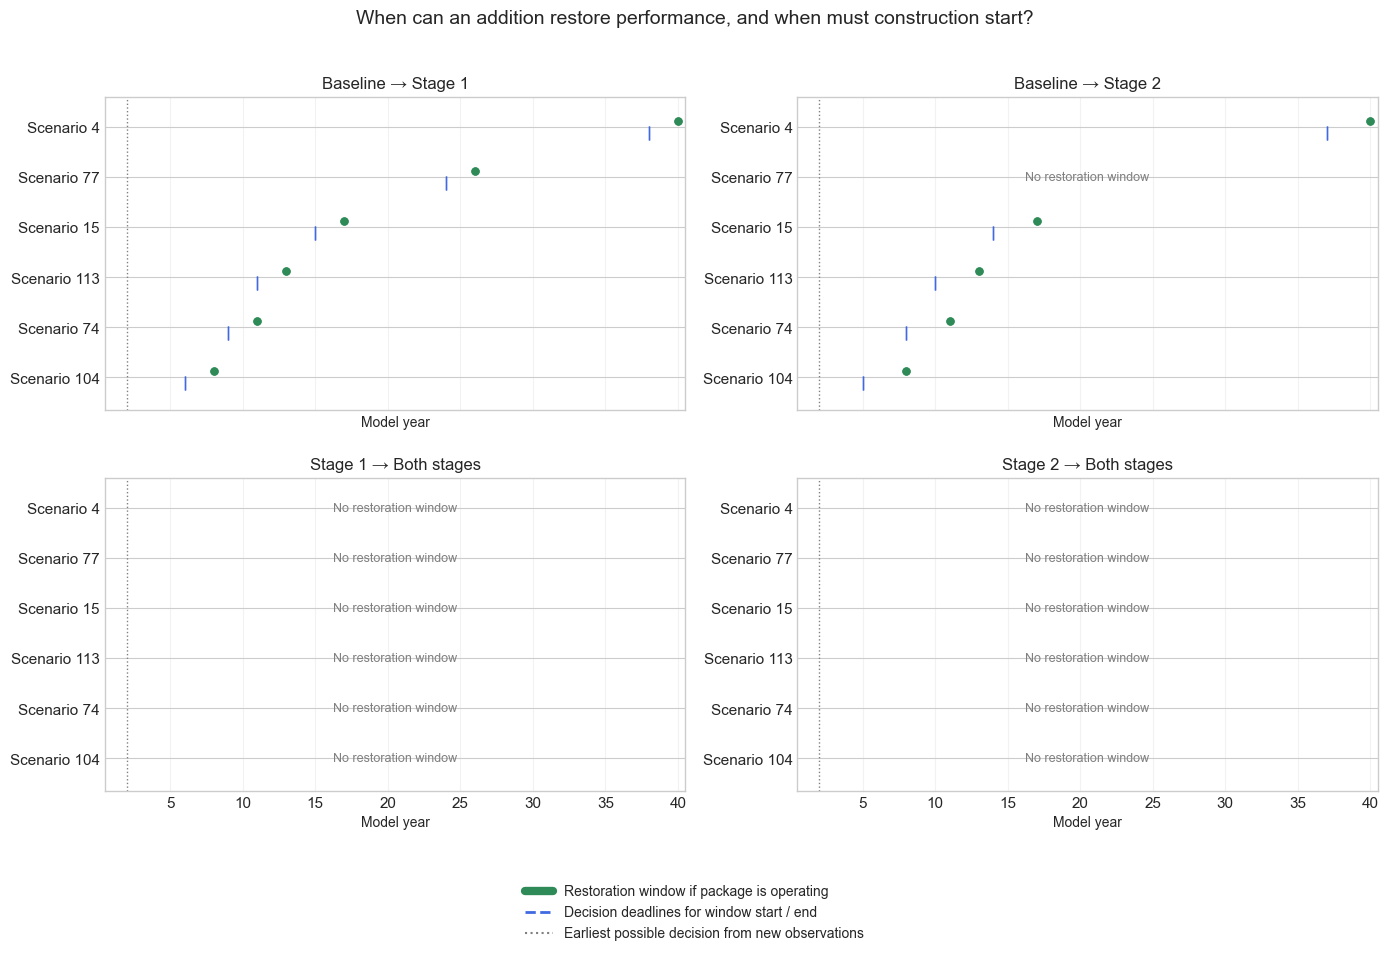

Deadlines before Year 1 require an earlier commitment. Windows ending at the horizon may continue beyond it; no later years are assessed.


In [23]:
# Select scenario IDs here; the same rows appear in every transition panel.
RESTORATION_EXAMPLE_IDS = None #None orders scenarios by their earliest restoration-window start across the transitions,
#then selects up to six evenly spaced positions in that ordering. To choose your own use a list such as [10, 40, 80, 120]
short_states = {0: "Baseline", STATIONS_STATE: "Stage 1", TUNNEL_STATE: "Stage 2", COMBINED_STATE: "Both stages"}
available_ids = [scenario["scenario"] for scenario in scenarios]
if RESTORATION_EXAMPLE_IDS is None:
    # Sample a common set across the range of first restoration dates.
    ordered = restoration_windows.groupby("scenario")["opening_window_start"].min().sort_values().index.tolist()
    if not ordered:
        ordered = available_ids
    chosen = [ordered[i] for i in np.unique(np.linspace(0, len(ordered) - 1, min(6, len(ordered)), dtype=int))] if ordered else []
else:
    chosen = list(dict.fromkeys(RESTORATION_EXAMPLE_IDS))
    unknown = set(chosen) - set(available_ids)
    if unknown:
        raise ValueError(f"Unknown RESTORATION_EXAMPLE_IDS: {sorted(unknown)}")
if not chosen:
    raise ValueError("Select at least one available scenario for the restoration figure.")
fig, axes = plt.subplots(2, 2, figsize=(14, max(7, 1.1 * len(chosen) + 3)), sharex=True, sharey=True)
shown_rows = []
for ax, (source, target, package) in zip(axes.flat, OPPORTUNITY_TRANSITIONS):
    subset = restoration_windows.loc[(restoration_windows["source_state"] == source)
                                    & (restoration_windows["target_state"] == target)]
    for row_number, sid in enumerate(chosen):
        scenario_windows = subset.loc[subset["scenario"] == sid]
        if scenario_windows.empty:
            ax.text((N_YEARS + 1) / 2, row_number, "No restoration window", ha="center", va="center",
                    fontsize=9, color="0.5")
        for _, window in scenario_windows.iterrows():
            start, end = window["opening_window_start"], window["opening_window_end"]
            ax.plot([start, end], [row_number + .12] * 2, color="seagreen", lw=7,
                    solid_capstyle="round", marker="o", markersize=5)
            dstart, dend = window["decision_by_window_start"], window["last_restoration_decision_year"]
            if dend >= 1:
                ax.plot([max(1, dstart), dend], [row_number - .12] * 2,
                        color="royalblue", lw=2, linestyle="--", marker="|", markersize=10)
            shown_rows.append(window.to_dict())
    earliest = int(rules[f"trigger{package}"]["persistence"]) + 1
    ax.axvline(earliest, color="grey", ls=":", lw=1)
    ax.set_yticks(range(len(chosen)), [f"Scenario {sid}" for sid in chosen])
    ax.set_ylim(-.65, len(chosen) - .4)
    ax.tick_params(axis="y", labelleft=True)
    ax.set(title=f"{short_states[source]} → {short_states[target]}", xlabel="Model year",
           xlim=(.5, N_YEARS + .5))
    ax.grid(axis="x", alpha=.25)
    ax.tick_params(labelsize=11)
fig.legend(handles=[Line2D([0], [0], color="seagreen", lw=6, label="Restoration window if package is operating"),
                    Line2D([0], [0], color="royalblue", lw=2, ls="--", label="Decision deadlines for window start / end"),
                    Line2D([0], [0], color="grey", ls=":", label="Earliest possible decision from new observations")],
           loc="lower center", ncol=1, fontsize=10)
fig.suptitle("When can an addition restore performance, and when must construction start?", fontsize=14)
fig.tight_layout(rect=(0, .11, 1, .96), h_pad=2)
exports.save_outputs("04_4_restoration_windows", figure=fig,
                     tables={"shown_examples": pd.DataFrame(shown_rows)})
plt.show()
print("Deadlines before Year 1 require an earlier commitment. Windows ending at the horizon may continue beyond it; no later years are assessed.")


## 4.5 Discover vulnerability mechanisms with PRIM (advanced task)

A scenario fails a requirement if it breaches that requirement in at least one active year. This is the same annual test used in the robustness comparison. Failure duration counts the breached years; a PT policy shortfall and a comfort failure are analysed separately.

PRIM searches `PRIM_INPUTS` for combinations associated with each failure, separately for Baseline and Adaptive. A box must reach `PRIM_DENSITY_THRESHOLD` and restrict at least one input. At least 15 failed and 15 successful scenarios are required for a search. Inputs and bounds are shown as physical Year-40 values.


In [24]:
PRIM_INPUTS = SAMPLED_NAMES.copy()
PRIM_PLOT_INPUTS = PRIM_INPUTS[:2]
PRIM_DENSITY_THRESHOLD = 0.75

from ema_workbench.analysis import prim

MIN_CASES_PER_CLASS_FOR_PRIM = 15
if not isinstance(PRIM_INPUTS, list) or any(name not in SAMPLED_NAMES for name in PRIM_INPUTS):
    raise ValueError("PRIM_INPUTS must be a list of selected scenario uncertainty names.")
if len(set(PRIM_INPUTS)) != len(PRIM_INPUTS):
    raise ValueError("PRIM_INPUTS must not contain duplicates.")
if not 0 < PRIM_DENSITY_THRESHOLD <= 1:
    raise ValueError("PRIM_DENSITY_THRESHOLD must be between zero (excluded) and one.")

annual_tests = requirement_results(trajectories_df)
requirement_vulnerability_df = requirement_outcomes(trajectories_df)
requirement_descriptions = {}
for requirement, rule in zip(annual_tests.columns, PERFORMANCE_REQUIREMENTS):
    key = rule["indicator"]
    start, end = rule.get("start_year", 1), rule.get("end_year", N_YEARS)
    requirement_descriptions[requirement] = (
        f"{indicator_label(key)} {rule['operator']} "
        f"{rule['threshold'] * indicator_scale(key):g} {indicator_unit(key)}; years {start}–{end}")
requirement_vulnerability_summary = requirement_vulnerability_df.groupby(["requirement", "plan"]).agg(
    scenarios=("scenario", "size"), failures=("ever_failure", "sum"),
    failure_percent=("ever_failure", lambda values: 100 * values.mean()),
    mean_failure_years=("failure_years", "mean"),
    median_failure_years=("failure_years", "median"),
    p90_failure_years=("failure_years", lambda values: values.quantile(.9)))
show_table("04_requirement_vulnerability", requirement_vulnerability_summary)

# Each scenario's physical endpoint inputs are shared by all plans and requirements.
physical_scenarios = physical_inputs(summary_df[["scenario", "plan", *SAMPLED_NAMES]])
vulnerability_inputs = requirement_vulnerability_df.merge(
    physical_scenarios, on=["scenario", "plan"], how="left", validate="many_to_one")
if vulnerability_inputs[SAMPLED_NAMES].isna().any().any():
    raise ValueError("Every requirement outcome needs its matching scenario inputs.")
exports.save_outputs("04_requirement_failure_scenarios", tables={"": vulnerability_inputs})

def qualifying_requirement_box(box):
    return bool(box is not None and np.isfinite(box.density)
                and box.density >= PRIM_DENSITY_THRESHOLD and box.res_dim > 0)

def physical_box_bounds(box):
    bounds = box.box_lim.copy().T
    bounds.columns = ["Year-40 lower", "Year-40 upper"]
    return bounds.rename_axis("parameter")

prim_results = {}
prim_status_rows = []
for requirement_index, requirement in enumerate(annual_tests.columns, start=1):
    for plan_name in ["baseline", "adaptive"]:
        subset = vulnerability_inputs.loc[
            (vulnerability_inputs["plan"] == plan_name)
            & (vulnerability_inputs["requirement"] == requirement)].reset_index(drop=True)
        varying = [name for name in PRIM_INPUTS if subset[name].nunique() > 1]
        y = subset["ever_failure"].to_numpy(dtype=bool)
        failures, successes = int(y.sum()), int((~y).sum())
        box = None
        accepted = False
        if not len(subset):
            status = "No scenarios for this plan"
        elif not failures:
            status = "No requirement failures"
        elif not successes:
            status = "All scenarios fail this requirement"
        elif not varying:
            status = "No varying selected inputs"
        elif min(failures, successes) < MIN_CASES_PER_CLASS_FOR_PRIM:
            status = f"Too few cases: need {MIN_CASES_PER_CLASS_FOR_PRIM} per class"
        else:
            algorithm = prim.Prim(subset[varying], y, threshold=PRIM_DENSITY_THRESHOLD, peel_alpha=.1)
            box = algorithm.find_box()
            accepted = qualifying_requirement_box(box)
            status = "Qualifying box" if accepted else "No qualifying box at the selected density"
            if box is not None:
                exports.save_outputs(f"04_prim_requirement_{requirement_index}_{plan_name}",
                                     tables={"peeling": box.peeling_trajectory})
            if accepted:
                show_table(f"04_prim_requirement_{requirement_index}_{plan_name}_bounds",
                           physical_box_bounds(box))
        prim_results[(requirement, plan_name)] = {
            "box": box, "accepted": accepted, "status": status, "subset": subset}
        prim_status_rows.append({
            "requirement": requirement, "plan": plan_name, "scenarios": len(y),
            "failures": failures, "failure_percent": 100 * y.mean() if len(y) else np.nan,
            "status": status, "accepted": accepted,
            "density": box.density if accepted else np.nan,
            "coverage": box.coverage if accepted else np.nan,
            "density_threshold": PRIM_DENSITY_THRESHOLD})
        print(f"{requirement} | {plan_name}: {failures}/{len(y)} scenarios fail. {status}.")

show_table("04_prim_status", pd.DataFrame(prim_status_rows).set_index(["requirement", "plan"]))


cell running: 00:00

scenarios  failures  failure_percent  \
requirement                 plan                                             
1: bike_share_trips > 0.075 adaptive        200         0              0.0   
                            baseline        200         0              0.0   
                            staged1         200         0              0.0   
                            staged2         200         0              0.0   
                            static1         200         0              0.0   
                            static2         200         0              0.0   
2: section_load_ratio < 1.1 adaptive        200       147             73.5   
                            baseline        200       147             73.5   
                            staged1         200       147             73.5   
                            staged2         200       147             73.5   
                            static1         200       146             73.0   
                            static2         200       147             73.5   

                                      mean_failure_years  \
requirement                 plan                           
1: bike_share_trips > 0.075 adaptive               0.000   
                            baseline               0.000   
                            staged1                0.000   
                            staged2                0.000   
                            static1                0.000   
                            static2                0.000   
2: section_load_ratio < 1.1 adaptive              18.335   
                            baseline              18.300   
                            staged1               18.310   
                            staged2               18.230   
                            static1               18.140   
                            static2               18.335   

                                      median_failure_years  p90_failure_years  
requirement                 plan                                               
1: bike_share_trips > 0.075 adaptive                   0.0                0.0  
                            baseline                   0.0                0.0  
                            staged1                    0.0                0.0  
                            staged2                    0.0                0.0  
                            static1                    0.0                0.0  
                            static2                    0.0                0.0  
2: section_load_ratio < 1.1 adaptive                  24.0               32.0  
                            baseline                  24.0               32.0  
                            staged1                   24.0               32.0  
                            staged2                   24.0               32.0  
                            static1                   24.0               32.0  
                            static2                   24.0               32.0

1: bike_share_trips > 0.075 | baseline: 0/200 scenarios fail. No requirement failures.
1: bike_share_trips > 0.075 | adaptive: 0/200 scenarios fail. No requirement failures.


,Year-40 lower,Year-40 upper
parameter,,
PASSENGER_DEMAND_GROWTH,0.113305,0.469351
PT_ASC_SHIFT,-0.091924,0.280122
BIKE_ASC_SHIFT,-0.448453,0.923404
EBIKE_SHARE,0.357682,0.775839
ROAD_FREIGHT_GROWTH,-0.054512,0.253983
CAR_CO2_KG_PER_VEHICLE_KM,0.030016,0.069735
OPEX_MULTIPLIER,0.502281,1.495298
CAPEX_MULTIPLIER,0.818101,1.188544
ACCIDENT_COST_MULTIPLIER,0.442704,1.186718


2: section_load_ratio < 1.1 | baseline: 147/200 scenarios fail. Qualifying box.


,Year-40 lower,Year-40 upper
parameter,,
PASSENGER_DEMAND_GROWTH,0.113305,0.469351
PT_ASC_SHIFT,-0.091924,0.280122
BIKE_ASC_SHIFT,-0.448453,0.923404
EBIKE_SHARE,0.357682,0.775839
ROAD_FREIGHT_GROWTH,-0.054512,0.253983
CAR_CO2_KG_PER_VEHICLE_KM,0.030016,0.069735
OPEX_MULTIPLIER,0.502281,1.495298
CAPEX_MULTIPLIER,0.818101,1.188544
ACCIDENT_COST_MULTIPLIER,0.442704,1.186718


2: section_load_ratio < 1.1 | adaptive: 147/200 scenarios fail. Qualifying box.


scenarios  failures  failure_percent  \
requirement                 plan                                             
1: bike_share_trips > 0.075 baseline        200         0              0.0   
                            adaptive        200         0              0.0   
2: section_load_ratio < 1.1 baseline        200       147             73.5   
                            adaptive        200       147             73.5   

                                                       status  accepted  \
requirement                 plan                                          
1: bike_share_trips > 0.075 baseline  No requirement failures     False   
                            adaptive  No requirement failures     False   
2: section_load_ratio < 1.1 baseline           Qualifying box      True   
                            adaptive           Qualifying box      True   

                                      density  coverage  density_threshold  
requirement                 plan                                            
1: bike_share_trips > 0.075 baseline      NaN       NaN               0.75  
                            adaptive      NaN       NaN               0.75  
2: section_load_ratio < 1.1 baseline      1.0  0.884354               0.75  
                            adaptive      1.0  0.884354               0.75

## 4.6 Visual comparison of vulnerability boxes (advanced task)

Each row shows one requirement; columns compare Baseline and Adaptive over the same scenarios. Choose two inputs in `PRIM_PLOT_INPUTS`. When Adaptive has no qualifying box, a qualifying Baseline box is shown as a labelled reference, with density and coverage recalculated for Adaptive. This reference is not a successful Adaptive discovery.

The rectangle is a projection: restrictions on other inputs remain in the exported bounds table. A small or missing box does not imply that the plan has no vulnerabilities.


cell running: 00:00

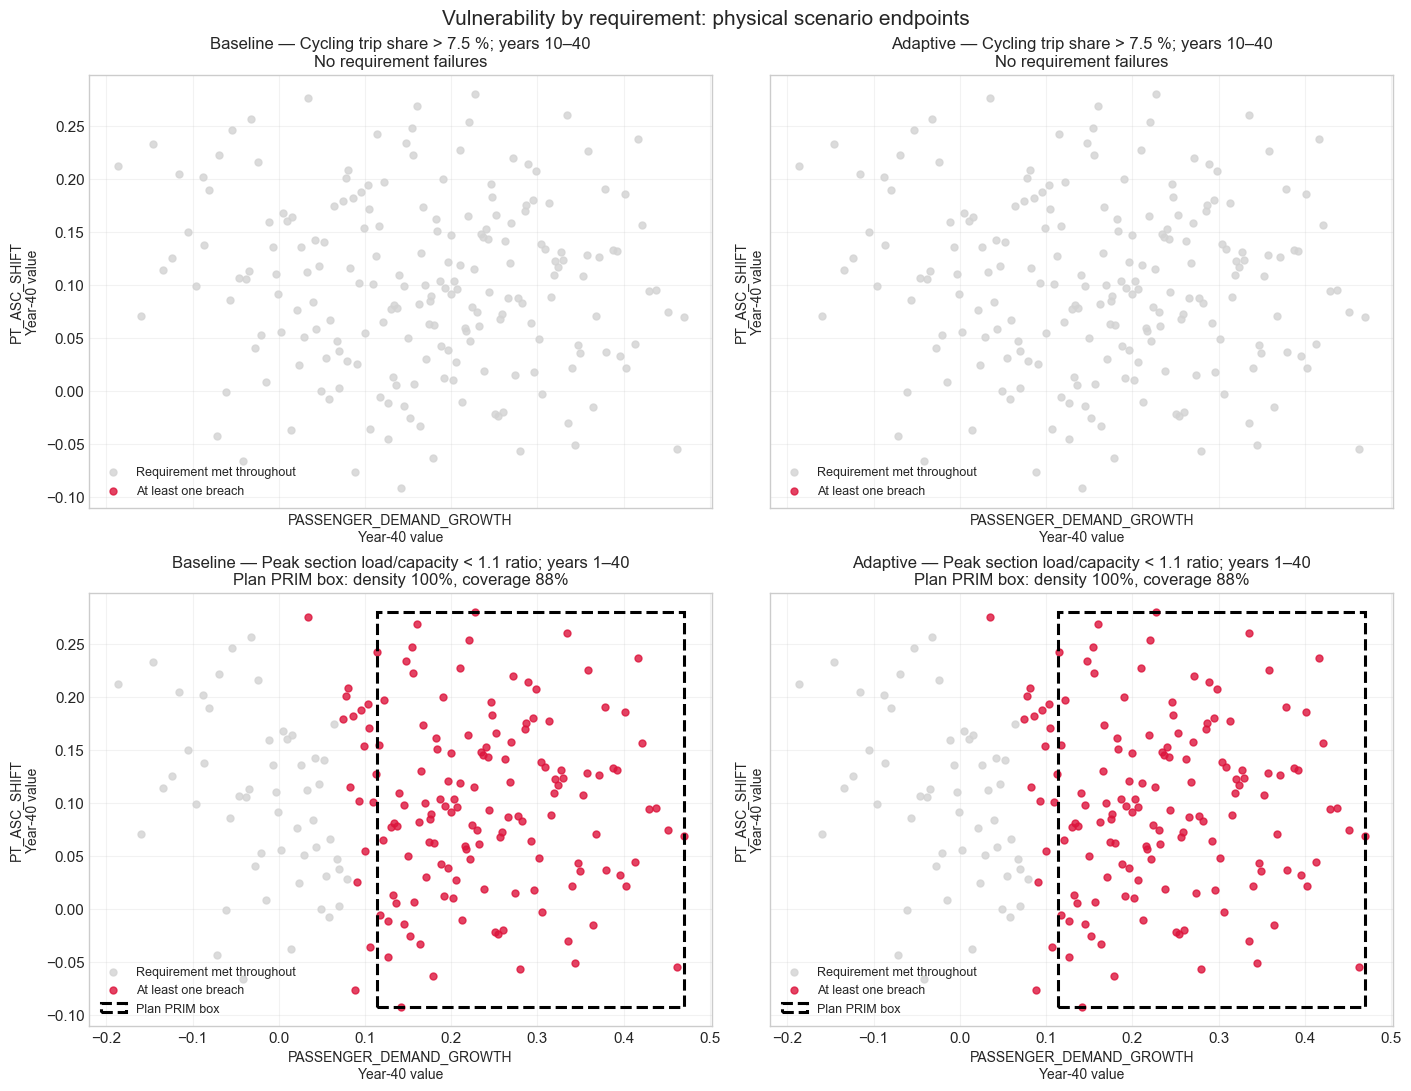

In [25]:
from matplotlib.patches import Rectangle
from textwrap import fill

if (not isinstance(PRIM_PLOT_INPUTS, list) or len(PRIM_PLOT_INPUTS) > 2
        or len(set(PRIM_PLOT_INPUTS)) != len(PRIM_PLOT_INPUTS)
        or any(name not in PRIM_INPUTS for name in PRIM_PLOT_INPUTS)):
    raise ValueError("PRIM_PLOT_INPUTS must contain up to two distinct names from PRIM_INPUTS.")

if len(PRIM_PLOT_INPUTS) != 2:
    print("Choose two selected inputs in PRIM_PLOT_INPUTS to show vulnerability projections.")
else:
    x_name, y_name = PRIM_PLOT_INPUTS
    requirements = list(annual_tests.columns)
    fig, axes = plt.subplots(len(requirements), 2, figsize=(14, 5.4 * len(requirements)),
                             squeeze=False, sharex=True, sharey=True, layout="constrained")
    shown_rows = []
    for row, requirement in enumerate(requirements):
        reference = prim_results[(requirement, "baseline")]
        for ax, plan_name in zip(axes[row], ["baseline", "adaptive"]):
            result = prim_results[(requirement, plan_name)]
            subset = result["subset"]
            for failed, color, label in [(False, "lightgray", "Requirement met throughout"),
                                         (True, "crimson", "At least one breach")]:
                points = subset.loc[subset["ever_failure"] == failed]
                ax.scatter(points[x_name], points[y_name], color=color, s=25, alpha=.8, label=label)
            shown_box = result["box"] if result["accepted"] else (
                reference["box"] if plan_name != "baseline" and reference["accepted"] else None)
            box_label = "Plan PRIM box" if result["accepted"] else "Baseline reference box"
            subtitle = result["status"]
            density = coverage = np.nan
            if shown_box is not None:
                inside = np.ones(len(subset), dtype=bool)
                for name in shown_box.box_lim.columns:
                    lower, upper = shown_box.box_lim[name]
                    inside &= subset[name].between(lower, upper).to_numpy()
                failed_inside = int(subset.loc[inside, "ever_failure"].sum())
                total_failures = int(subset["ever_failure"].sum())
                density = failed_inside / inside.sum() if inside.any() else np.nan
                coverage = failed_inside / total_failures if total_failures else np.nan
                projected_bounds = {}
                for name in PRIM_PLOT_INPUTS:
                    projected_bounds[name] = (shown_box.box_lim[name].to_numpy() if name in shown_box.box_lim
                                              else subset[name].agg(["min", "max"]).to_numpy())
                (x0, x1), (y0, y1) = projected_bounds[x_name], projected_bounds[y_name]
                ax.add_patch(Rectangle((x0, y0), x1-x0, y1-y0, fill=False, edgecolor="black",
                                       linewidth=2.2, linestyle="--", label=box_label, zorder=5))
                density_label = f"{density:.0%}" if np.isfinite(density) else "n/a"
                coverage_label = f"{coverage:.0%}" if np.isfinite(coverage) else "n/a"
                subtitle = f"{box_label}: density {density_label}, coverage {coverage_label}"
                if not result["accepted"]:
                    subtitle = "No qualifying plan box; " + subtitle
            shown_rows.append({"requirement": requirement, "plan": plan_name,
                               "box_source": plan_name if result["accepted"] else (
                                   "baseline" if shown_box is not None else "none"),
                               "density_in_plan": density, "coverage_in_plan": coverage})
            ax.set(title=(f"{plan_name.capitalize()} — "
                          f"{fill(requirement_descriptions[requirement], 55)}\n{fill(subtitle, 65)}"),
                   xlabel=f"{x_name}\nYear-40 value", ylabel=f"{y_name}\nYear-40 value")
            ax.legend(fontsize=9, loc="best")
            ax.tick_params(labelsize=11)
            ax.grid(alpha=.25)
    fig.suptitle("Vulnerability by requirement: physical scenario endpoints", fontsize=15)
    exports.save_outputs("04_prim_comparison", figure=fig,
                         tables={"shown_boxes": pd.DataFrame(shown_rows)})
    plt.show()


### Reading the scenario-discovery result

1. Compare each requirement's failure frequency and duration with the robustness results. The same annual tests are used in both sections.
2. Inspect density, coverage and all restricted input bounds. PRIM is a greedy search: no qualifying box does not demonstrate the absence of a high-failure region.
3. Compare the two mechanisms. Strong demand can exceed capacity; weak PT attractiveness can miss the modal-share objective. The same scenario may breach both.
4. Distinguish a missed policy deadline from an emerging capacity problem when considering a response. A high-passenger-count trigger will not necessarily protect a minimum-share objective.

Uniform success or failure cannot identify a smaller discriminating region. Too few cases or a low-density box also limits the result. Early failure years can reflect an existing shortfall or construction lead time; distinguish those cases from failures that emerge later.


# Part 5 — Evaluate and improve implementation
<a id="improve-implementation"></a>

## 5.1 Decisions, construction, openings and non-implementation (mandatory task)

A trigger leads to a decision but the construction lead time determines the opening. Compare both packages, distinguishing no decision from a committed package whose opening lies beyond the horizon. These probabilities describe implementation, not whether the plan meets its performance requirements.


In [26]:
IMPLEMENTATION_PACKAGES = {
    1: {"label": "Stage 1", "state": STATIONS_STATE},
    2: {"label": "Stage 2", "state": TUNNEL_STATE},
}
adaptive_summary = summary_df.loc[summary_df["plan"] == "adaptive"].copy()


def implementation_records(frame):
    """Keep absent dates missing and report the corresponding commitment status."""
    records = []
    for _, row in frame.iterrows():
        for package, spec in IMPLEMENTATION_PACKAGES.items():
            decision = float(row[f"decision{package}_year"])
            opening = float(row[f"stage{package}_activation_year"])
            scheduled = float(row[f"stage{package}_scheduled_opening_year"])
            decision = decision if decision > 0 else np.nan
            opening = opening if 0 < opening <= N_YEARS else np.nan
            scheduled = scheduled if scheduled > 0 else np.nan
            status = ("Open within horizon" if np.isfinite(opening) else
                      "Committed; opening after horizon" if np.isfinite(decision) and scheduled > N_YEARS else
                      "Committed; no opening recorded" if np.isfinite(decision) else "No decision")
            records.append({"scenario": row["scenario"], "package": package,
                            "package_label": spec["label"], "decision_year": decision,
                            "scheduled_opening_year": scheduled, "opening_year": opening,
                            "status": status})
    return pd.DataFrame(records)


implementation_df = implementation_records(adaptive_summary)
implementation_statuses = ["Open within horizon", "Committed; opening after horizon",
                           "Committed; no opening recorded", "No decision"]
implementation_rows = []
for package, spec in IMPLEMENTATION_PACKAGES.items():
    sub = implementation_df.loc[implementation_df["package"] == package]
    implementation_rows.append({
        "package": spec["label"], "Decision made (%)": 100 * sub["decision_year"].notna().mean(),
        **{status + " (%)": 100 * sub["status"].eq(status).mean() for status in implementation_statuses},
    })
show_table("05_1_implementation_probabilities", pd.DataFrame(implementation_rows).set_index("package").round(1))
exports.save_outputs("05_1_implementation_records", tables={"": implementation_df})


cell running: 00:00

,Decision made (%),Open within horizon (%),Committed; opening after horizon (%),Committed; no opening recorded (%),No decision (%)
package,,,,,
Stage 1,100.0,100.0,0.0,0.0,0.0
Stage 2,100.0,100.0,0.0,0.0,0.0


{'table:': PosixPath('/Users/liviagysel/Documents/ETHZ/REIS Master/Infrastructure Planning/IP-HS26-MehrSpur-CaseStudy/results/04_adaptive_planning/05_1_implementation_records.csv')}

### Opening dates and non-opening (tutorial/supporting task)

The left panel includes only packages that open within the horizon. The right panel includes all scenarios and shows the share without an opening by each year. A missing opening is not Year 0; Section 5.1 separates packages still under construction from packages never commissioned.


cell running: 00:00

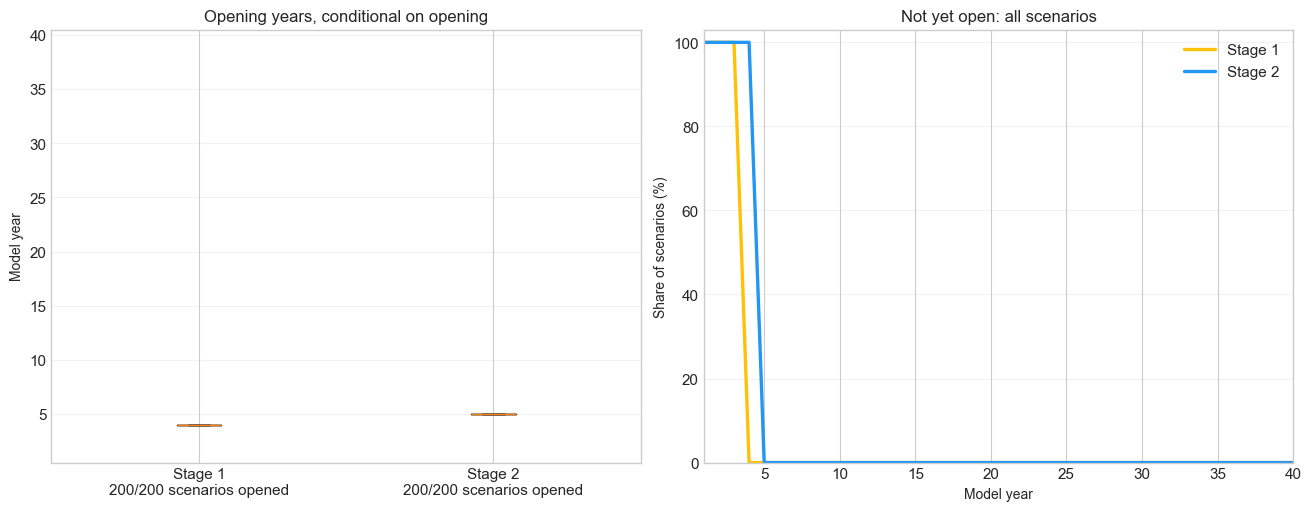

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
box_data, box_labels = [], []
for package, spec in IMPLEMENTATION_PACKAGES.items():
    sub = implementation_df.loc[implementation_df["package"] == package]
    opened = sub["opening_year"].dropna()
    if len(opened):
        box_data.append(opened.to_numpy())
        box_labels.append(f"{spec['label']}\n{len(opened)}/{len(sub)} scenarios opened")
    not_yet = [100 * (sub["opening_year"].isna() | sub["opening_year"].gt(year)).mean()
               for year in range(1, N_YEARS + 1)]
    axes[1].plot(range(1, N_YEARS + 1), not_yet, lw=2.4,
                 color=CASE_STAGE_COLORS[spec["state"]], label=spec["label"])
if box_data:
    axes[0].boxplot(box_data, tick_labels=box_labels)
else:
    axes[0].text(.5, .5, "Neither package opens in these scenarios", ha="center", va="center",
                 transform=axes[0].transAxes)
    axes[0].set_xticks([])
axes[0].set(title="Opening years, conditional on opening", ylabel="Model year", ylim=(.5, N_YEARS + .5))
axes[1].set(title="Not yet open: all scenarios", xlabel="Model year",
            ylabel="Share of scenarios (%)", xlim=(1, N_YEARS), ylim=(0, 103))
axes[1].legend(fontsize=11)
for ax in axes:
    ax.grid(axis="y", alpha=.25)
    ax.tick_params(labelsize=11)
exports.save_outputs("05_1_opening_distributions", figure=fig)
plt.show()


### Operating states and construction over time (tutorial/supporting task)

The left panel shows the infrastructure available to users. The right panel shows committed packages in their planning/construction lead time. Both packages can be under construction together; construction shares therefore need not add to 100%.


cell running: 00:00

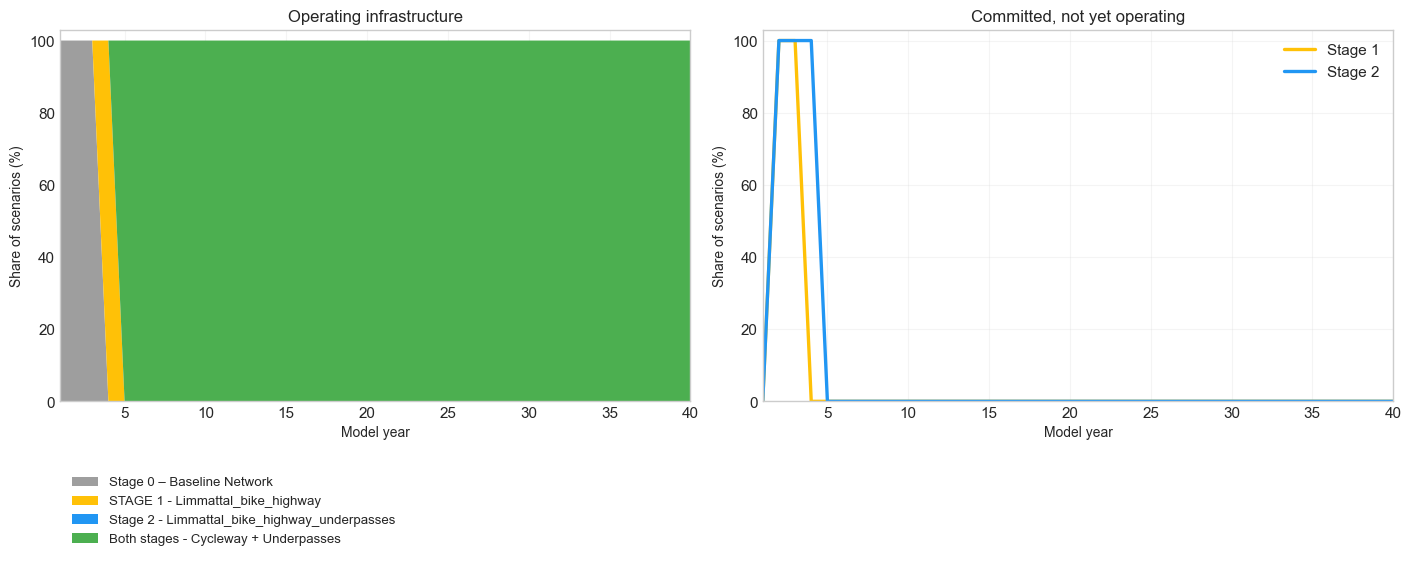

In [28]:
sub = trajectories_df.loc[trajectories_df["plan"] == "adaptive"]
occ = sub.groupby(["year", "stage"]).size().unstack(fill_value=0).reindex(columns=CASE_STAGE_IDS, fill_value=0)
occ_pct = occ.div(occ.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), layout="constrained")
axes[0].stackplot(occ_pct.index, [occ_pct[state] for state in CASE_STAGE_IDS],
                  colors=[CASE_STAGE_COLORS[state] for state in CASE_STAGE_IDS],
                  labels=[CASE_STAGE_LABELS[state] for state in CASE_STAGE_IDS])
axes[0].set(title="Operating infrastructure", xlabel="Model year", ylabel="Share of scenarios (%)")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -.17), fontsize=9.5, frameon=False)
construction_by_year = pd.DataFrame(index=range(1, N_YEARS + 1))
construction_by_year.index.name = "year"
for package, spec in IMPLEMENTATION_PACKAGES.items():
    sub = implementation_df.loc[implementation_df["package"] == package]
    construction_by_year[spec["label"]] = [
        100 * (sub["decision_year"].le(year) & sub["scheduled_opening_year"].gt(year)).mean()
        for year in construction_by_year.index
    ]
    axes[1].plot(construction_by_year.index, construction_by_year[spec["label"]], lw=2.4,
                 color=CASE_STAGE_COLORS[spec["state"]], label=spec["label"])
axes[1].set(title="Committed, not yet operating", xlabel="Model year", ylabel="Share of scenarios (%)")
axes[1].legend(fontsize=11)
for ax in axes:
    ax.set(xlim=(1, N_YEARS), ylim=(0, 103))
    ax.grid(alpha=.2)
    ax.tick_params(labelsize=11)
exports.save_outputs("05_1_operating_and_construction", figure=fig,
                     tables={"operating_percent": occ_pct, "construction_percent": construction_by_year})
plt.show()


## 5.2 Adaptive plan: no / early / medium / late opening (tutorial/supporting task)

The next sections compare opening dates, pathway performance and vulnerable scenarios. Decisions, scheduled openings and actual openings within the horizon are distinct events.

Group scenarios separately by Stage 1 and Stage 2's actual opening year. Set the cohort boundaries at the top of the block: the defaults are early opening by Year 15, medium opening in Years 16–25, and late opening after Year 25. Each row of panels uses that package's own monitoring indicator and opening cohorts. A scenario with no opening can still contain a decision whose construction finishes beyond the horizon.

Cohort curves are medians of different scenario groups. They describe those groups; they do not isolate the causal effect of opening earlier.


cell running: 00:00

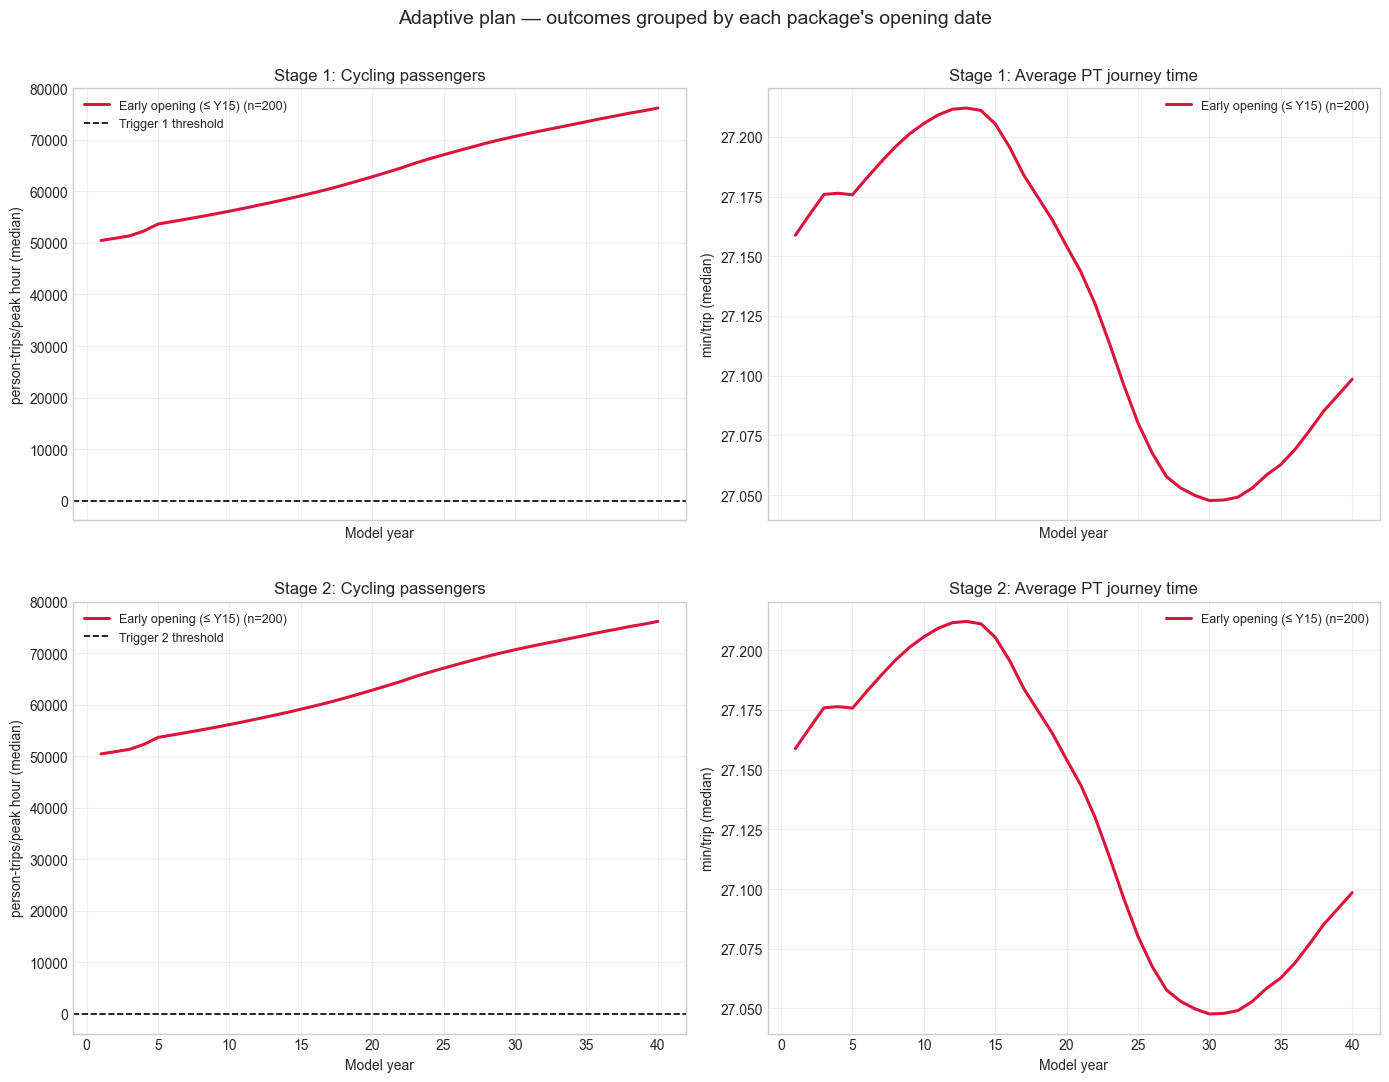

n  percent
package opening_cohort                        
Stage 1 No opening                  0      0.0
        Early opening (≤ Y15)     200    100.0
        Medium opening (Y16–Y25)    0      0.0
        Late opening (> Y25)        0      0.0
Stage 2 No opening                  0      0.0
        Early opening (≤ Y15)     200    100.0
        Medium opening (Y16–Y25)    0      0.0
        Late opening (> Y25)        0      0.0

In [29]:
# Set opening-year cohort boundaries and the downstream indicator for both packages.
EARLY_OPENING_END_YEAR = 15
MEDIUM_OPENING_END_YEAR = 25
TIMING_INDICATOR = "pt_journey_time_min"
if not (1 <= EARLY_OPENING_END_YEAR < MEDIUM_OPENING_END_YEAR < N_YEARS):
    raise ValueError("Opening-cohort boundaries must be ordered within the model horizon.")
if TIMING_INDICATOR not in INDICATOR_CATALOG or TIMING_INDICATOR not in trajectories_df:
    raise ValueError("Choose TIMING_INDICATOR from the available indicator catalogue.")
flex_df = summary_df.loc[summary_df["plan"] == "adaptive"].copy()
BUCKET_ORDER = [
    "No opening",
    f"Early opening (≤ Y{EARLY_OPENING_END_YEAR})",
    f"Medium opening (Y{EARLY_OPENING_END_YEAR + 1}–Y{MEDIUM_OPENING_END_YEAR})",
    f"Late opening (> Y{MEDIUM_OPENING_END_YEAR})",
]
BUCKET_COLORS = dict(zip(BUCKET_ORDER, ["grey", "crimson", "darkorange", "steelblue"]))


def opening_bucket(year):
    if pd.isna(year) or year <= 0:
        return BUCKET_ORDER[0]
    if year <= EARLY_OPENING_END_YEAR:
        return BUCKET_ORDER[1]
    if year <= MEDIUM_OPENING_END_YEAR:
        return BUCKET_ORDER[2]
    return BUCKET_ORDER[3]

fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharex=True)
bucket_rows = []
cohort_rows = []
rules = notebook_triggers(NOTEBOOK_PARAMS)
for row_number, package in enumerate((1, 2)):
    trigger = rules[f"trigger{package}"]
    monitor = trigger["monitoring_indicator"]
    bucket_key = f"stage{package}_opening_bucket"
    flex_df[bucket_key] = flex_df[f"stage{package}_activation_year"].map(opening_bucket)
    for bucket in BUCKET_ORDER:
        scenario_ids = flex_df.loc[flex_df[bucket_key] == bucket, "scenario"]
        bucket_rows.append({"package": f"Stage {package}", "opening_cohort": bucket,
                            "n": len(scenario_ids), "percent": 100 * len(scenario_ids) / len(flex_df)})
        if not len(scenario_ids):
            continue
        sub = trajectories_df.loc[(trajectories_df["plan"] == "adaptive")
                                  & trajectories_df["scenario"].isin(scenario_ids)]
        for column, key in enumerate((monitor, TIMING_INDICATOR)):
            median = sub.groupby("year")[key].median()
            axes[row_number, column].plot(median.index, median * indicator_scale(key),
                color=BUCKET_COLORS[bucket], linewidth=2.2, label=f"{bucket} (n={len(scenario_ids)})")
            cohort_rows.extend({"package": f"Stage {package}", "opening_cohort": bucket,
                                "year": int(year), "indicator": key, "median": value}
                               for year, value in median.items())
    axes[row_number, 0].axhline(trigger["threshold"] * indicator_scale(monitor), color="black",
        linestyle="--", linewidth=1.2, label=f"Trigger {package} threshold")
    for column, key in enumerate((monitor, TIMING_INDICATOR)):
        axes[row_number, column].set(xlabel="Model year", ylabel=indicator_unit(key) + " (median)",
            title=f"Stage {package}: {indicator_label(key)}")
        axes[row_number, column].legend(fontsize=9)
        axes[row_number, column].grid(alpha=.3)

fig.suptitle("Adaptive plan — outcomes grouped by each package's opening date", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, .97), h_pad=3)
bucket_summary = pd.DataFrame(bucket_rows).set_index(["package", "opening_cohort"])
exports.save_outputs("04_adaptive_trigger_buckets", figure=fig,
    tables={"median_trajectories": pd.DataFrame(cohort_rows), "counts": bucket_summary})
plt.show()
show_table("04_opening_buckets", bucket_summary.round(1))


## 5.4 Did each adaptive package open in time? (mandatory task)

Compare each package's opening with the first failure on a counterfactual pathway **without that package**. Keep the other package's observed opening date fixed. These are paired comparisons within the same scenario; the other package's trigger is not rerun.

$$\text{lead margin} = \text{first failure without the package} - \text{opening year}$$

A positive margin means opening preceded the first reference failure. It does not prove the package prevented it: the exported table also compares actual and counterfactual failure duration. Initial shortfalls are shown separately because they could not have been anticipated within this horizon. Failure at a later target deadline remains a failure in that deadline year. Scenarios without an opening or reference failure are separate categories, not year-zero observations.

The colour identifies the requirement causing the first failure. The decision deadline is the reference failure year minus construction time. Meeting that deadline is necessary to be operating at the first failure, but is not sufficient to meet every objective: check the restoration windows and the indicator trajectories. A deadline before the earliest possible monitoring-based decision requires an earlier commitment or another response.

Use the same scenario ID to inspect a fixed-state restoration window in Section 4.4. Here the other package retains its observed opening, so the comparison and deadlines can differ. The objective-protection figure shows the configured requirements for the adaptive plan, the baseline without either package, and the two package-removal counterfactuals.

Set `TIMELINESS_EXAMPLE_ID` at the top of the first code block to inspect a particular sampled scenario. `None` selects the scenario with the largest conditional reduction in failure years from either package.


In [30]:
# Set a sampled scenario ID to inspect, or None for the largest conditional reduction in failure years.
TIMELINESS_EXAMPLE_ID = 80  # Set None for automatic selection.

def classify_lead_margin(tipping_year, opening_year, initial_shortfall=False):
    if initial_shortfall:
        return "Initial shortfall; opens" if pd.notna(opening_year) else "Initial shortfall; not opened"
    if pd.isna(tipping_year) and pd.isna(opening_year):
        return "No reference failure or opening"
    if pd.isna(tipping_year):
        return "Opens without reference failure"
    if pd.isna(opening_year):
        return "Reference failure; not opened"
    return "Opens by first failure" if tipping_year >= opening_year else "Opens after first failure"


adaptive_lead = summary_df.loc[summary_df["plan"] == "adaptive"].copy()
adaptive_lead["activation1"] = adaptive_lead["stage1_activation_year"].where(adaptive_lead["stage1_activation_year"] > 0)
adaptive_lead["activation2"] = adaptive_lead["stage2_activation_year"].where(adaptive_lead["stage2_activation_year"] > 0)


def pathway_without(row, absent_package):
    other_package = 2 if absent_package == 1 else 1
    other_year = row["activation2" if absent_package == 1 else "activation1"]
    other_state = TUNNEL_STATE if absent_package == 1 else STATIONS_STATE
    baseline = stage_forever_results[(row["scenario"], 0)]
    other = stage_forever_results[(row["scenario"], other_state)]
    if pd.isna(other_year):
        result = baseline.copy()
    else:
        result = pd.concat([baseline.loc[baseline["year"] < other_year],
                            other.loc[other["year"] >= other_year]], ignore_index=True).sort_values("year").reset_index(drop=True)
    # Retain the other package's actual construction, including openings beyond Year 40.
    scheduled = row[f"stage{other_package}_scheduled_opening_year"]
    scheduled = 0 if pd.isna(scheduled) else int(scheduled)
    lead = ap.construction_lead_time(PLAN_SPECS["adaptive"], other_package, NOTEBOOK_PARAMS)
    result["construction_co2_tonnes"] = [sum(ap.construction_emissions_in_year(
        other_package, int(year), scheduled, lead)) for year in result["year"]]
    result["co2_tonnes"] = result["operating_co2_tonnes"] + result["construction_co2_tonnes"]
    return result


lead_rows = []
for _, row in adaptive_lead.iterrows():
    actual = trajectories_df.loc[(trajectories_df["scenario"] == row["scenario"])
                                 & (trajectories_df["plan"] == "adaptive")].sort_values("year")
    actual_status, _ = failure_summary(actual)
    for package, label in ((1, "Stage 1"), (2, "Stage 2")):
        counterfactual = pathway_without(row, package)
        status, checks = failure_summary(counterfactual)
        failure, opening = status["first_failure_year"], row[f"activation{package}"]
        cause = [] if pd.isna(failure) else [REQUIREMENT_LABELS[index]
            for index in range(len(PERFORMANCE_REQUIREMENTS))
            if not bool(checks.loc[counterfactual["year"] == failure].iloc[0, index])]
        lead_rows.append({**row.to_dict(), "package": label, "package_id": package, "opening_year": opening,
            "reference_failure_year": failure, "initial_shortfall": status["initial_shortfall"],
            "first_failure_requirements": "; ".join(cause),
            "failure_mechanism": (" + ".join(indicator_label(PERFORMANCE_REQUIREMENTS[index]["indicator"])
                for index in range(len(PERFORMANCE_REQUIREMENTS))
                if pd.notna(failure) and not bool(checks.loc[counterfactual["year"] == failure].iloc[0, index]))
                or "No reference failure"),
            "decision_year": row[f"decision{package}_year"] if row[f"decision{package}_year"] > 0 else np.nan,
            "construction_years": ap.construction_lead_time(PLAN_SPECS["adaptive"], package, NOTEBOOK_PARAMS),
            "decision_by_first_failure": failure - ap.construction_lead_time(PLAN_SPECS["adaptive"], package, NOTEBOOK_PARAMS),
            "timing_class": classify_lead_margin(failure, opening, status["initial_shortfall"]),
            "lead_margin_years": failure - opening if not status["initial_shortfall"] else np.nan,
            "reference_failure_years": status["failure_years"],
            "actual_failure_years": actual_status["failure_years"],
            "failure_years_avoided": status["failure_years"] - actual_status["failure_years"]})
lead_df = pd.DataFrame(lead_rows)
LEAD_CLASSES = ["Initial shortfall; opens", "Initial shortfall; not opened",
    "Opens by first failure", "Opens after first failure", "Reference failure; not opened",
    "Opens without reference failure", "No reference failure or opening"]
lead_summary = pd.crosstab(lead_df["timing_class"], lead_df["package"], normalize="columns").mul(100).reindex(LEAD_CLASSES, fill_value=0)
show_table("05_4_timing_classes", lead_summary.round(1))
show_table("05_4_failure_duration", lead_df.groupby("package")[[
    "reference_failure_years", "actual_failure_years", "failure_years_avoided"]].mean().round(2))
exports.save_outputs("05_4_timeliness_scenarios", tables={"": physical_inputs(lead_df)})

lead_df["deadline_before_monitoring_possible"] = [
    pd.notna(row["decision_by_first_failure"]) and row["decision_by_first_failure"] <
    int(notebook_triggers(NOTEBOOK_PARAMS)[f"trigger{int(row['package_id'])}"]["persistence"]) + 1
    for _, row in lead_df.iterrows()]
show_table("05_4_decision_deadlines", lead_df.groupby("package").agg(
    scenarios_with_failure=("reference_failure_year", "count"),
    deadline_before_monitoring_percent=("deadline_before_monitoring_possible", lambda s: 100 * s.mean()),
    median_decision_deadline=("decision_by_first_failure", "median")).round(2))
exports.save_outputs("05_4_timeliness_scenarios", tables={"": physical_inputs(lead_df)})


cell running: 00:00

package,Stage 1,Stage 2
timing_class,,
Initial shortfall; opens,0.0,0.0
Initial shortfall; not opened,0.0,0.0
Opens by first failure,73.0,73.0
Opens after first failure,0.0,0.0
Reference failure; not opened,0.0,0.0
Opens without reference failure,27.0,27.0
No reference failure or opening,0.0,0.0


,reference_failure_years,actual_failure_years,failure_years_avoided
package,,,
Stage 1,18.16,18.34,-0.18
Stage 2,18.14,18.34,-0.20


,scenarios_with_failure,deadline_before_monitoring_percent,median_decision_deadline
package,,,
Stage 1,146,0.0,11.0
Stage 2,146,0.0,10.0


{'table:': PosixPath('/Users/liviagysel/Documents/ETHZ/REIS Master/Infrastructure Planning/IP-HS26-MehrSpur-CaseStudy/results/04_adaptive_planning/05_4_timeliness_scenarios.csv')}

cell running: 00:00

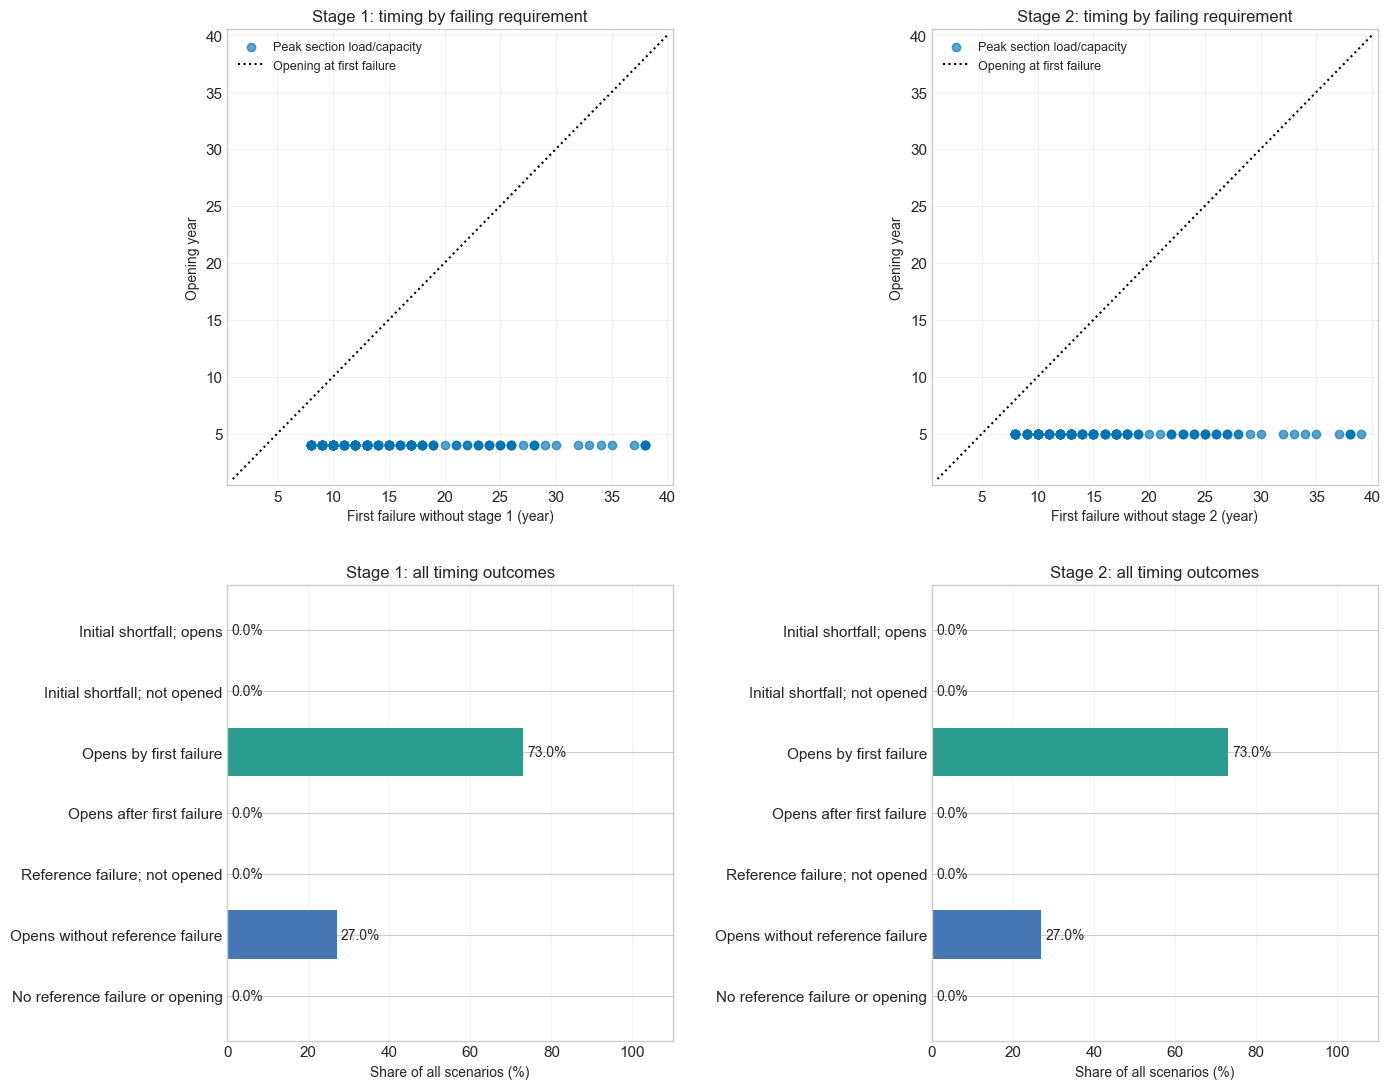

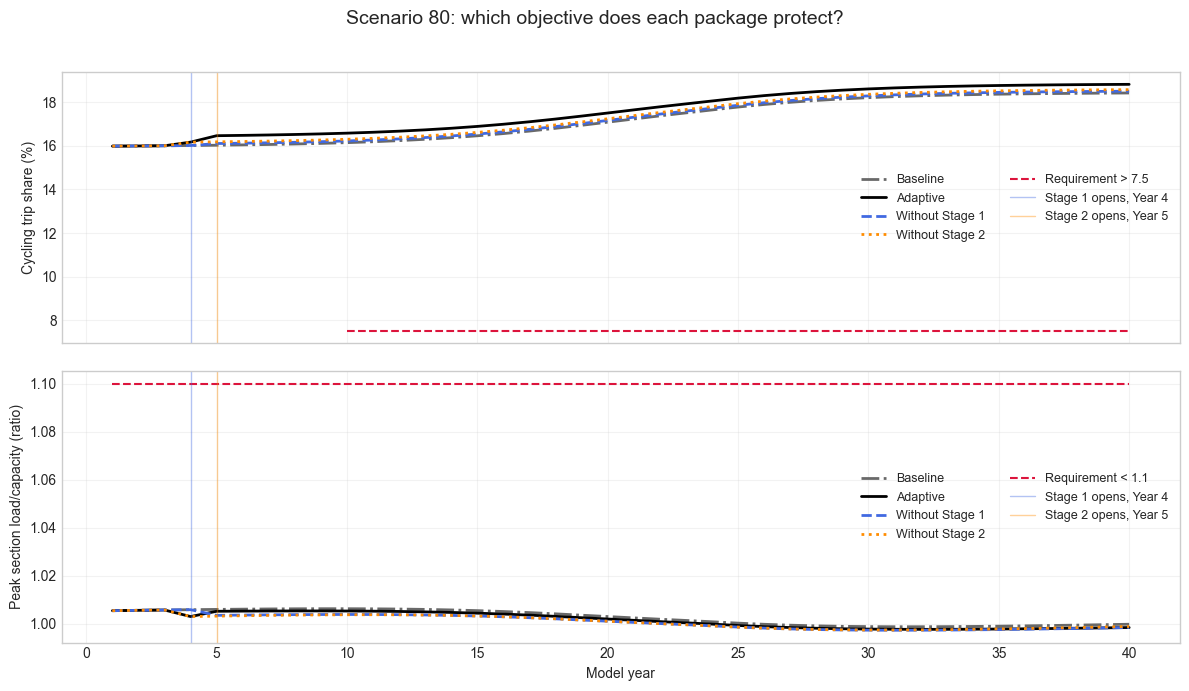

In [31]:
mechanisms = sorted(lead_df.loc[lead_df["reference_failure_year"].notna(), "failure_mechanism"].unique())
mechanism_colors = dict(zip(mechanisms, sns.color_palette("colorblind", max(1, len(mechanisms)))))
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
class_colors = ["#8c6bb1", "#bcbddc", "#2a9d8f", "#e9a23b", "#c44552", "#4776b4", "#b0b0b0"]
for column, package in enumerate(("Stage 1", "Stage 2")):
    selected = lead_df.loc[lead_df["package"] == package]
    valid = selected.loc[~selected["initial_shortfall"] & selected["reference_failure_year"].notna()
                         & selected["opening_year"].notna()]
    ax = axes[0, column]
    for mechanism in mechanisms:
        points = valid.loc[valid["failure_mechanism"] == mechanism]
        if len(points):
            ax.scatter(points["reference_failure_year"], points["opening_year"], alpha=.65,
                       s=36, color=mechanism_colors[mechanism], label=textwrap.fill(mechanism, 30))
    if not len(valid):
        ax.text(.5, .55, "No paired dates after excluding initial shortfalls", ha="center",
                va="center", wrap=True, transform=ax.transAxes)
    ax.plot([1, N_YEARS], [1, N_YEARS], "k:", label="Opening at first failure")
    ax.set(xlabel=f"First failure without {package.lower()} (year)", ylabel="Opening year",
           title=f"{package}: timing by failing requirement", xlim=(.5, N_YEARS + .5), ylim=(.5, N_YEARS + .5))
    ax.legend(fontsize=9, loc="best")
    ax.grid(alpha=.25)
    ax = axes[1, column]
    rates = lead_summary[package].reindex(LEAD_CLASSES, fill_value=0)
    bars = ax.barh(LEAD_CLASSES, rates, color=class_colors)
    ax.bar_label(bars, labels=[f"{value:.1f}%" for value in rates], padding=3, fontsize=10)
    ax.invert_yaxis()
    ax.set(xlabel="Share of all scenarios (%)", title=f"{package}: all timing outcomes", xlim=(0, 110))
    ax.grid(axis="x", alpha=.2)
for ax in axes.flat:
    ax.tick_params(labelsize=11)
    ax.title.set_fontsize(12)
fig.tight_layout(h_pad=3, w_pad=3)
exports.save_outputs("05_4_package_timeliness", figure=fig)
plt.show()

selected_scenario_id = TIMELINESS_EXAMPLE_ID
if selected_scenario_id is None:
    selected_scenario_id = lead_df.groupby("scenario")["failure_years_avoided"].max().idxmax()
example_row = adaptive_lead.loc[adaptive_lead["scenario"] == selected_scenario_id]
if example_row.empty:
    raise ValueError("TIMELINESS_EXAMPLE_ID must be one of the sampled scenario IDs.")
example_row = example_row.iloc[0]
actual = trajectories_df.loc[(trajectories_df["scenario"] == selected_scenario_id)
                             & (trajectories_df["plan"] == "adaptive")].sort_values("year")
baseline = stage_forever_results[(selected_scenario_id, 0)]
objective_keys = list(dict.fromkeys(rule["indicator"] for rule in PERFORMANCE_REQUIREMENTS))
fig, axes = plt.subplots(len(objective_keys), 1, figsize=(12, max(4, 3.5 * len(objective_keys))),
                         sharex=True, squeeze=False)
objective_frames = []
for name, frame, color, style in (("Baseline", baseline, "dimgray", "-."),
        ("Adaptive", actual, "black", "-"),
        ("Without Stage 1", pathway_without(example_row, 1), "royalblue", "--"),
        ("Without Stage 2", pathway_without(example_row, 2), "darkorange", ":")):
    objective_frames.append(frame[["year", *objective_keys]].assign(comparison=name,
        scenario=selected_scenario_id))
    for ax, key in zip(axes.flat, objective_keys):
        ax.plot(frame["year"], frame[key] * indicator_scale(key), color=color, linestyle=style,
                lw=2, label=name)
for ax, key in zip(axes.flat, objective_keys):
    for rule in PERFORMANCE_REQUIREMENTS:
        if rule["indicator"] == key:
            start, end = rule.get("start_year", 1), rule.get("end_year", N_YEARS)
            ax.plot([start, end], [rule["threshold"] * indicator_scale(key)] * 2,
                    color="crimson", ls="--", lw=1.5, label=f"Requirement {rule['operator']} {rule['threshold'] * indicator_scale(key):g}")
    for package, color in ((1, "royalblue"), (2, "darkorange")):
        opening = example_row[f"activation{package}"]
        if pd.notna(opening):
            ax.axvline(opening, color=color, alpha=.4, lw=1,
                       label=f"Stage {package} opens, Year {int(opening)}")
    ax.set(ylabel=f"{indicator_label(key)} ({indicator_unit(key)})")
    ax.grid(alpha=.25)
    ax.legend(fontsize=9, ncol=2, loc="best")
axes[-1, 0].set_xlabel("Model year")
fig.suptitle(f"Scenario {selected_scenario_id}: which objective does each package protect?", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, .96), h_pad=2)
exports.save_outputs("05_4_objective_protection", figure=fig,
                     tables={"trajectories": pd.concat(objective_frames, ignore_index=True)})
plt.show()


## 5.5 Package order and pathway synthesis (mandatory task)

The opening-date comparison includes only scenarios where both packages open. The table accounts separately for all other scenarios. The histograms use every scenario, including zero years of single-package operation when packages open together or neither opens.


cell running: 00:00

,scenarios,share_percent
Both open,200,100.0
Only Stage 1 open,0,0.0
Only Stage 2 open,0,0.0
Neither open,0,0.0


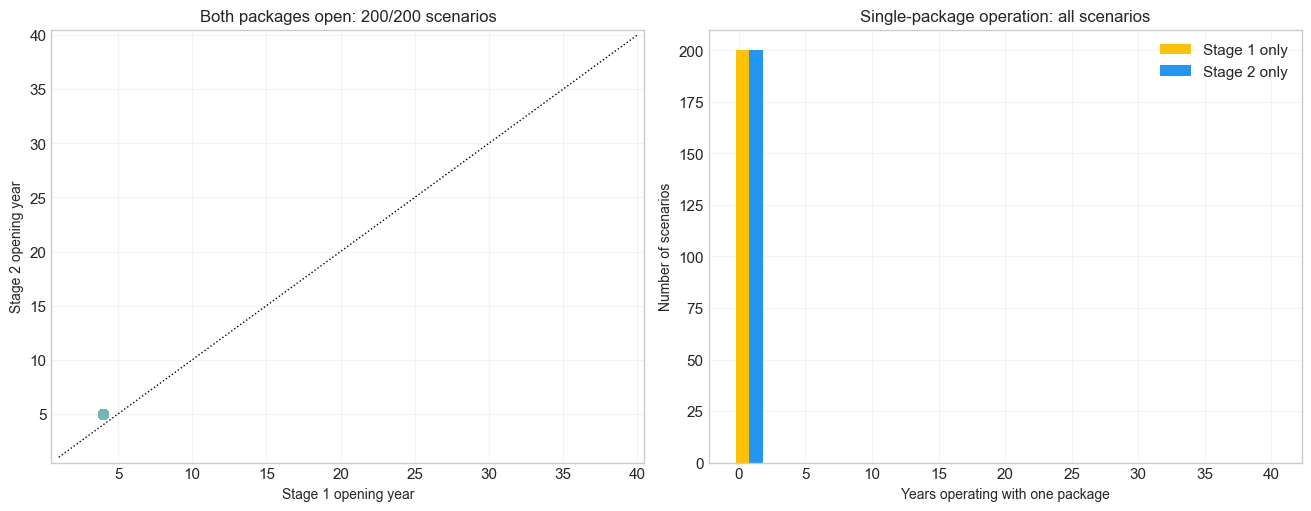

In [32]:
timing = summary_df.loc[summary_df["plan"] == "adaptive"].copy()
opened1 = timing["stage1_activation_year"].between(1, N_YEARS)
opened2 = timing["stage2_activation_year"].between(1, N_YEARS)
both_opened = timing.loc[opened1 & opened2]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
axes[0].scatter(both_opened["stage1_activation_year"], both_opened["stage2_activation_year"],
                color=PLAN_COLORS["adaptive"], alpha=.65, s=42)
axes[0].plot([1, N_YEARS], [1, N_YEARS], color="black", ls=":", lw=1)
axes[0].set(xlabel="Stage 1 opening year", ylabel="Stage 2 opening year",
            title=f"Both packages open: {len(both_opened)}/{len(timing)} scenarios",
            xlim=(.5, N_YEARS + .5), ylim=(.5, N_YEARS + .5))
if both_opened.empty:
    axes[0].text(.5, .6, "No scenario opens both packages", ha="center", transform=axes[0].transAxes)
axes[1].hist([timing[f"years_in_stage{STATIONS_STATE}"], timing[f"years_in_stage{TUNNEL_STATE}"]],
             bins=np.linspace(-.5, N_YEARS + .5, min(N_YEARS + 2, 17)),
             label=["Stage 1 only", "Stage 2 only"],
             color=[CASE_STAGE_COLORS[STATIONS_STATE], CASE_STAGE_COLORS[TUNNEL_STATE]])
axes[1].set(xlabel="Years operating with one package", ylabel="Number of scenarios",
            title="Single-package operation: all scenarios")
axes[1].legend(fontsize=11)
for ax in axes:
    ax.grid(alpha=.2)
    ax.tick_params(labelsize=11)
opening_coverage = pd.DataFrame({"scenarios": [int((opened1 & opened2).sum()), int((opened1 & ~opened2).sum()),
                                           int((~opened1 & opened2).sum()), int((~opened1 & ~opened2).sum())]},
                                index=["Both open", "Only Stage 1 open", "Only Stage 2 open", "Neither open"])
opening_coverage["share_percent"] = 100 * opening_coverage["scenarios"] / len(timing)
show_table("05_5_opening_coverage", opening_coverage.round(1))
exports.save_outputs("05_5_package_openings", figure=fig, tables={"dates": implementation_df})
plt.show()


### Ordered pathways and representative construction timelines

Compare how often the adaptive plan follows each order of openings. Then inspect one actual sampled scenario from each observed route. The representative scenario has timing closest to the median dates for its route; its decision dates and construction periods remain a coherent, simulated pathway.

A single-package or no-opening route may still contain a commitment that completes beyond the horizon. The timeline and exported status table retain this distinction.

Each route has two timeline rows: Stage 1 above Stage 2.


cell running: 00:00

,scenarios,share_percent
route,,
Baseline → Stage 1 → Both,200,100.0
Baseline → Stage 2 → Both,0,0.0
Baseline → Both (simultaneous),0,0.0
Baseline → Stage 1 only,0,0.0
Baseline → Stage 2 only,0,0.0
No package open within horizon,0,0.0


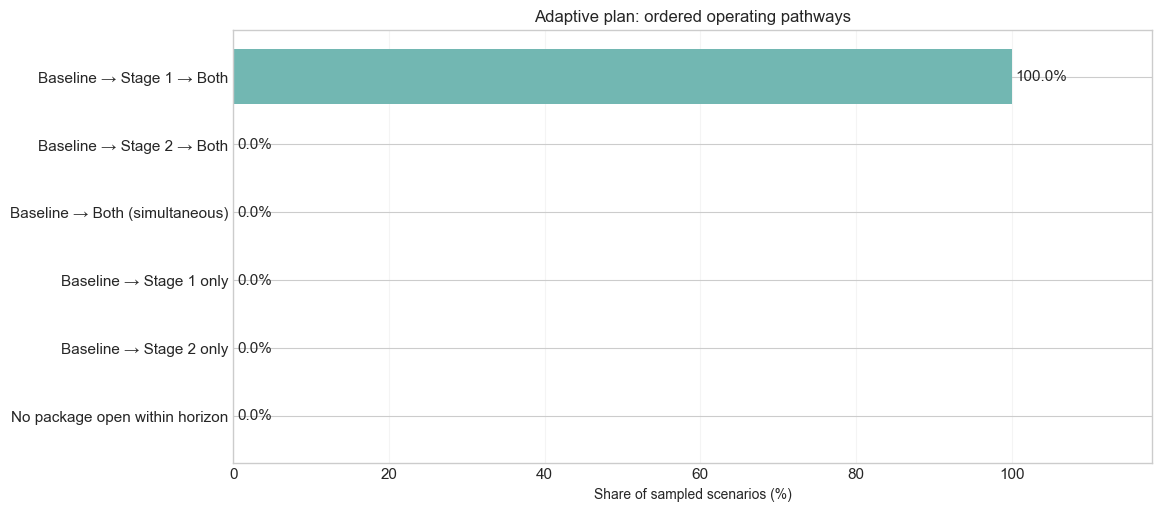

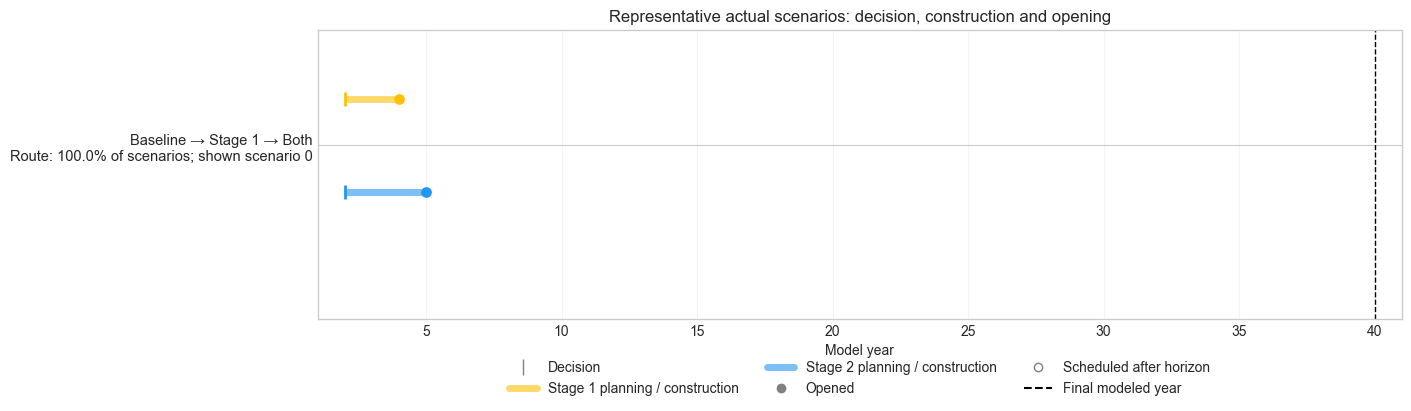

In [33]:
adaptive_paths = summary_df.loc[summary_df["plan"] == "adaptive"].copy()


def realized_route(row):
    first = row["stage1_activation_year"]
    second = row["stage2_activation_year"]
    first_open = 0 < first <= N_YEARS
    second_open = 0 < second <= N_YEARS
    if first_open and second_open:
        if first < second:
            return "Baseline → Stage 1 → Both"
        if second < first:
            return "Baseline → Stage 2 → Both"
        return "Baseline → Both (simultaneous)"
    if first_open:
        return "Baseline → Stage 1 only"
    if second_open:
        return "Baseline → Stage 2 only"
    return "No package open within horizon"


route_order = ["Baseline → Stage 1 → Both", "Baseline → Stage 2 → Both", "Baseline → Both (simultaneous)",
               "Baseline → Stage 1 only", "Baseline → Stage 2 only", "No package open within horizon"]
adaptive_paths["route"] = adaptive_paths.apply(realized_route, axis=1)
route_table = adaptive_paths["route"].value_counts().reindex(route_order, fill_value=0).to_frame("scenarios")
route_table["share_percent"] = route_table["scenarios"] / len(adaptive_paths) * 100
show_table("05_5_realized_routes", route_table.round(1))

fig, ax = plt.subplots(figsize=(11.5, 5), layout="constrained")
bars = ax.barh(route_order[::-1], route_table["share_percent"].iloc[::-1], color=PLAN_COLORS["adaptive"])
for bar in bars:
    ax.text(bar.get_width() + .5, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1f}%", va="center", fontsize=11)
ax.set(xlabel="Share of sampled scenarios (%)", title="Adaptive plan: ordered operating pathways",
       xlim=(0, max(10, route_table["share_percent"].max() * 1.18)))
ax.tick_params(labelsize=11)
ax.grid(axis="x", alpha=.2)
exports.save_outputs("05_5_pathway_frequencies", figure=fig, tables={"": route_table})
plt.show()


def representative_path(group):
    """Select an actual scenario close to its route's median commitment dates."""
    columns = [f"decision{package}_year" for package in IMPLEMENTATION_PACKAGES]
    columns += [f"stage{package}_scheduled_opening_year" for package in IMPLEMENTATION_PACKAGES]
    # This sentinel is used only for selecting a representative, never as a displayed date.
    dates = group[columns].where(group[columns].gt(0), N_YEARS + 1).astype(float)
    distance = (dates - dates.median()).abs().sum(axis=1)
    return group.loc[distance.idxmin()]


representatives = pd.DataFrame([
    representative_path(adaptive_paths.loc[adaptive_paths["route"] == route])
    for route in route_order if route_table.loc[route, "scenarios"] > 0
])
representative_dates = implementation_records(representatives).merge(
    representatives[["scenario", "route"]], on="scenario", validate="many_to_one")
from matplotlib.lines import Line2D
fig, ax = plt.subplots(figsize=(14, max(4, len(representatives) * 1.4)), layout="constrained")
tick_positions, tick_labels = [], []
for route_index, (_, scenario) in enumerate(representatives.iterrows()):
    centre = 3 * route_index
    tick_positions.append(centre)
    tick_labels.append(f"{scenario['route']}\nRoute: {route_table.loc[scenario['route'], 'share_percent']:.1f}% of scenarios; shown scenario {scenario['scenario']}")
    for offset, (package, spec) in zip((-.4, .4), IMPLEMENTATION_PACKAGES.items()):
        row = representative_dates.loc[(representative_dates["scenario"] == scenario["scenario"]) &
                                       (representative_dates["package"] == package)].iloc[0]
        y = centre + offset
        color = CASE_STAGE_COLORS[spec["state"]]
        decision, scheduled, opening = row["decision_year"], row["scheduled_opening_year"], row["opening_year"]
        if np.isfinite(decision):
            if np.isfinite(scheduled):
                ax.plot([decision, scheduled], [y, y], color=color, lw=5, alpha=.6, solid_capstyle="butt")
            ax.scatter(decision, y, color=color, marker="|", s=100, linewidths=2, zorder=4)
            if np.isfinite(opening):
                ax.scatter(opening, y, color=color, marker="o", s=45, zorder=5)
            elif np.isfinite(scheduled):
                ax.scatter(scheduled, y, facecolors="white", edgecolors=color, marker="o", s=50, zorder=5)
            else:
                ax.text(decision + .5, y, "No opening recorded", va="center", fontsize=9)
        else:
            ax.text(1.5, y, spec["label"] + ": no decision within horizon", color=color, va="center", fontsize=10)
    ax.axhline(centre + 1.5, color="grey", lw=.5, alpha=.25)
ax.axvline(N_YEARS, color="black", ls="--", lw=1)
last_schedule = representative_dates["scheduled_opening_year"].max()
right_edge = max(N_YEARS + 1, float(last_schedule) + 1) if np.isfinite(last_schedule) else N_YEARS + 1
ax.set(xlabel="Model year", title="Representative actual scenarios: decision, construction and opening",
       xlim=(1, right_edge), ylim=(-1, len(representatives) * 3 - 1.5))
ax.set_yticks(tick_positions, tick_labels, fontsize=10.5)
ax.invert_yaxis()
ax.grid(axis="x", alpha=.2)
ax.legend(handles=[Line2D([], [], color="grey", marker="|", ls="none", markersize=11, label="Decision"),
                   Line2D([], [], color=CASE_STAGE_COLORS[STATIONS_STATE], lw=5, alpha=.6, label="Stage 1 planning / construction"),
                   Line2D([], [], color=CASE_STAGE_COLORS[TUNNEL_STATE], lw=5, alpha=.6, label="Stage 2 planning / construction"),
                   Line2D([], [], color="grey", marker="o", ls="none", label="Opened"),
                   Line2D([], [], color="grey", marker="o", markerfacecolor="white", ls="none", label="Scheduled after horizon"),
                   Line2D([], [], color="black", ls="--", label="Final modeled year")],
          fontsize=10, loc="upper center", bbox_to_anchor=(.5, -.1), ncol=3)
exports.save_outputs("05_5_representative_timelines", figure=fig,
                     tables={"dates": representative_dates, "all_scenarios": physical_inputs(adaptive_paths)})
plt.show()


### Interpreting pathways

Read the operating order together with construction commitments. A late opening may miss years of useful service while a "no decision" may avoid expenditure but leave a requirement unmet. Compare these routes with Section 5.4's timeliness results. The representative timelines illustrate actual scenarios and do not describe every scenario in their group.


## 5.6 The value and price of waiting (mandatory task)

Each point compares the adaptive plan with a predetermined plan in the **same scenario**. Positive vertical values mean lower present-value expenditure; positive horizontal values mean more years with at least one failed requirement. These are two separate outcomes, not a monetised welfare score.

Use `WAITING_COMPARATORS` at the top of this block to choose the reference plans. Interpret savings with the opening dates: later expenditure and shorter operation within the horizon reduce present-value spending. A package committed before Year 40 but opening afterwards is still a commitment; its opening-year CAPEX lies outside this accounting horizon.


cell running: 00:00

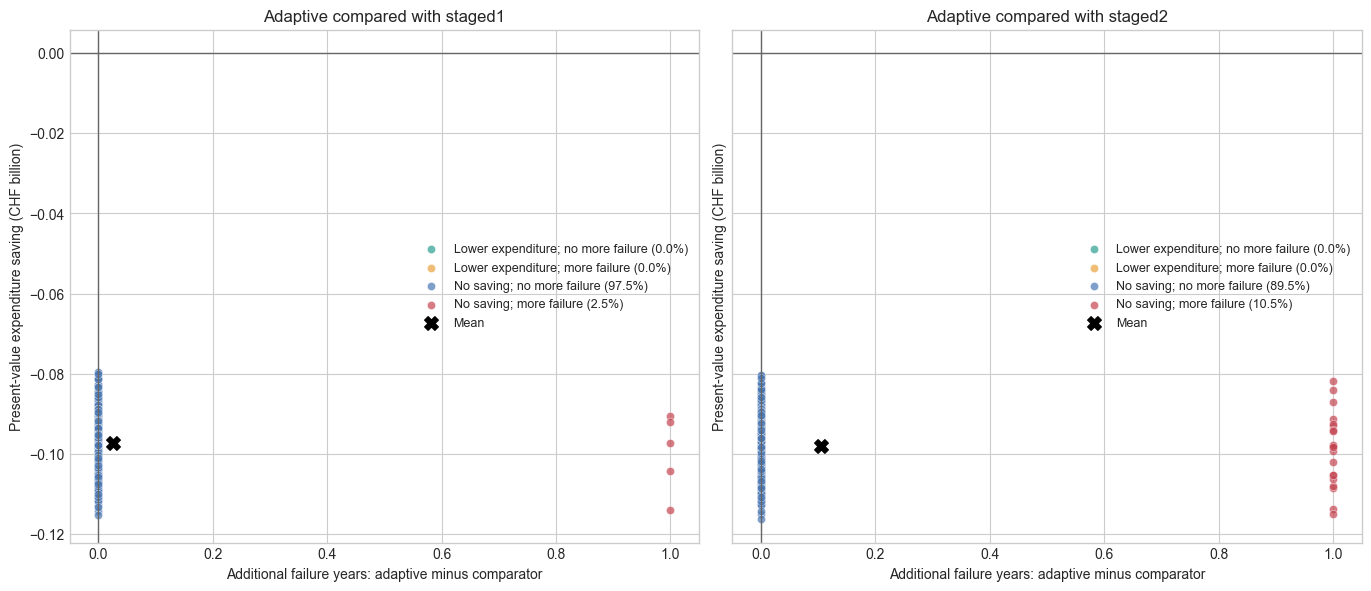

,mean_PV_saving_CHF,mean_additional_failure_years
comparator,,
staged1,-9.718605e+07,0.025
staged2,-9.798626e+07,0.105


In [34]:
# Select non-adaptive reference plans from PLAN_NAMES.
WAITING_COMPARATORS = ["staged1", "staged2"]

# Paired differences: positive savings mean the adaptive plan spends less.
if not WAITING_COMPARATORS or set(WAITING_COMPARATORS) - set(PLAN_NAMES) or "adaptive" in WAITING_COMPARATORS:
    raise ValueError("Choose at least one non-adaptive plan in WAITING_COMPARATORS.")
adaptive = summary_df.loc[summary_df["plan"].eq("adaptive")].set_index("scenario")
waiting_rows = []
for comparator in WAITING_COMPARATORS:
    other = summary_df.loc[summary_df["plan"].eq(comparator)].set_index("scenario")
    pair = adaptive[["total_cost", "years_in_failure"]].join(
        other[["total_cost", "years_in_failure"]], lsuffix="_adaptive", rsuffix="_comparator", validate="one_to_one")
    if pair.isna().any().any():
        raise ValueError("The comparison requires both plans for every scenario.")
    pair["PV_expenditure_saving_CHF"] = pair["total_cost_comparator"] - pair["total_cost_adaptive"]
    pair["additional_failure_years"] = pair["years_in_failure_adaptive"] - pair["years_in_failure_comparator"]
    cheaper = pair["PV_expenditure_saving_CHF"] > 1e-6
    no_worse = pair["additional_failure_years"] <= 0
    pair["comparison"] = np.select([cheaper & no_worse, cheaper & ~no_worse, ~cheaper & no_worse],
        ["Lower expenditure; no more failure", "Lower expenditure; more failure", "No saving; no more failure"],
        default="No saving; more failure")
    pair["comparator"] = comparator
    waiting_rows.append(pair.reset_index())
waiting_df = pd.concat(waiting_rows, ignore_index=True)
waiting_summary = waiting_df.groupby("comparator").agg(
    mean_PV_saving_CHF=("PV_expenditure_saving_CHF", "mean"),
    mean_additional_failure_years=("additional_failure_years", "mean"))
waiting_frequencies = pd.crosstab(waiting_df["comparator"], waiting_df["comparison"], normalize="index") * 100
fig, axes = plt.subplots(1, len(WAITING_COMPARATORS), figsize=(6.8 * len(WAITING_COMPARATORS), 5.8),
                         squeeze=False, layout="constrained", sharex=True, sharey=True)
waiting_colors = {"Lower expenditure; no more failure": "#2a9d8f", "Lower expenditure; more failure": "#e9a23b",
                  "No saving; no more failure": "#4776b4", "No saving; more failure": "#c44552"}
for ax, comparator in zip(axes.flat, WAITING_COMPARATORS):
    sub = waiting_df.loc[waiting_df["comparator"].eq(comparator)]
    for label, color in waiting_colors.items():
        points = sub.loc[sub["comparison"].eq(label)]
        ax.scatter(points["additional_failure_years"], points["PV_expenditure_saving_CHF"] / 1e9,
                   color=color, alpha=.7, s=35, edgecolors="white", linewidths=.4,
                   label=f"{label} ({100 * len(points) / len(sub):.1f}%)")
    ax.scatter(sub["additional_failure_years"].mean(), sub["PV_expenditure_saving_CHF"].mean() / 1e9,
               color="black", marker="X", s=95, label="Mean", zorder=5)
    ax.axhline(0, color="0.4", lw=1); ax.axvline(0, color="0.4", lw=1)
    ax.set(title=f"Adaptive compared with {comparator}", xlabel="Additional failure years: adaptive minus comparator",
           ylabel="Present-value expenditure saving (CHF billion)")
    ax.legend(fontsize=9, loc="best")
exports.save_outputs("05_6_value_and_price_of_waiting", figure=fig, tables={
    "scenarios": waiting_df, "summary": waiting_summary, "frequencies_percent": waiting_frequencies})
plt.show()
show_table("05_6_waiting_summary", waiting_summary)


## 5.7 Planner-in-the-loop interactive demonstration (tutorial/supporting task)

The game samples all selected scenario uncertainties, using the trajectory shapes selected in Section 2.5. Other drivers follow their nominal paths. `GAME_SEED` makes the exercise reproducible. The initial checkpoint appears below as a figure and table. Open the optional controls to wait, start either package, or start both.

Each checkpoint is a completed year's observation. A decision takes effect in the next year; the package opens after its configured lead time. Both packages can be under construction together. Review the configured monitoring indicators and performance indicators before deciding. At the final checkpoint, the scorecard reveals the hidden scenario.

The game and benchmark plans use the same paths and accounting conventions. Present-value infrastructure expenditure includes discounted CAPEX at opening and annual OPEX, with the option premium at time zero. An opening after the model horizon has no in-horizon CAPEX; discuss that outstanding commitment when interpreting the scorecard. This exercise compares performance and expenditure; Notebook 05 appraises societal benefits and costs.


cell running: 00:00

Game seed 42; decision checkpoints: [1, 5, 10, 15, 20, 25, 30, 35]. Final reveal: Year 40.


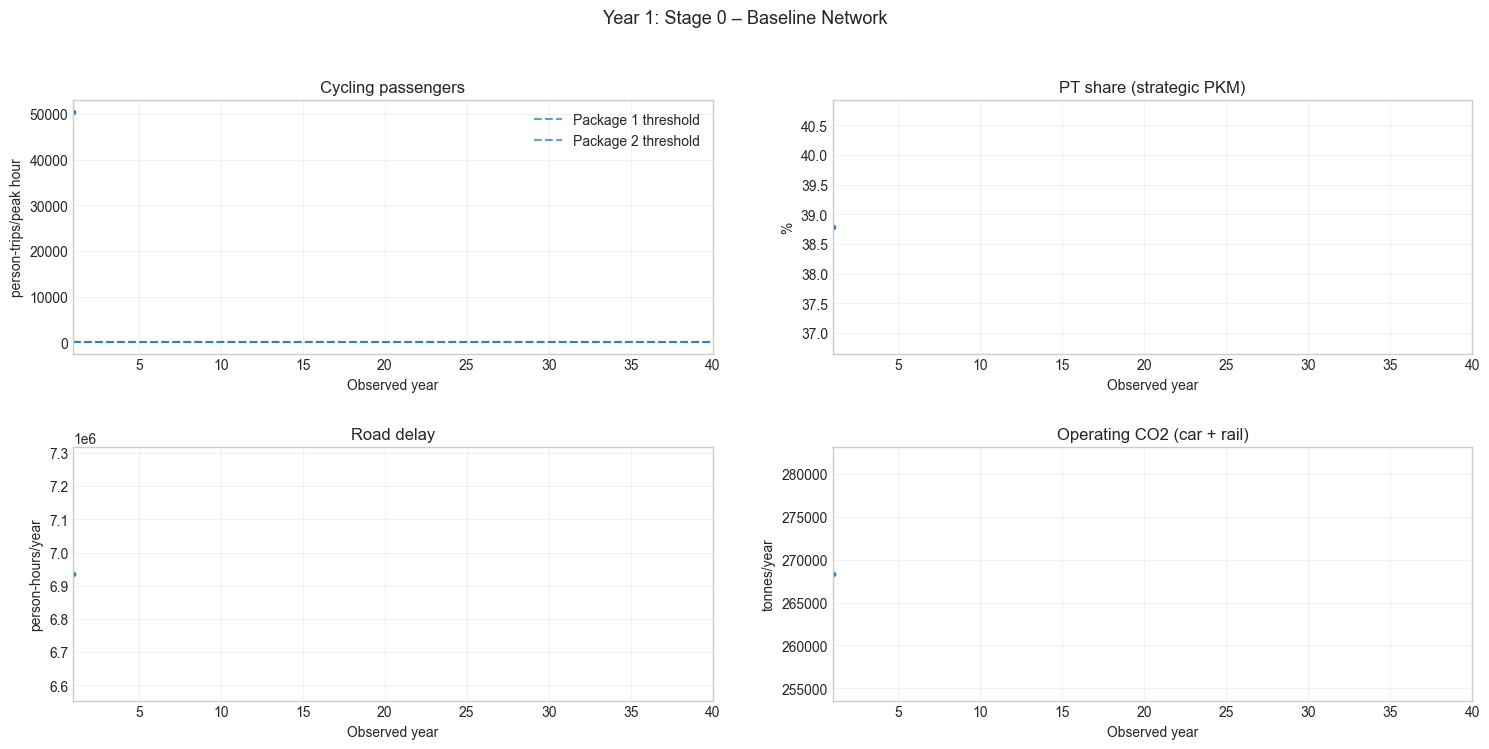

,package,scheduled_opening_year,currently_open
0,1,None,False
1,2,None,False


Decisions (effective year, packages): []
Acceptable observations so far: 100%.


Accordion(children=(VBox(children=(HBox(children=(Button(description='Wait', layout=Layout(width='170px'), sty…

In [35]:
GAME_SEED = 42  # Change and rerun this cell to play another reproducible scenario.
CHECKPOINTS = sorted({1, *range(5, N_YEARS, 5), N_YEARS})

def init_game(seed):
    rng = np.random.default_rng(seed)
    draws = {name: float(rng.uniform()) for name in SAMPLED_NAMES}
    shapes = SELECTED_SHAPES.copy()
    paths = uc.build_paths(draws, shapes=shapes, nominal=NOTEBOOK_PARAMS)
    return {"draws": draws, "shapes": shapes, "paths": paths, "stage": 0,
            "pending_stage1_year": None, "pending_stage2_year": None,
            "history": [], "built_assets": {}, "decisions": [], "year": 0,
            "checkpoint_idx": 0, "benchmark_cache": {}}

def simulate_up_to(target_year):
    for t in range(game_state["year"], target_year):
        year = t + 1
        stations_open, tunnel_open = stages_module.stage_components(game_state["stage"])
        stations_open |= game_state["pending_stage1_year"] == year
        tunnel_open |= game_state["pending_stage2_year"] == year
        stage = stages_module.state_for_components(stations_open, tunnel_open)
        paths = game_state["paths"]
        year_params = uc.year_parameters(paths, t, params=NOTEBOOK_PARAMS)
        transport_state = transport_emulator.predict_transport_state(
            stage=stage, include_welfare=False, **uc.transport_surrogate_inputs_from_paths(paths, t))
        investment = 0.0
        for package in (1, 2):
            if game_state[f"pending_stage{package}_year"] == year:
                paid = year_params[f"C_INV_STAGE{package}"] * year_params["CAPEX_MULTIPLIER"]
                investment += paid
                game_state["built_assets"][package] = (paid, year)
        operating = (year_params["C_INV_STAGE1"] * stations_open
                     + year_params["C_INV_STAGE2"] * tunnel_open) * year_params["OPEX_RATE"] * year_params["OPEX_MULTIPLIER"]
        row = m.simulate_year(
            transport_state["metrics"], stage, t, paths["PASSENGER_DEMAND_GROWTH"][t], year_params,
            transport_state=transport_state, inv_cost=investment, op_cost=operating,
            include_welfare=False, return_details=True,
            flex_cost=PLAN_SPECS["adaptive"]["upfront_fee"] * year_params["CAPEX_MULTIPLIER"] if year == 1 else 0.0)
        construction = [ap.construction_emissions_in_year(
            package, year, game_state[f"pending_stage{package}_year"], rule["lead_time"])
            for package, rule in ((1, TRIGGER_1), (2, TRIGGER_2))]
        row = m.add_construction_emissions(row, sum(value[0] for value in construction),
            sum(value[1] for value in construction), params=year_params)
        residual = sum(stages_module.asset_residual_value(package, paid, year - opened + 1)
            for package, (paid, opened) in game_state["built_assets"].items()) if year == N_YEARS else 0.0
        row.update(year=year, stage=stage, residual_value=residual,
                   appraisal_residual_version=m.APPRAISAL_RESIDUAL_VERSION)
        factors = m.annualizers(year_params)
        row["annual_pt_trips"] = row["pt_trips"] * factors["pt"]
        row["annual_car_trips"] = row["car_trips"] * factors["car"]
        row["total_cost"] -= residual
        game_state["history"].append(row)
        game_state["stage"] = stage
        game_state["year"] = year

def get_history_df():
    return add_indicators(pd.DataFrame(game_state["history"]))

def show_game_state():
    frame = get_history_df()
    indicators = indicator_selection(EXAMPLE_INDICATORS)
    monitoring_indicators = list(dict.fromkeys(rule["monitoring_indicator"] for rule in (TRIGGER_1, TRIGGER_2)))
    keys = list(dict.fromkeys(monitoring_indicators + indicators))
    fig, axes = plt.subplots((len(keys) + 1) // 2, 2,
                             figsize=(15, 3.8 * ((len(keys) + 1) // 2)), squeeze=False)
    for ax, key in zip(axes.flat, keys):
        scale = indicator_scale(key) if key in INDICATOR_CATALOG else 1.0
        if key in frame:
            ax.plot(frame["year"], frame[key] * scale, marker="o", markersize=3, lw=1.8)
        for package, rule in enumerate((TRIGGER_1, TRIGGER_2), 1):
            if rule["monitoring_indicator"] == key:
                ax.axhline(rule["threshold"] * scale, ls="--", alpha=.7, label=f"Package {package} threshold")
        ax.set(title=indicator_label(key) if key in INDICATOR_CATALOG else key,
               xlabel="Observed year", xlim=(1, N_YEARS),
               ylabel=indicator_unit(key) if key in INDICATOR_CATALOG else "")
        if ax.get_legend_handles_labels()[0]: ax.legend(fontsize=10)
        ax.grid(alpha=.25)
    for ax in list(axes.flat)[len(keys):]: ax.set_axis_off()
    fig.suptitle(f"Year {game_state['year']}: {CASE_STAGE_LABELS[game_state['stage']]}", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, .95), w_pad=3, h_pad=2.5)
    exports.save_outputs("05_7_planner_observations", figure=fig,
                         tables={"history": frame.select_dtypes(exclude="object")})
    plt.show(); plt.close(fig)
    status = pd.DataFrame([
        {"package": i, "scheduled_opening_year": game_state[f"pending_stage{i}_year"],
         "currently_open": stages_module.stage_components(game_state["stage"])[i - 1]}
        for i in (1, 2)])
    show_table("05_7_package_status", status)
    print("Decisions (effective year, packages):", game_state["decisions"])
    print(f"Acceptable observations so far: {performance_mask(frame).mean():.0%}.")

def apply_game_decision(packages):
    decision_year = game_state["year"] + 1
    for package in packages:
        if game_state[f"pending_stage{package}_year"] is not None:
            raise ValueError(f"Package {package} is already scheduled.")
    for package in packages:
        rule = TRIGGER_1 if package == 1 else TRIGGER_2
        game_state[f"pending_stage{package}_year"] = decision_year + rule["lead_time"]
    game_state["decisions"].append((decision_year, list(packages)))
    game_state["checkpoint_idx"] += 1
    simulate_up_to(CHECKPOINTS[game_state["checkpoint_idx"]])

game_state = init_game(GAME_SEED)
simulate_up_to(CHECKPOINTS[0])
print(f"Game seed {GAME_SEED}; decision checkpoints: {CHECKPOINTS[:-1]}. Final reveal: Year {N_YEARS}.")
show_game_state()

game_output = widgets.Output()
game_buttons = widgets.HBox([])

def update_game_buttons():
    for button in game_buttons.children: button.close()
    if game_state["checkpoint_idx"] >= len(CHECKPOINTS) - 1:
        game_buttons.children = []
        return
    available = [i for i in (1, 2) if game_state[f"pending_stage{i}_year"] is None]
    options = [("Wait", ())] + [(f"Start package {i}", (i,)) for i in available]
    if len(available) == 2: options.append(("Start both packages", (1, 2)))
    buttons = []
    for title, packages in options:
        button = widgets.Button(description=title, layout=widgets.Layout(width="170px"))
        def clicked(_, packages=packages):
            for current in game_buttons.children: current.disabled = True
            try:
                with game_output:
                    clear_output(wait=True)
                    try:
                        apply_game_decision(packages)
                        show_game_state()
                        if game_state["year"] == N_YEARS:
                            print("Horizon reached. Use the scorecard below to compare the completed paths.")
                    except Exception:
                        print("The game update could not finish. Review this message; rerun this cell to restart the same seed.")
                        traceback.print_exc()
                if "refresh_scorecard" in globals(): refresh_scorecard()
            finally:
                update_game_buttons()
        button.on_click(clicked)
        buttons.append(button)
    game_buttons.children = buttons

update_game_buttons()
game_controls = widgets.Accordion(children=[widgets.VBox([game_buttons, game_output])])
game_controls.set_title(0, "Optional: play the next checkpoint")
game_controls.selected_index = None
display(game_controls)


### Scorecard (tutorial/supporting task)

The table compares only the years observed so far. **Present-value infrastructure expenditure** discounts CAPEX at opening and annual OPEX, with the option premium at time zero. **Additional expenditure versus the lowest-spending benchmark** is the present-value spending difference over those same years. Read it alongside target attainment and failure duration; it does not measure overall policy quality.

Benchmark trajectories are reused throughout the game. The table updates after a decision; the refresh button also updates it manually. A provisional score excludes later expenditure and performance. At the final year, the hidden parameter endpoints and trajectory shapes are revealed. Notebook 05 provides the discounted welfare appraisal.


In [36]:
def scorecard_for(frame):
    acceptable = performance_mask(frame)
    return {"years_compared": len(frame),
        "final_state": CASE_STAGE_LABELS[int(frame["stage"].iloc[-1])],
        "infrastructure_expenditure_PV_MCHF": frame["comparison_cost"].sum() / 1e6,
        "construction_CO2_tonnes": frame["construction_co2_tonnes"].sum(),
        "years_in_failure": int((~acceptable).sum()),
        "acceptable_years_percent": acceptable.mean() * 100,
        **{f"final_{key}": frame[key].iloc[-1] for key in indicator_selection(EXAMPLE_INDICATORS) if key in frame}}

def game_benchmarks():
    cache = game_state["benchmark_cache"]
    if "infrastructure" not in cache:
        cache["infrastructure"] = {name: run_plan_from_trajectories_gp(name, STAGE_METRICS,
            extra_trajectories=game_state["paths"], params=NOTEBOOK_PARAMS)[0] for name in PLAN_SPECS}
    return cache["infrastructure"]

def show_scorecard():
    student = with_comparison_cost(get_history_df())
    last_year = int(student["year"].max())
    benchmarks = {name: frame.loc[frame["year"] <= last_year].copy() for name, frame in game_benchmarks().items()}
    cards = {"PLANNER PLAN": scorecard_for(student)}
    cards.update({name: scorecard_for(frame) for name, frame in benchmarks.items()})
    scoreboard = pd.DataFrame(cards).T
    costs = scoreboard["infrastructure_expenditure_PV_MCHF"].astype(float)
    best = costs.drop(index="PLANNER PLAN").idxmin()
    scoreboard["additional_PV_expenditure_vs_lowest_spending_benchmark_MCHF"] = costs - costs.loc[best]
    print(f"Years 1–{last_year}: present value of infrastructure expenditure. Lowest-spending benchmark: {best}.")
    if last_year < N_YEARS:
        print("Provisional: later expenditure and performance are excluded.")
    else:
        for name in game_state["draws"]:
            path = game_state["paths"][name]
            print(f"{name}: start {path[0]:.3f}, realised endpoint {path[-1]:.3f}, shape {game_state['shapes'][name]}.")
    show_table("05_7_planner_scorecard", scoreboard.round(3))
    return scoreboard

show_scorecard()
scorecard_button = widgets.Button(description="Refresh scorecard", button_style="primary")
scorecard_output = widgets.Output()

def refresh_scorecard():
    with scorecard_output:
        clear_output(wait=True)
        try: show_scorecard()
        except Exception:
            print("The scorecard could not be updated. Review the message below.")
            traceback.print_exc()

run_button(scorecard_button, scorecard_output, show_scorecard)
scorecard_controls = widgets.Accordion(children=[widgets.VBox([scorecard_button, scorecard_output])])
scorecard_controls.set_title(0, "Optional: refresh the scorecard")
scorecard_controls.selected_index = None
display(scorecard_controls)


cell running: 00:00

Years 1–1: present value of infrastructure expenditure. Lowest-spending benchmark: baseline.
Provisional: later expenditure and performance are excluded.


,years_compared,final_state,infrastructure_expenditure_PV_MCHF,construction_CO2_tonnes,years_in_failure,acceptable_years_percent,final_pt_share,final_congestion_delay_hours,final_operating_co2_tonnes,additional_PV_expenditure_vs_lowest_spending_benchmark_MCHF
PLANNER PLAN,1,Stage 0 – Baseline Network,106.917624,0.0,0,100.0,0.387846,6935586.719223,268333.971764,106.918
baseline,1,Stage 0 – Baseline Network,0.0,0.0,0,100.0,0.387846,6935586.719223,268333.971764,0.000
static1,1,STAGE 1 - Limmattal_bike_highway,30.783698,0.0,0,100.0,0.386891,6897699.227737,267824.703888,30.784
static2,1,Both stages - Cycleway + Underpasses,33.66789,0.0,0,100.0,0.385577,6857127.545059,266457.666777,33.668
staged1,1,STAGE 1 - Limmattal_bike_highway,30.783698,0.0,0,100.0,0.386891,6897699.227737,267824.703888,30.784
staged2,1,STAGE 1 - Limmattal_bike_highway,30.783698,0.0,0,100.0,0.386891,6897699.227737,267824.703888,30.784
adaptive,1,Stage 0 – Baseline Network,106.917624,0.0,0,100.0,0.387846,6935586.719223,268333.971764,106.918


Accordion(children=(VBox(children=(Button(button_style='primary', description='Refresh scorecard', style=Butto…

Additional present-value expenditure is measured against the lowest-spending benchmark over the same observed years. A negative value means the planner spent less than that benchmark. Compare this difference with the physical outcomes, requirement attainment and years in failure; the budget comparison is not a measure of net societal benefit.


# Summary — you're done with Notebook 04!

Below is a quick overview of what we've done in this notebook/phase 04. In Notebook 05 we will appraise these plans economically. Here's a quick summary of all the tasks:

Task types:
1. **M** = mandatory/expected (produces a definition, assumption, or result needed for the project)
2. **T** = tutorial/supporting (optional, builds understanding)
3. **A** = advanced (optional extension)

| § | Section | Task type |
|---|---|---|
| **Part 1 — Define the planning problem** | | |
| 1.1 | Plans, monitoring indicators, decisions, openings and performance failure | T |
| 1.2 | Select indicators, performance requirements and temporary monitoring rules | M |
| 1.3 | Package and plan definitions | M |
| 1.4 | Fixed schedules and independent adaptive pathways | T |
| 1.5 | Controlled trajectory timing | T |
| 1.6 | Detailed fan charts of sampled parameter paths | T |
| 1.7 | Consequences of trajectory timing | T |
| **Part 2 — Test the adaptive rules** | | |
| 2.0 | Compare potential monitoring indicators with performance and package effects | M |
| 2.1–2.2 | Validate plan behaviour and test temporary trigger rules | M |
| 2.3 | Compare all plans under one scenario | T |
| 2.4 | Controlled shape comparison: implementation timing | T |
| 2.5 | Select final trajectory shapes for subsequent analyses | M |
| **Part 3 — Compare plans across scenarios** | | |
| 3.1 | Run the shared-scenarios ensemble | M |
| 3.2 | Outcome fan charts | M |
| 3.3 | Paired Year-40 changes relative to the baseline | T |
| 3.4 | Performance spread, median profiles and requirement-based robustness | M |
| **Part 4 — Diagnose failure and intervention needs** | | |
| 4.1–4.2 | Requirement-specific failures and adaptation tipping points | M |
| 4.4 | Restoration windows and construction-adjusted decision deadlines | M |
| 4.5–4.6 | PRIM for each vulnerability mechanism and comparison of boxes | A |
| **Part 5 — Evaluate and improve implementation** | | |
| 5.1 | Decisions, construction, openings and non-implementation | M (+ T) |
| 5.2 | Opening-time cohorts and performance for both packages | T |
| 5.4 | Both packages' openings against counterfactual failure dates | M |
| 5.5 | Package order, pathway frequencies and representative construction timelines | M |
| 5.6 | Paired expenditure savings and additional failure years: the value and price of waiting | M |
| 5.7 | Planning game and infrastructure expenditure scorecard | T |

The notebook compares static, staged and adaptive plans under shared sampled scenarios. Trigger crossings, decisions, openings and requirement failures are distinct events. An intervention may improve PT share while attracting more passengers and increasing pressure on capacity. Robustness describes target attainment across the sampled scenarios; it is not the same as central performance or minimum spending.

Notebook 05 appraises the plans economically using the same uncertainty definitions. It draws its own scenarios, so scenario numbers are not interchangeable. Completed exports are in `figures/04_adaptive_planning/` and `results/04_adaptive_planning/`. Exported uncertainty inputs are applied Year-40 values; missing event dates are blank.

Use the marked tasks and summary above to check your work. Contact the TAs if you have questions.


In [37]:
#total runtime notebook04
print(f"__NOTEBOOK_RUNTIME_SECONDS__={_time.perf_counter() - _NB_START:.3f}")
print(f"__NOTEBOOK_RUNTIME_MINUTES__={(_time.perf_counter() - _NB_START) / 60:.3f}")


cell running: 00:00

__NOTEBOOK_RUNTIME_SECONDS__=94.804
__NOTEBOOK_RUNTIME_MINUTES__=1.580
